In [33]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import platform
import re

from matplotlib.ticker import MultipleLocator
from natsort import natsorted 
from scipy.interpolate import interp1d, CubicSpline
from scipy.signal import savgol_filter, find_peaks

USER = os.getlogin()
if platform.system() == "Darwin":  # macOS
    ROOT_PREFIX = f"/Users/{USER}/"
elif platform.system() == "Windows":
    ROOT_PREFIX = f"C:/Users/{USER}/"
else:
    raise OSError(f"Unsupported operating system: {platform.system()}")
print("ROOT_PREFIX:", ROOT_PREFIX)

ROOT_PREFIX: C:/Users/Sagar/


#### Plotting config

In [20]:
label_fs  = 14
title_fs  = 14
tick_fs   = 14
legend_fs = 14

WL_MIN_SH = 450
WL_MAX_SH = 1000

#### Pathing / data file config

In [21]:
# Supercontinuum (SC) QPM peak data w/Ando OSA (higher dynamic range + better resolution than ocean optics spectrometer), albeit slow + painful to use.
# Used 100x Olympus VIS and NIR objectives for input and output coupling
# All measurements at 22C, and used a shortpass filter (FESH0950) to block fundamental. 
DATA_DIR = os.path.join(ROOT_PREFIX, "MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026")
fnames = natsorted([x_SH for x_SH in os.listdir(DATA_DIR) if x_SH.endswith(".csv")])

# For normalizing SC data w.r.t input SC power spectrum
OBJ_CAL_DIR                = os.path.join(ROOT_PREFIX, "MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/100x Olympus VIS and NIR Objective Calibration - 04-19-2026")
INPUT_SC_FPATH             = os.path.join(OBJ_CAL_DIR, "HP_OSA_900-1700nm_ResBW_0.1nm_sens_-60dBm_SC_IR_SPECTRUM_TE_OBJ_NIR_04-20-2026_14-48-08.csv") # 400-1700nm,  TE
YOKOGAWA_INPUT_SC_FPATH_TE = os.path.join(OBJ_CAL_DIR, "Yokogawa_AQ6375_1200-2400nm_TE_NIR_SC_NIR_OBJ_PANDAS.csv")                                    # 1200-2400nm, TE
YOKOGAWA_INPUT_SC_FPATH_TM = os.path.join(OBJ_CAL_DIR, "Yokogawa_AQ6375_1200-2400nm_TM_NIR_SC_NIR_OBJ_PANDAS.csv")                                    # 1200-2400nm, TM

# Transmission data for the dichroic and longpass filter used to filter the SC in these measurements. 
FELH1000_DI01_925_T_FPATH = os.path.join(DATA_DIR, "FF925-Di01_and_FELH1000_transmission.xlsx")

# Wavelength ranges for truncating the SC data for plotting and analysis.
# Based on the shortpass/longpass filter pairs used in the experiments for specific waveguides. 
TRUNC_RANGE_YB  = (1000, 1200)
TRUNC_RANGE_O   = (1200, 1420)
TRUNC_RANGE_C   = (1400, 2000)
TRUNC_RANGE_NIR = (1000, 2000)

# Design targets for Praevium_2799, 3-constant poling period devices. 
# The key thing to extract from this file is the constant poling period of each of the 4mm-long SH-CONST-PP devices.
PRAEVIUM_2799_3CONSTPP_DESIGN_TARGETS_FPATH = os.path.join(ROOT_PREFIX, "MIT Dropbox/Sagar Doshi/LN-NLO/poling-masks/Praevium_2799/Praevium_2799_2_3constant_poling_periods_05-05-2026_11-34-28.csv")
CHUNK_BAND_MAP = {
    "Yb" : "PP_CHUNK_1",
    "O" : "PP_CHUNK_2",
    "C" : "PP_CHUNK_3",
}

# These longitudinal Δk trajectories were computed using the F50. They are not trustworthy. TODO - deprecate this. 
PRAEVIUM_2799_LONGITUDINAL_DELK_DIR_16UM = os.path.join(ROOT_PREFIX, "MIT Dropbox/Sagar Doshi/LN-NLO/poling-masks/Praevium_2799/deltaK_trajectories_2799_WGWidth=1.6um__05-05-2026_09-24-52")
PRAEVIUM_2799_LONGITUDINAL_DELK_DIR_18UM = os.path.join(ROOT_PREFIX, "MIT Dropbox/Sagar Doshi/LN-NLO/poling-masks/Praevium_2799/deltaK_trajectories_2799_WGWidth=1.8um_02-07-2026_18-39-26")

# Fixed t_LN = 400nm sweep
# MODE_DATA_WG_WIDTH_1600NM_FPATH = os.path.join(ROOT_PREFIX, "MIT Dropbox/Sagar Doshi/MPBX_SIMS/tLN400_etch400_w1600_sw73_clad1350nmSiO2-11-19-10-11/tLN400_etch400_w1600_sw73_clad1350nmSiO2", 
#                                                "tLN400_etch400_w1600_sw73_clad1350nmSiO2_modes.csv")
# MODE_DATA_WG_WIDTH_1800NM_FPATH = os.path.join(ROOT_PREFIX, "C:/Users/Sagar/MIT Dropbox/Sagar Doshi/MPBX_SIMS/tLN400_etch400_w1800_sw73_clad1350nmSiO2-11-19-08-51/tLN400_etch400_w1800_sw73_clad1350nmSiO2",
#                                                "tLN400_etch400_w1800_sw73_clad1350nmSiO2_modes.csv")

# t_LN = 400 +- 10nm, W_WG = 1.7 +- 0.2um sweep data
MODE_DATA_SWEEP = os.path.join(ROOT_PREFIX, "MIT Dropbox/Sagar Doshi/MPBX_SIMS/tfln_sweep_2026-11-19-16-58/")
MODE_DATA_SWEEP_FPATHS = natsorted([os.path.join(MODE_DATA_SWEEP, f"{x}/{x}_modes.csv") for x in os.listdir(MODE_DATA_SWEEP) if os.path.isdir(os.path.join(MODE_DATA_SWEEP, x)) and x not in ['code', 'logs']])

In [ ]:
def parse_fname(fname):
    s_list = fname.removesuffix(".csv").split("_")
    result_dict = {
        'DevID': s_list[0][:-6],
        'DevNum': s_list[0][-2:],
        'TopWidth': s_list[1].split("-")[1],
        'RefLevel': s_list[2][4:],
        'SensMode': s_list[3],
        'SCInputType': s_list[4],
        'timestamp': s_list[5],
        'fpath' : os.path.join(DATA_DIR, fname)
    }

    return result_dict

def find_nearest(array, value):
    '''
    Uses np.argmin() to return idx of number closest to value in 1D-array.
    This doesn't take advantage of the fact that the arrays are sorted, but shouldn't matter for now.

    inputs: array (np.ndarray)
            value (float)
    
    outputs: idx (int)
    '''
    return (np.abs(array - value)).argmin()

In [23]:
result_dict_list = [parse_fname(fname) for fname in fnames]
df_sc_qpm_data               = pd.DataFrame(result_dict_list)

df_2799_design = pd.read_csv(PRAEVIUM_2799_3CONSTPP_DESIGN_TARGETS_FPATH, index_col="dev_idx")

#### Plot the supercontinuum input data taken across multiple OSAs

This data (the stitched) function is used to normalize the measured QPM spectra.

In [24]:
# Savgol smoothing filter parameters. 
# We smooth the input SC spectrum to reduce the addition of noise when normalizing QPM spectra to the input SC spectrum. 

SMOOTH_WINDOW_LENGTH_NM = 10.0 # Smooth over a 10.0nm window, adjust as needed based on noise level and desired smoothness
SMOOTH_POLY_ORDER       = 2

df_hp_te                       = pd.read_csv(INPUT_SC_FPATH)                           # 400-1700nm,  TE
df_hp_te['SH Wavelength [nm]'] = df_hp_te['Wavelength [nm]'] / 2.0
df_hp_te = df_hp_te.rename(columns={"Wavelength [nm]": "Fund Wavelength [nm]"})

df_yoko_te = pd.read_csv(YOKOGAWA_INPUT_SC_FPATH_TE)                                    # 1200-2400nm, TE
df_yoko_tm = pd.read_csv(YOKOGAWA_INPUT_SC_FPATH_TM)                                    # 1200-2400nm, TM

dwav_fund               = df_hp_te['Fund Wavelength [nm]'].diff().mean() # Average wavelength step size, used for interpolation and peak finding
smooth_window_length    = int(SMOOTH_WINDOW_LENGTH_NM // dwav_fund) # Smooth over a 10.0nm window, adjust as needed based on noise level and desired smoothness

input_sc = savgol_filter(df_hp_te['Power [dBm]'], window_length=smooth_window_length, polyorder=SMOOTH_POLY_ORDER) # Smooth the input SC spectrum to reduce noise in the normalization function
input_sc = 10**(input_sc/10)
input_sc = input_sc - np.min(input_sc) + 1e-7 # Shift so min is at 0, add small offset to avoid log(0) issues
input_sc_linear = input_sc / np.max(input_sc) # Normalize so max is at 1
input_sc_dB = 10*np.log10(input_sc_linear) # Convert to dB scale, now max is at 0 dB and min is at some negative dB value

# HP OSA
input_sc_norm_func_dB = interp1d(df_hp_te['SH Wavelength [nm]'], input_sc_dB, kind='linear', fill_value="extrapolate")
def input_sc_norm_func_linear(wavs):
    return 10**(input_sc_norm_func_dB(wavs)/10)

# HP OSA, but extrapolating past lambda > 1700nm
HP_trunc_idx = -170
# display(df_hp_te['SH Wavelength [nm]'].values[HP_trunc_idx])
input_sc_norm_func_dB_HP_osa_broken = interp1d(df_hp_te['SH Wavelength [nm]'].values[:HP_trunc_idx], input_sc_dB[:HP_trunc_idx], kind='linear', fill_value="extrapolate")
def input_sc_norm_func_linear_HP_osa_broken(wavs):
    return 10**(input_sc_norm_func_dB_HP_osa_broken(wavs)/10)

# Stitch the HP OSA data with the Yokogawa to get a complete SC spectrum, 400-2400nm. 
wavs_yoko = df_yoko_te['Wavelength [nm]'].values / 2 # Switch from fund to SH wavelength for interpolator function.
amps_yoko = df_yoko_te['Power [dBm]'].values

dwav_fund               = df_yoko_te['Wavelength [nm]'].diff().mean() # Average wavelength step size, used for interpolation and peak finding
smooth_window_length    = int(SMOOTH_WINDOW_LENGTH_NM // dwav_fund) # Smooth over a 10.0nm window, adjust as needed based on noise level and desired smoothness

idx = np.argmin(np.abs(wavs_yoko - 1700/2))+1
wavs_yoko = wavs_yoko[idx:]
amps_yoko = amps_yoko[idx:]
amps_yoko_smooth_dB = savgol_filter(amps_yoko, window_length=smooth_window_length, polyorder=SMOOTH_POLY_ORDER)
amps_yoko_norm_dB = amps_yoko_smooth_dB + (input_sc_dB[-1] - amps_yoko_smooth_dB[0])

input_sc_func_stitched_dB = interp1d(np.concatenate([df_hp_te['SH Wavelength [nm]'].values, wavs_yoko]), np.concatenate([input_sc_dB, amps_yoko_norm_dB]), kind='linear', fill_value="extrapolate")
def input_sc_func_stitched_linear(wavs):
    return 10**(input_sc_func_stitched_dB(wavs)/10)

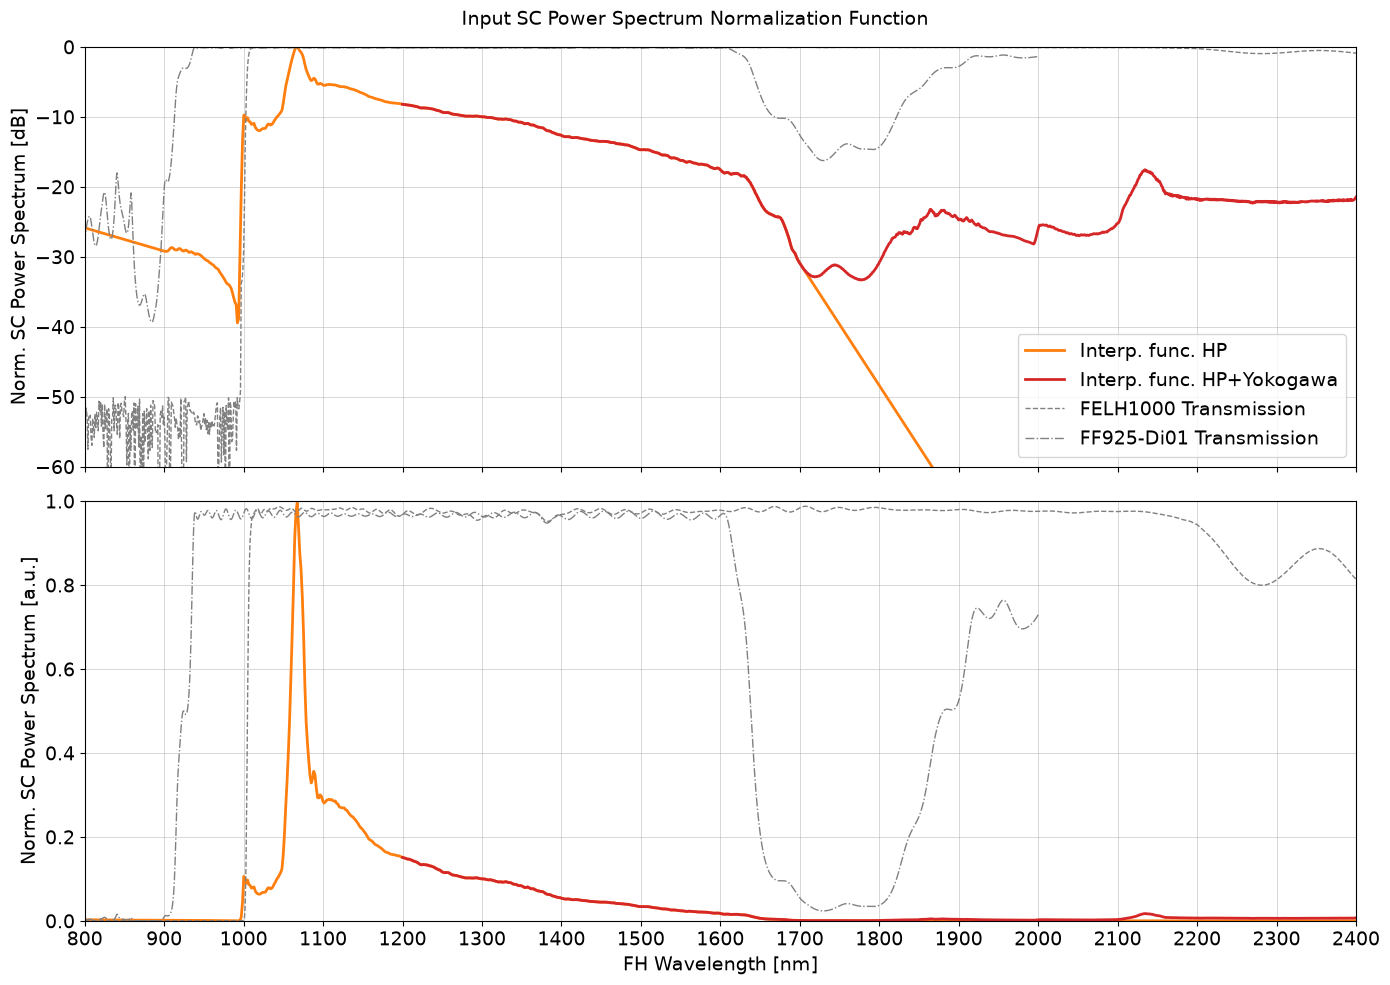

In [25]:
df_filters = pd.read_excel(FELH1000_DI01_925_T_FPATH, sheet_name='Sheet1')

wavs_felh1000 = df_filters['Thorlabs FELH1000 Wavelength (nm)'].values
t_felh1000 = df_filters['Thorlabs FELH Transmission'].values
t_dB_felh1000 = 10*np.log10(t_felh1000)

wavs_di01_925 = df_filters['FF925-Di01 Wavelength (nm)'].values
t_di01_925 = df_filters['FF925-Di01 Transmission'].values
t_dB_di01_925 = 10*np.log10(t_di01_925)

xmin, xmax, xstep = 800, 2400, 100
x_SH = np.linspace(xmin, xmax, 1000)/2 # For extrapolation

fig, axs = plt.subplots(2, 1, figsize=(14, 10), sharex=True, tight_layout=True)

# dB scale
axs[0].plot(x_SH*2.0, input_sc_norm_func_dB(x_SH), linewidth=2, 
            color='tab:orange', label='Interp. func. HP')
axs[0].plot(df_yoko_te['Wavelength [nm]'], input_sc_func_stitched_dB(df_yoko_te['Wavelength [nm]']/2.0), linewidth=2, 
            color='tab:red', label='Interp. func. HP+Yokogawa')

axs[0].plot(wavs_felh1000, t_dB_felh1000, linewidth=1, linestyle='--', 
            color='gray',  label='FELH1000 Transmission')
axs[0].plot(wavs_di01_925, t_dB_di01_925, linewidth=1, linestyle='-.',
            color='gray', label='FF925-Di01 Transmission')

axs[0].set_ylabel("Norm. SC Power Spectrum [dB]", fontsize=label_fs)
axs[0].tick_params(which='both', labelsize=tick_fs)

axs[0].grid(True, which='both', linestyle='-', linewidth=0.5, alpha=0.7)

axs[0].set_ylim(-60, 0)
axs[0].legend(loc='lower right', fontsize=legend_fs)

# Linear scale
axs[1].plot(x_SH*2.0, input_sc_norm_func_linear(x_SH), linewidth=2, 
            color='tab:orange', label='Interp. func. HP')
axs[1].plot(df_yoko_te['Wavelength [nm]'], input_sc_func_stitched_linear(df_yoko_te['Wavelength [nm]']/2.0), linewidth=2, 
            color='tab:red', label='Interp. func. HP+Yokogawa')

axs[1].plot(wavs_felh1000, t_felh1000, linewidth=1, linestyle='--', 
            color='gray',  label='FELH1000 Transmission')
axs[1].plot(wavs_di01_925, t_di01_925, linewidth=1, linestyle='-.',
            color='gray', label='FF925-Di01 Transmission')

axs[1].set_xlabel("FH Wavelength [nm]", fontsize=label_fs)
axs[1].set_ylabel("Norm. SC Power Spectrum [a.u.]", fontsize=label_fs)
axs[1].tick_params(which='both', labelsize=tick_fs)

axs[1].grid(True, which='both', linestyle='-', linewidth=0.5, alpha=0.7)

ymin, ymax, ystep = 0.0, 1.0, 0.2
axs[1].set_yticks(np.arange(ymin, ymax+ystep/2.0, ystep))
axs[1].set_ylim(ymin, ymax)

axs[1].set_xticks(np.arange(xmin, xmax+xstep/2.0, xstep))
axs[1].set_xlim(xmin, xmax)

fig.suptitle("Input SC Power Spectrum Normalization Function", fontsize=title_fs)

plt.show()

#### Plot the SH-CONST-PP SC QPM Spectra - raw data (linear/log)

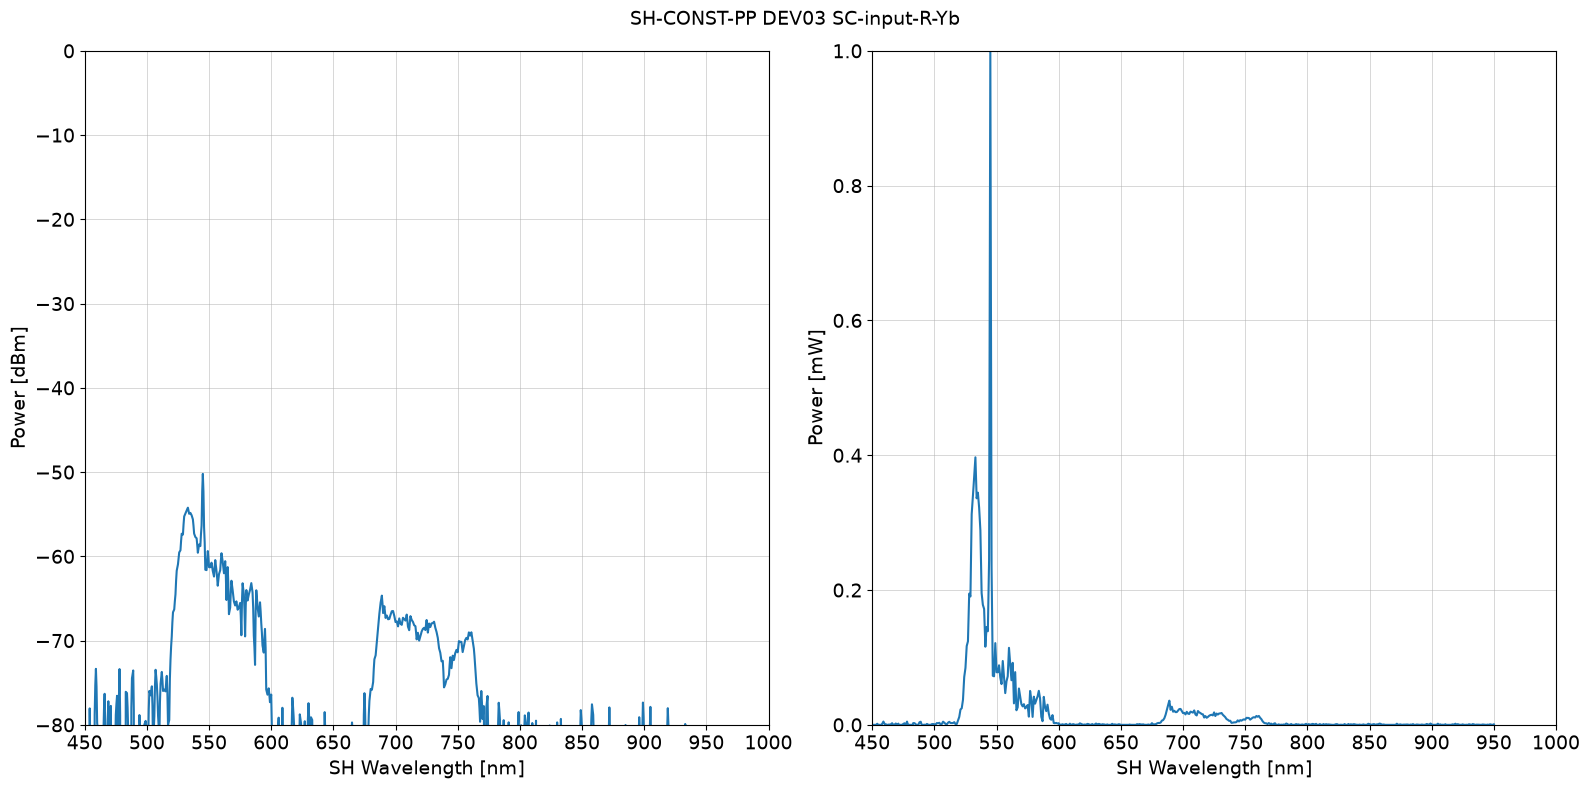

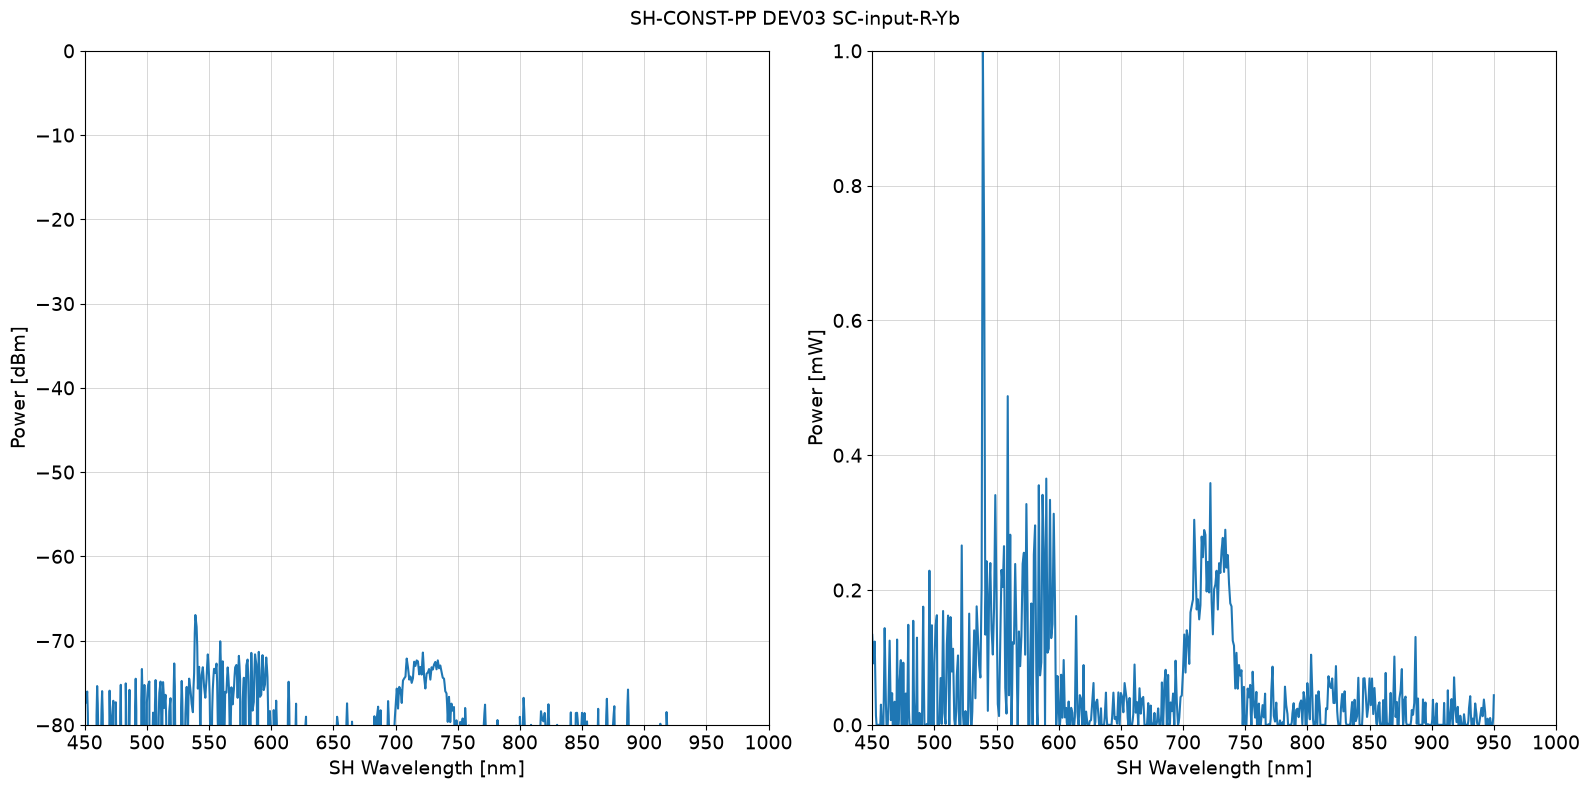

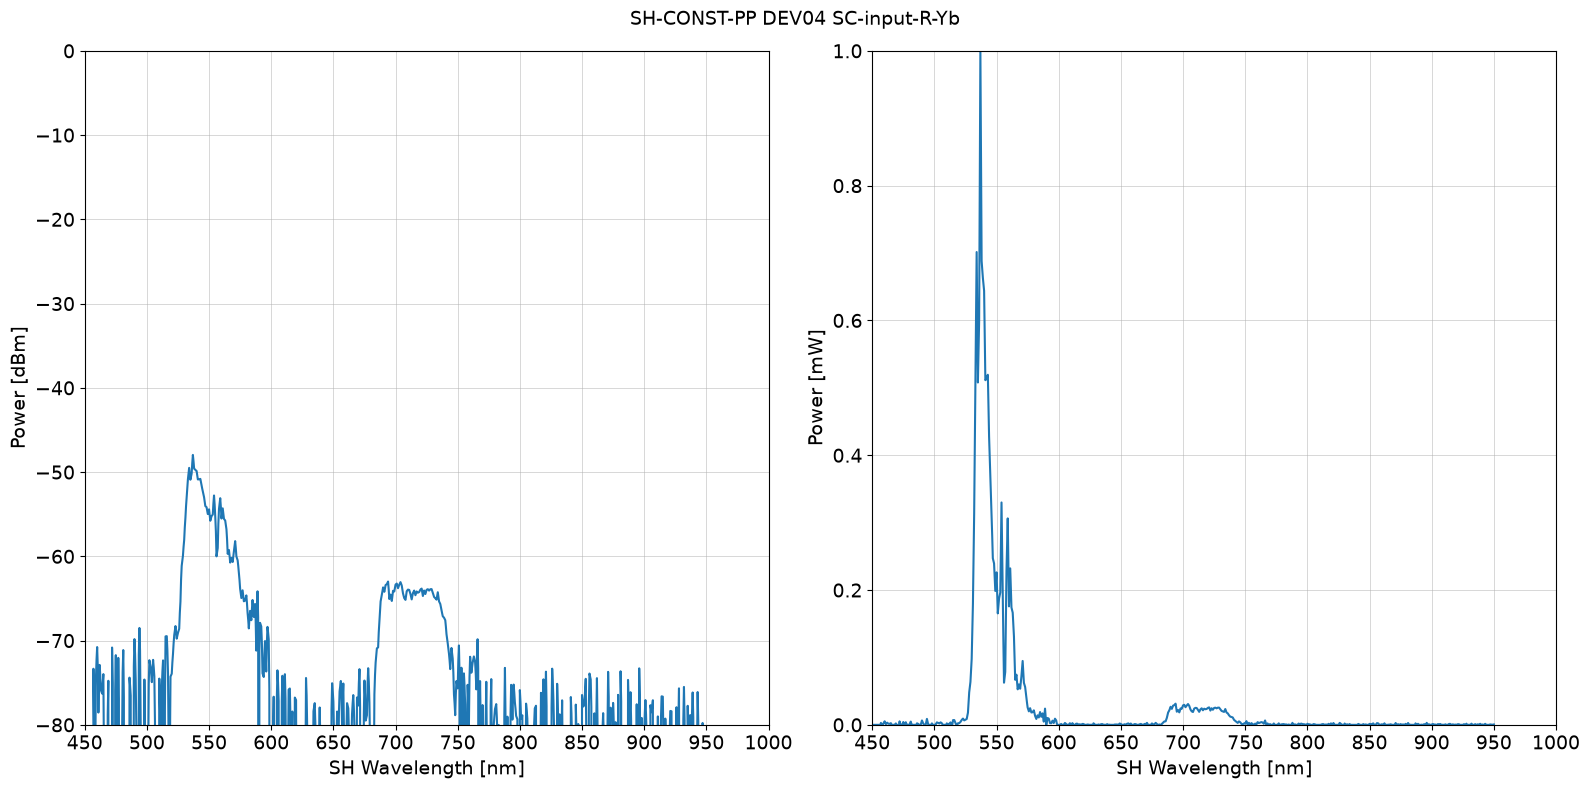

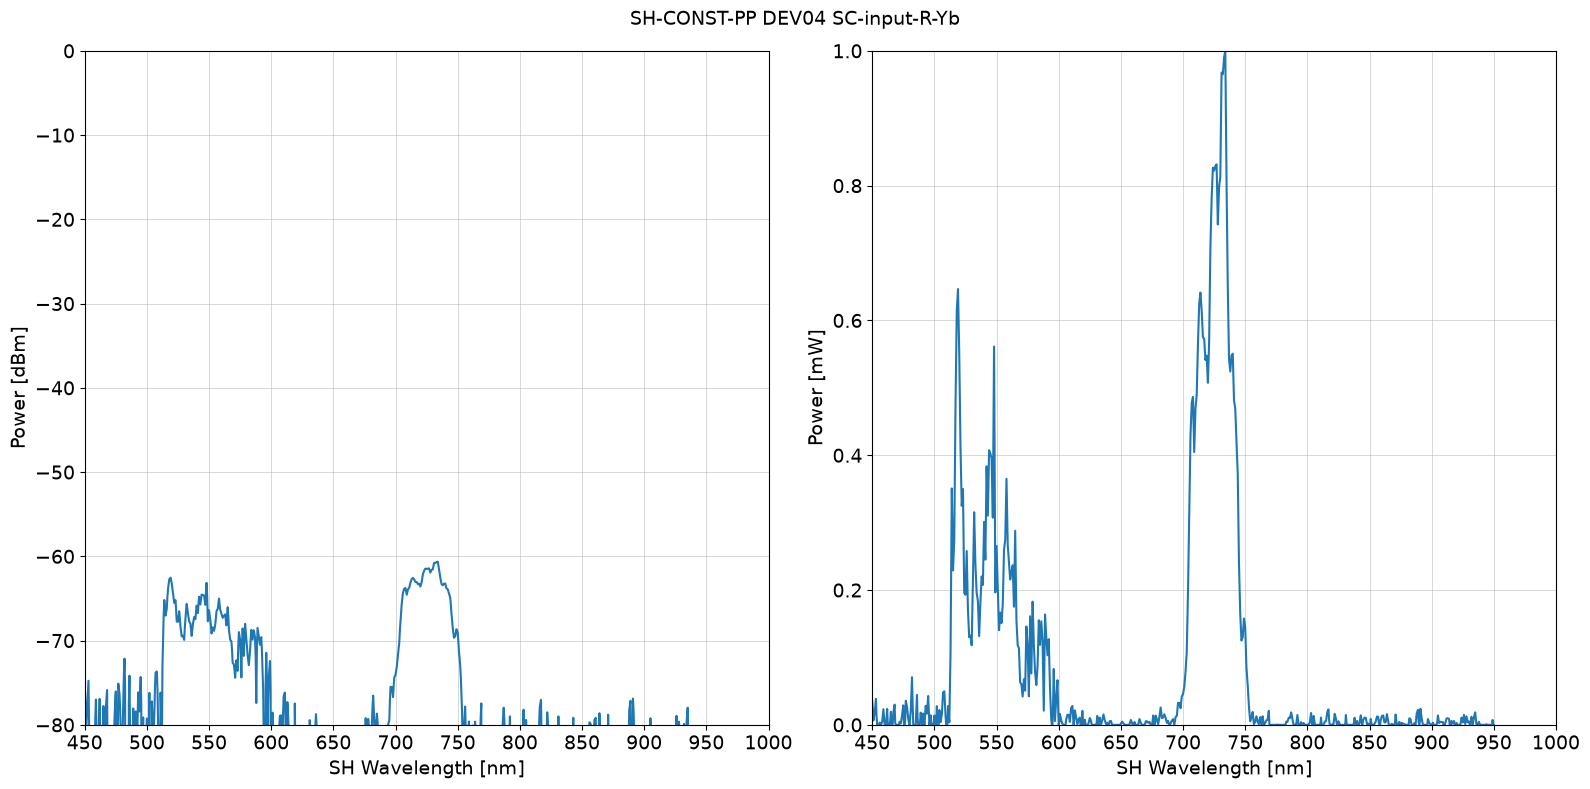

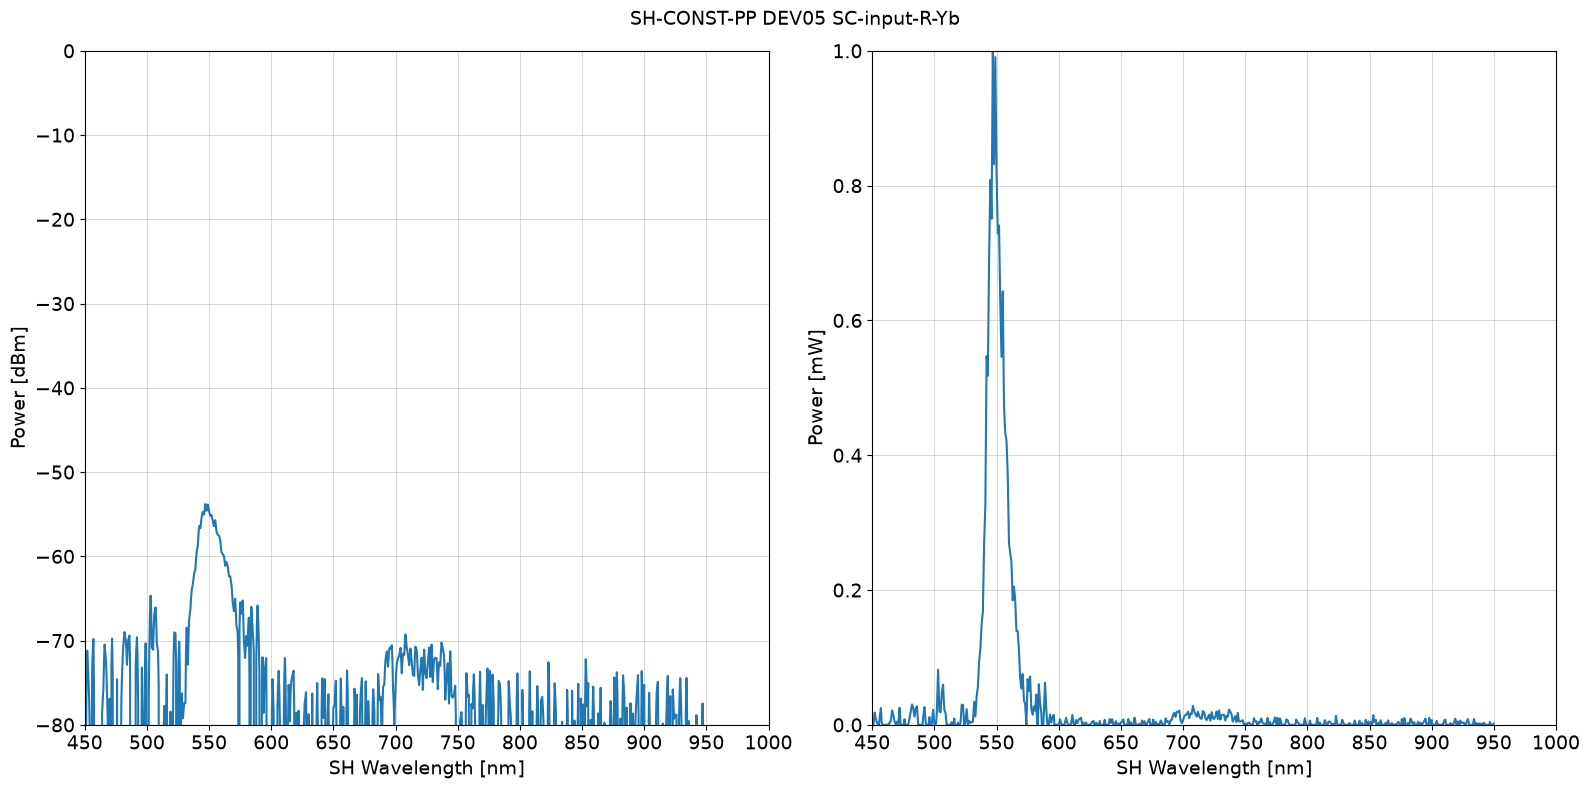

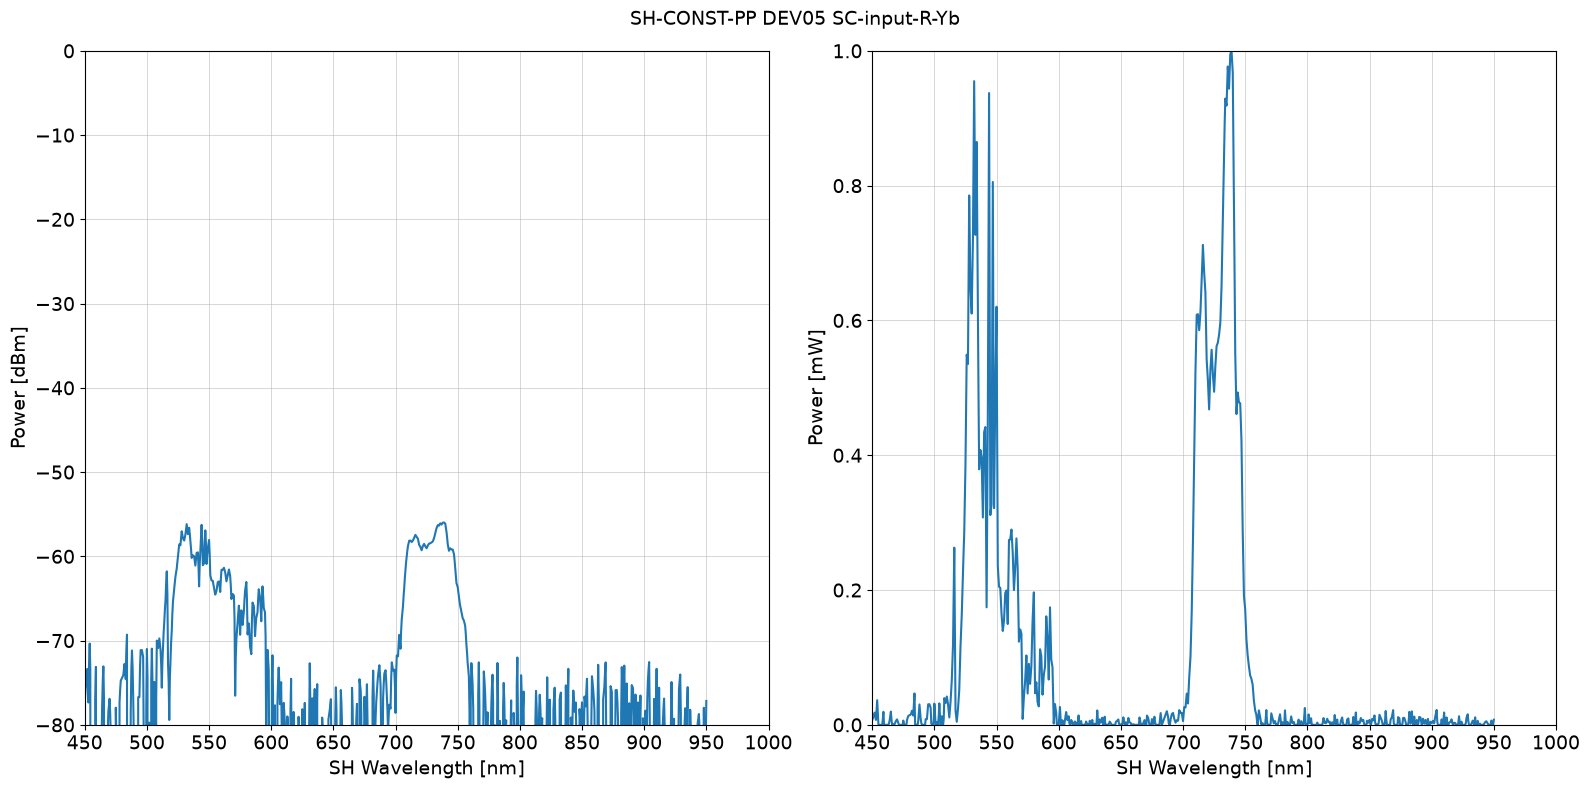

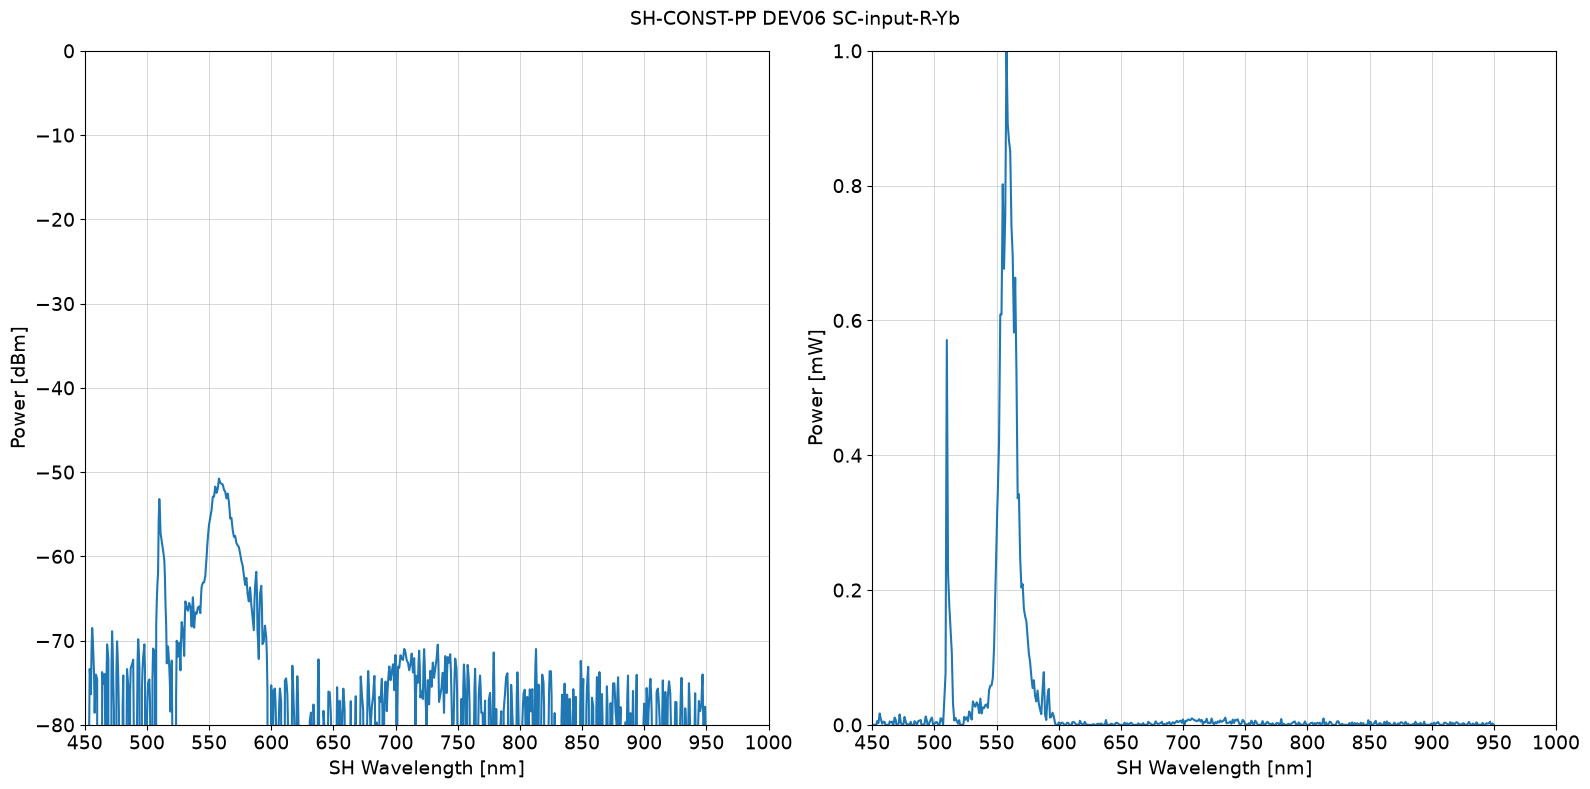

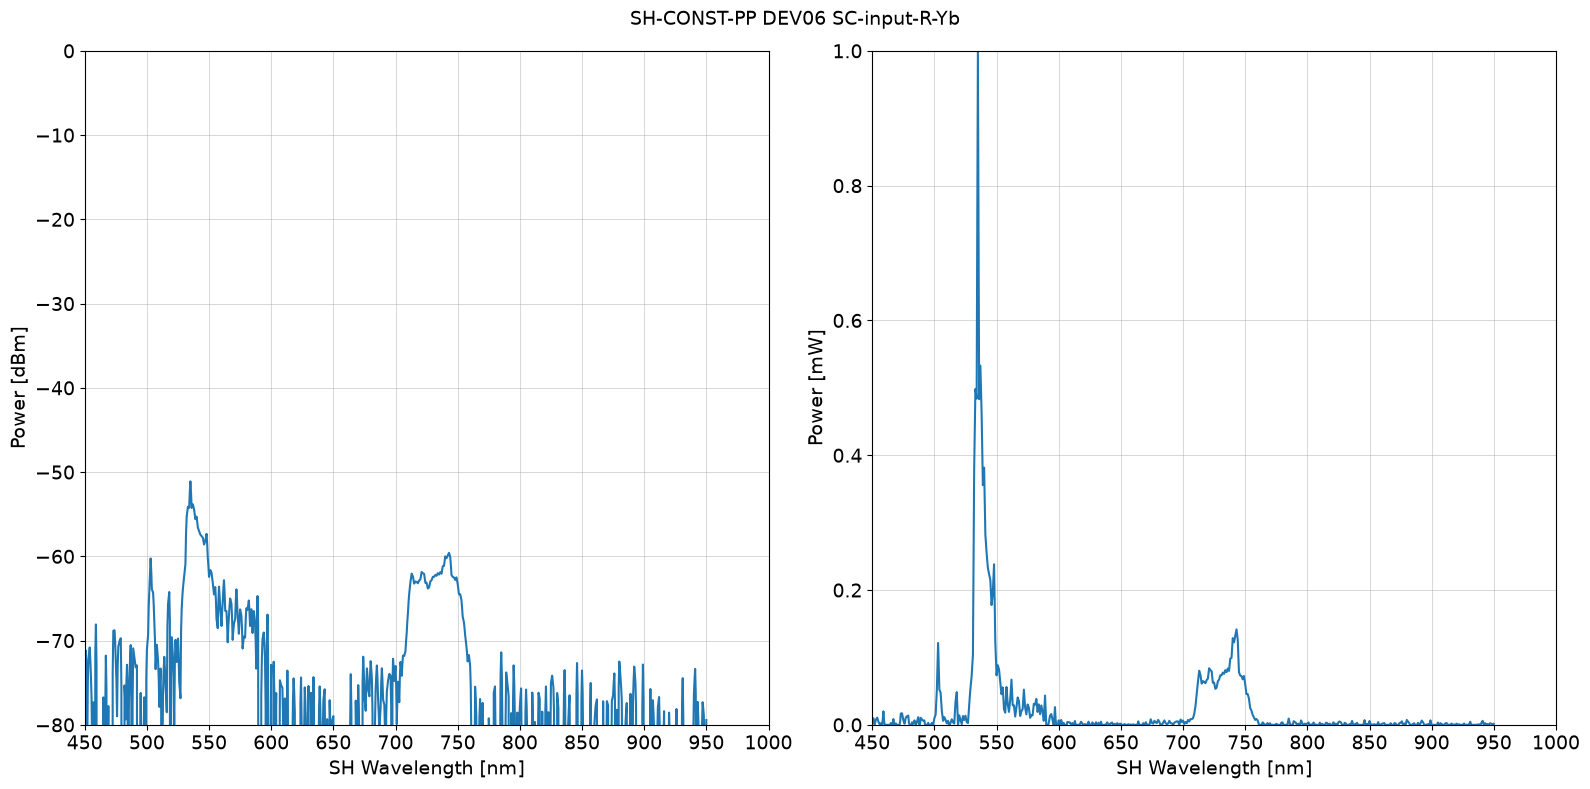

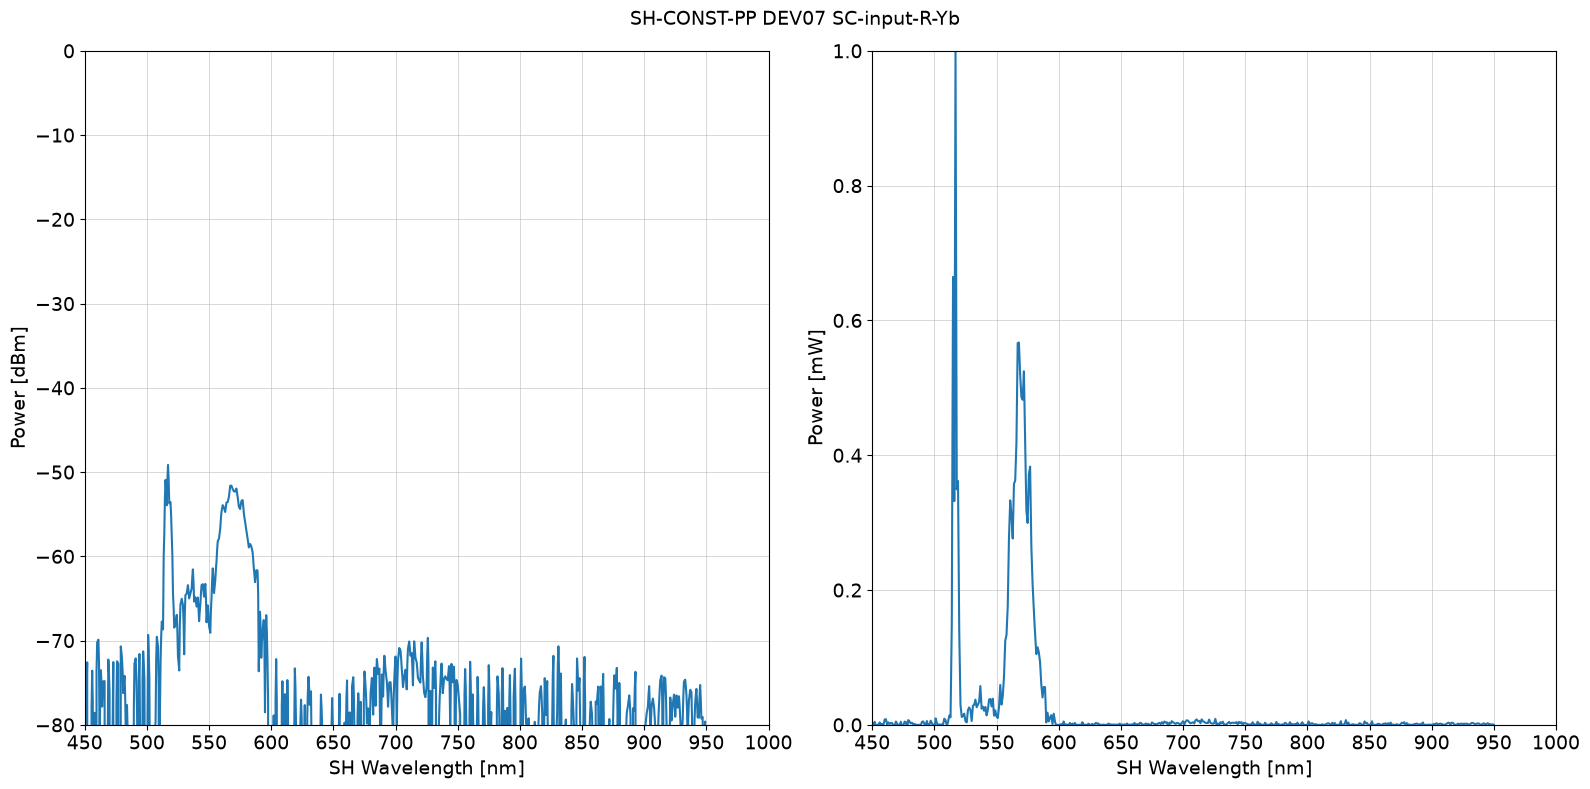

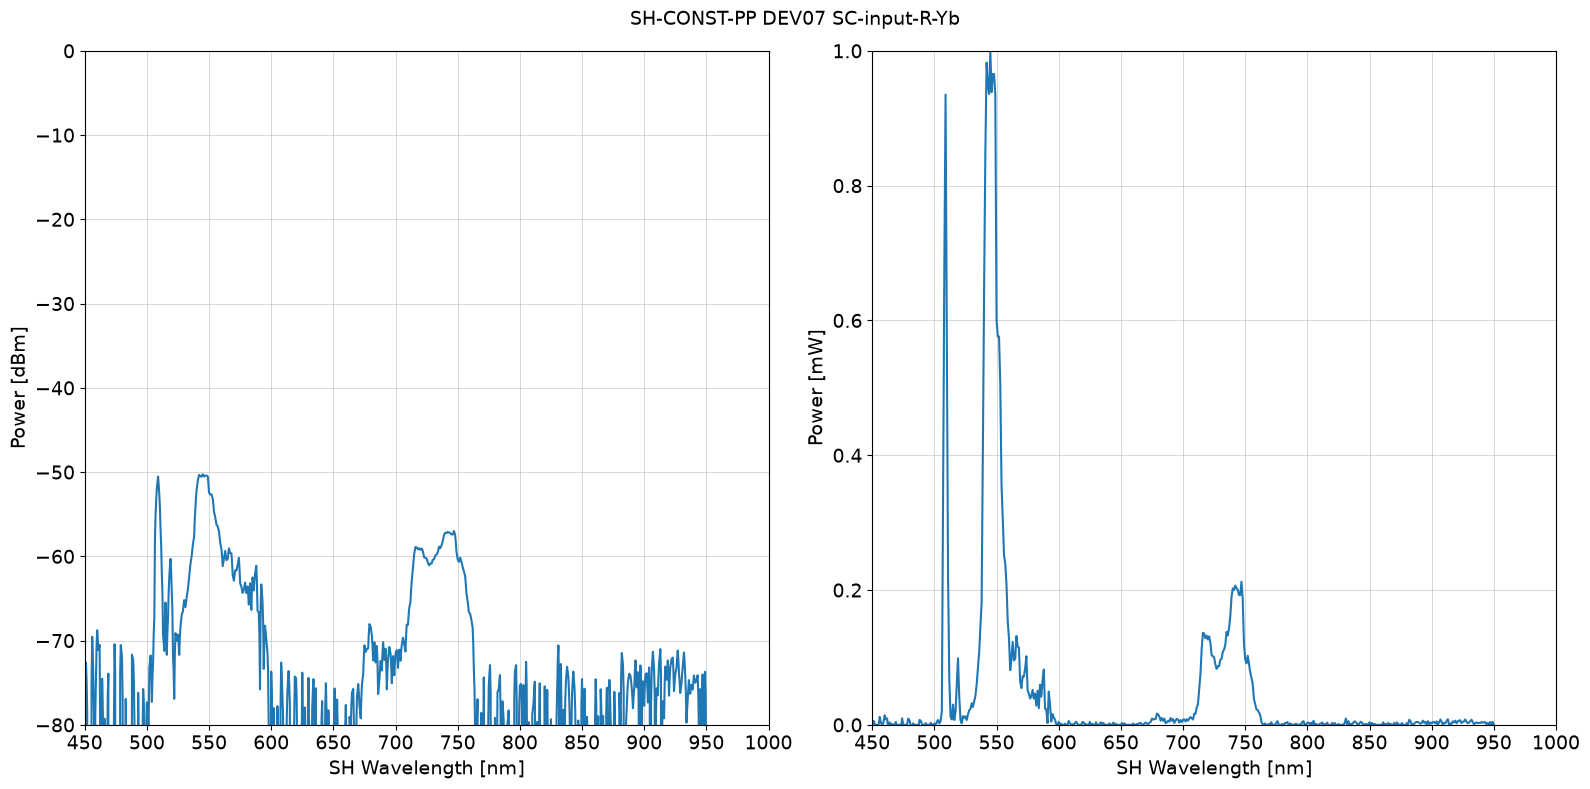

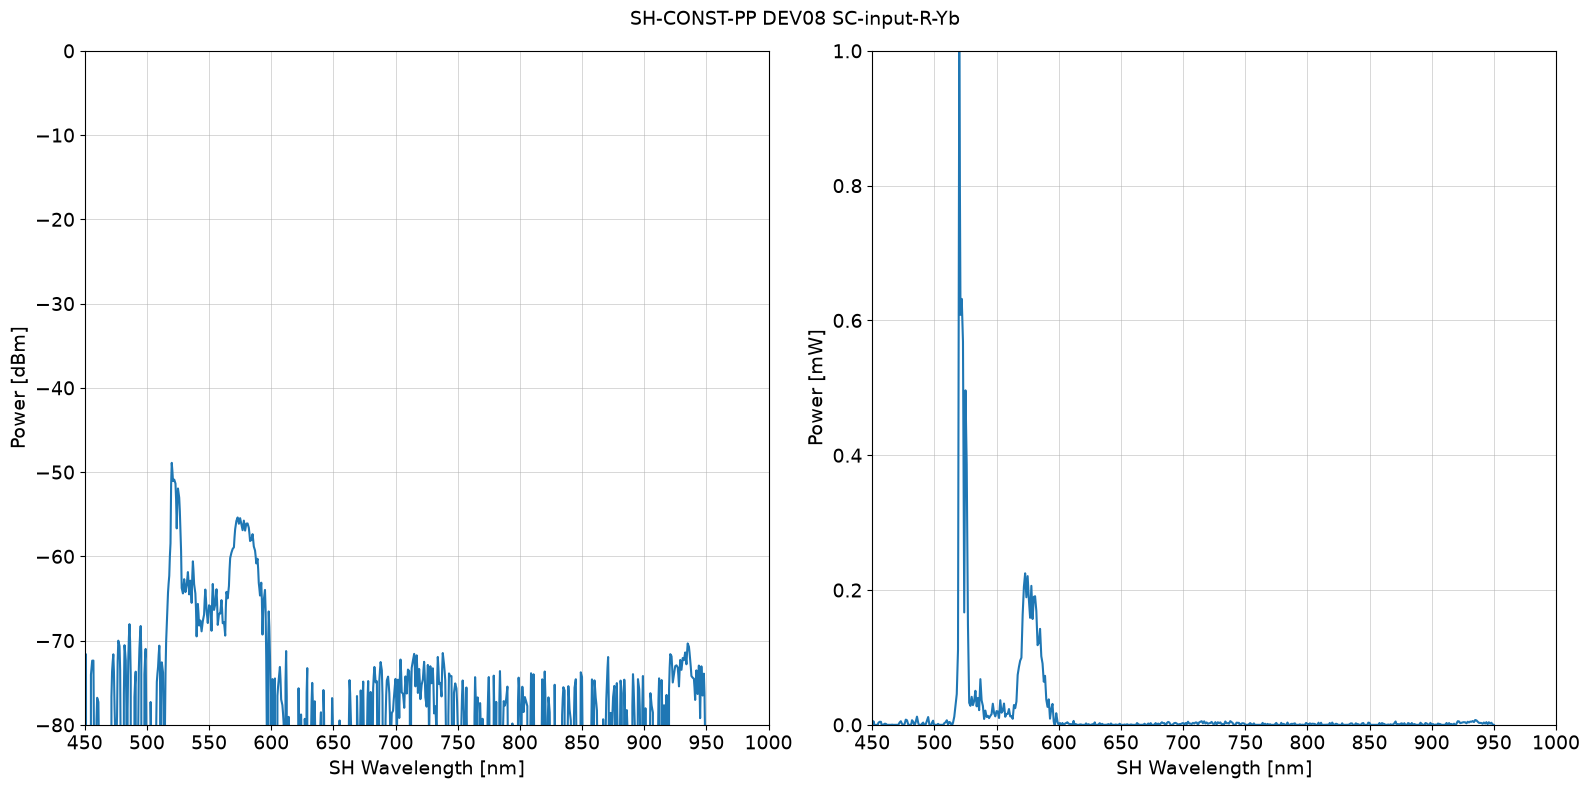

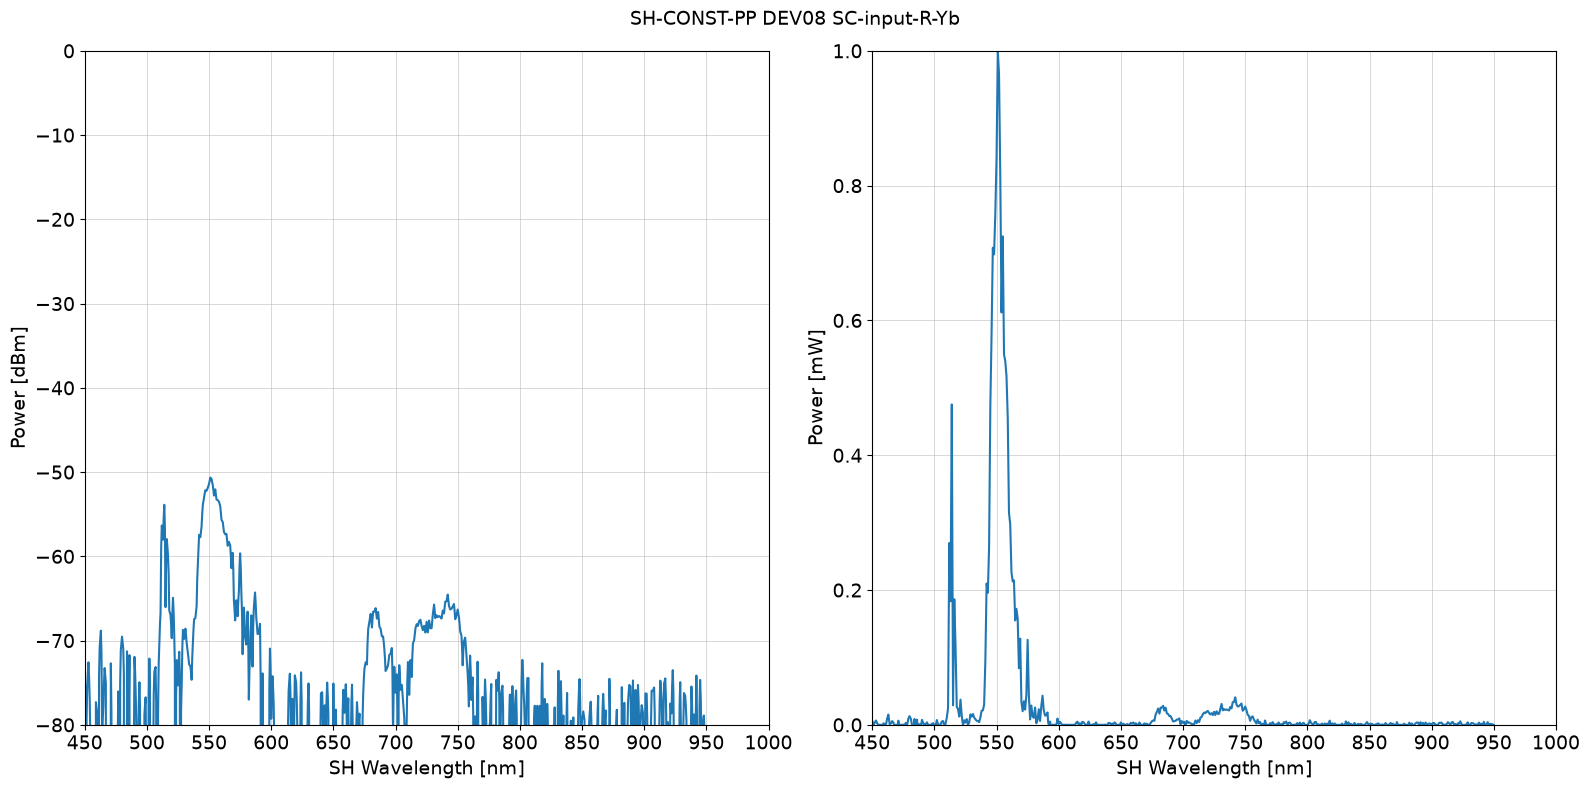

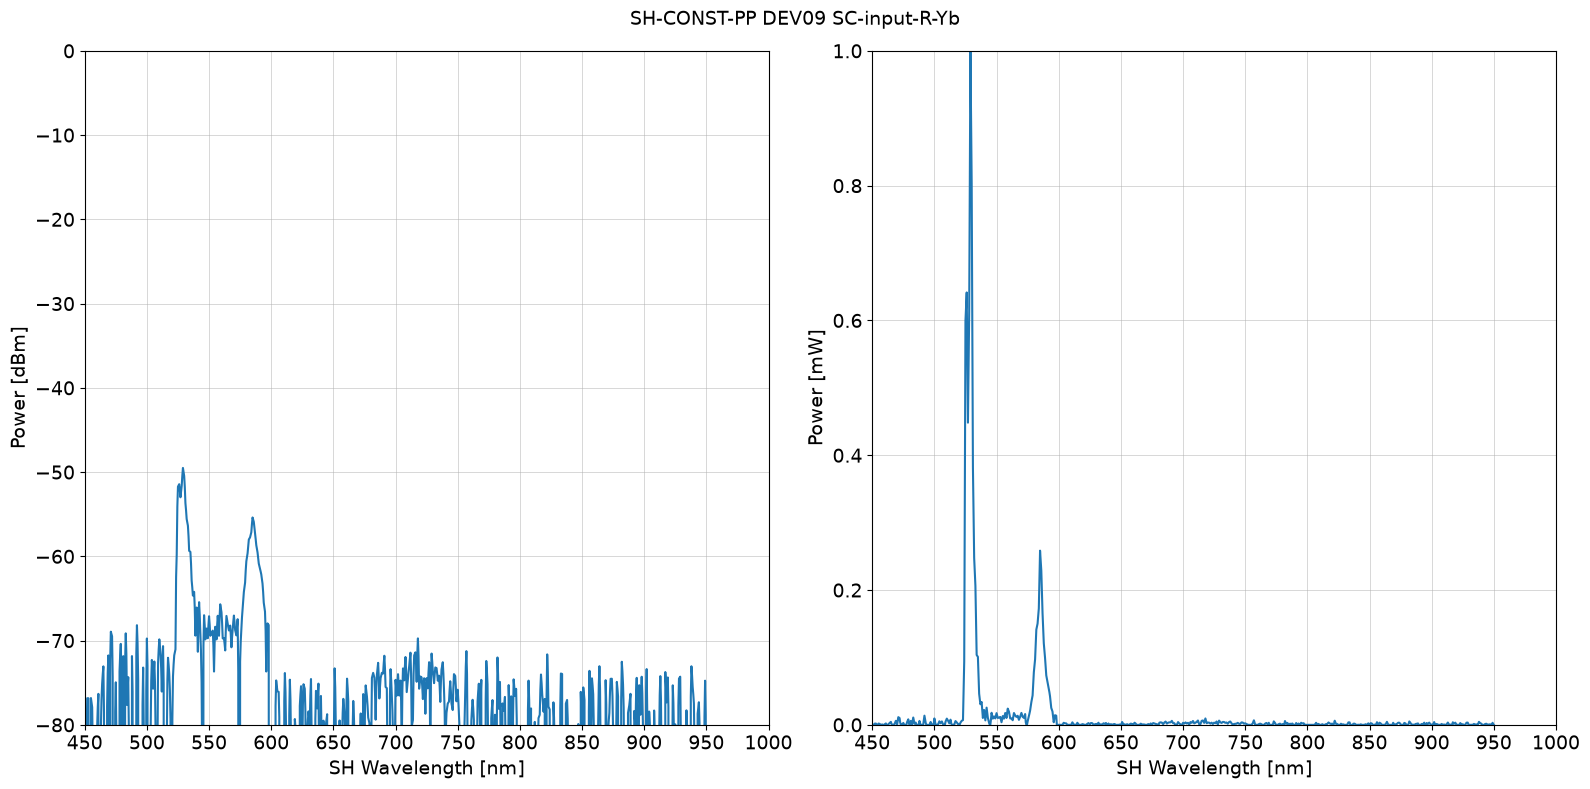

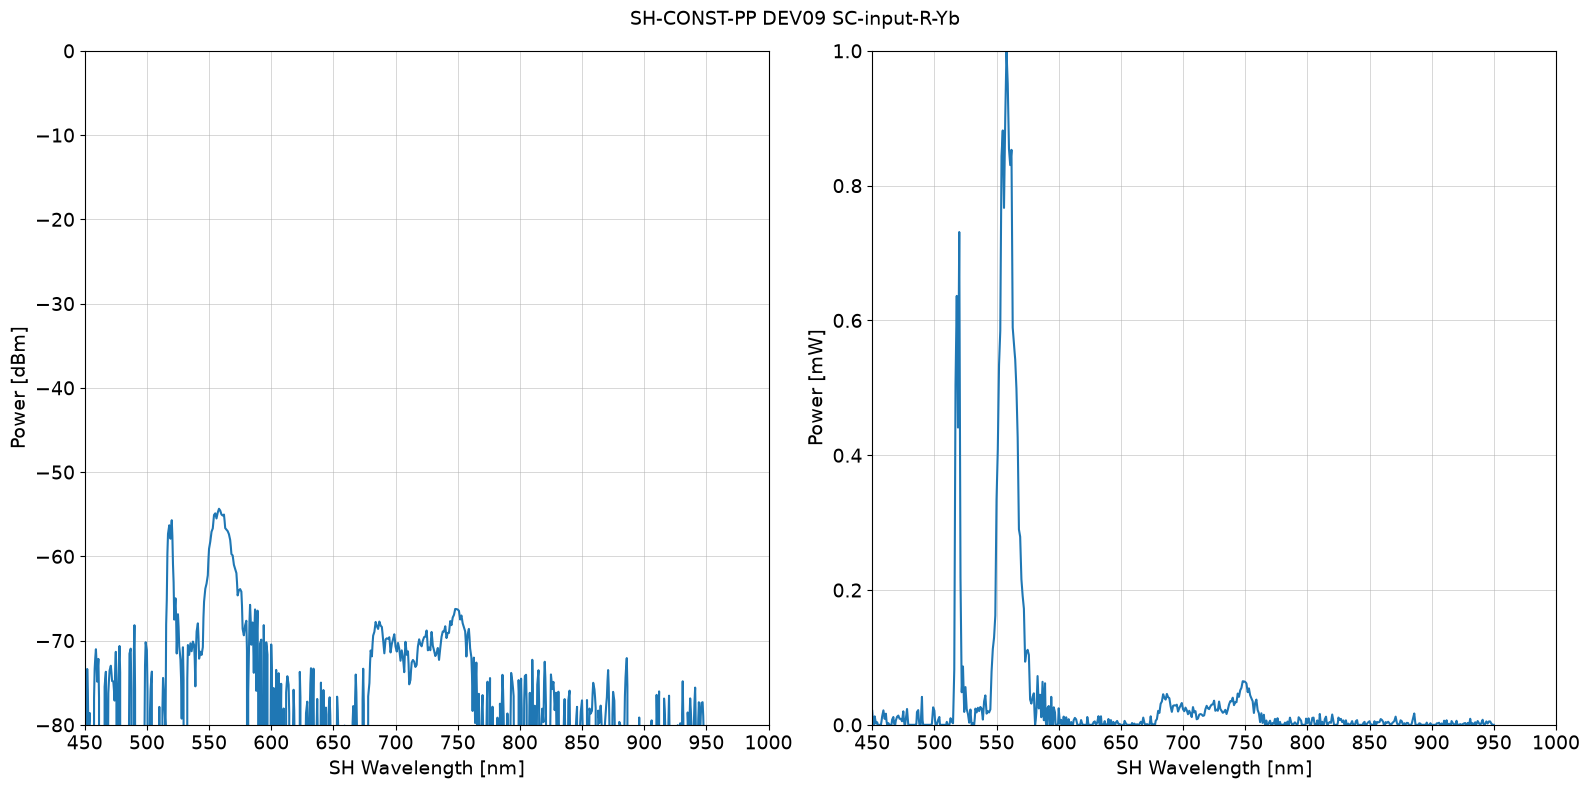

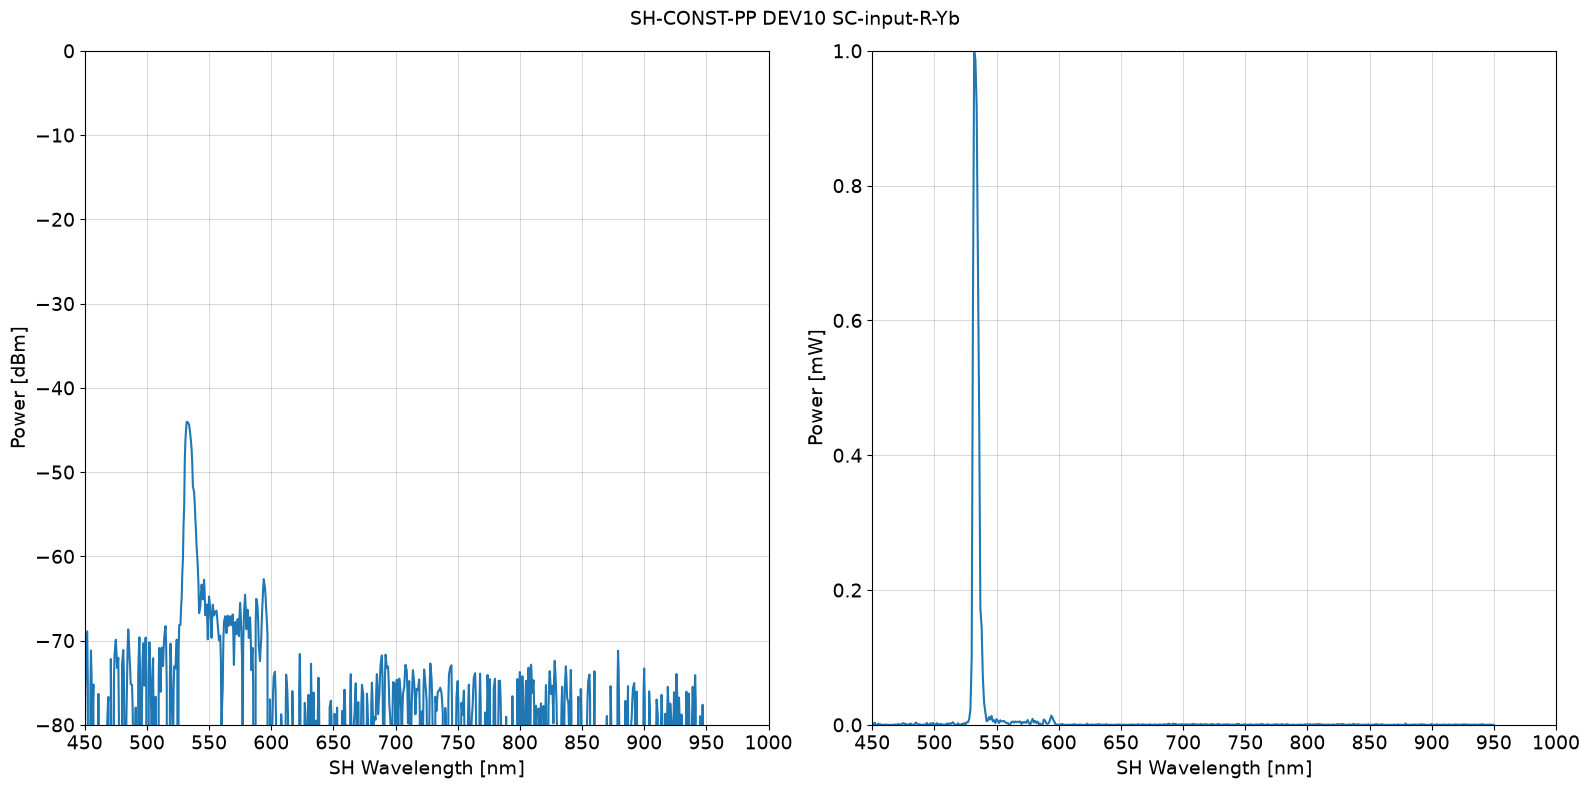

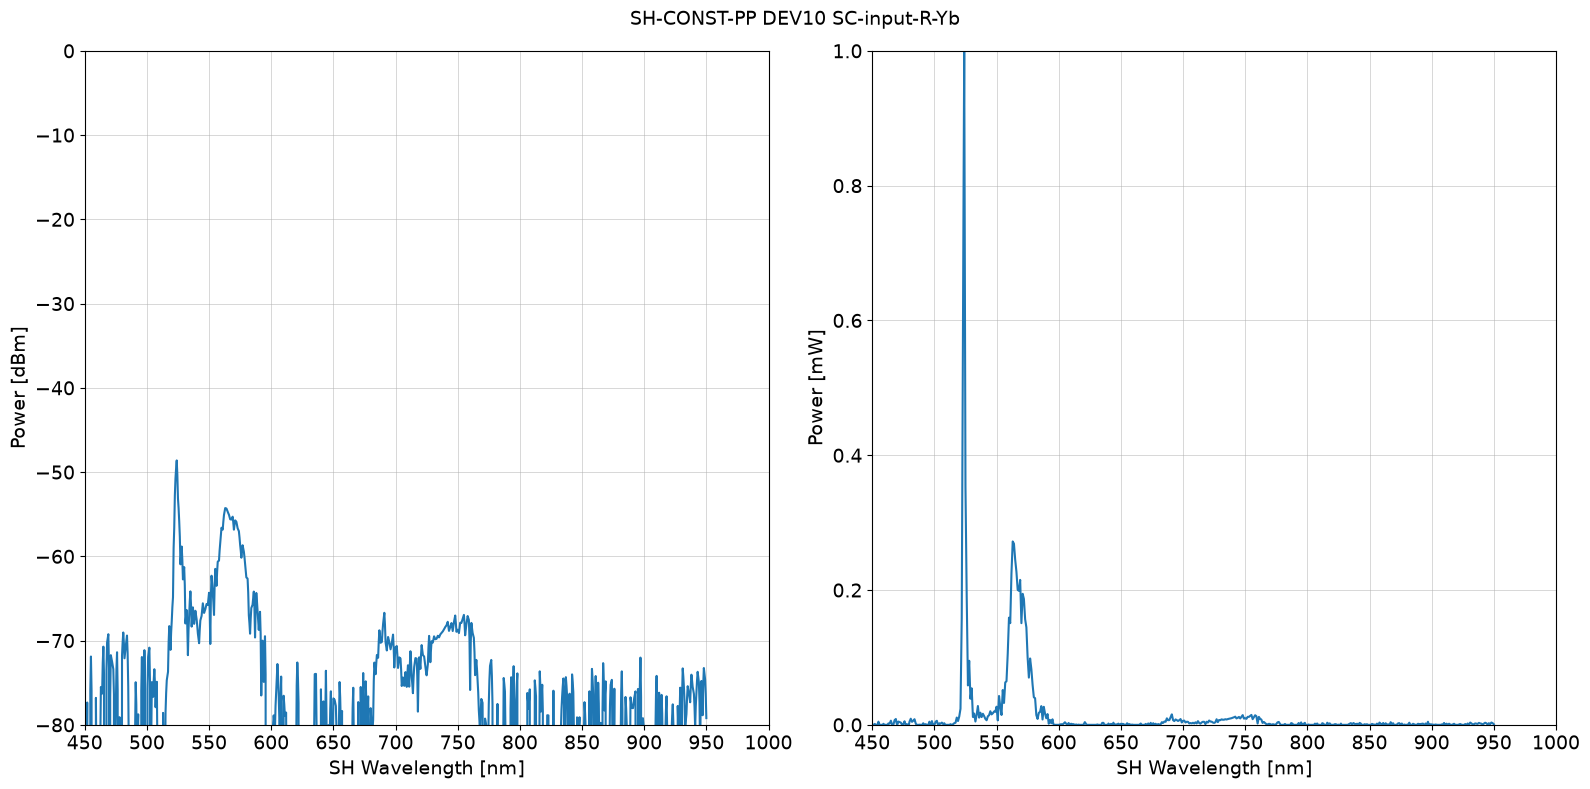

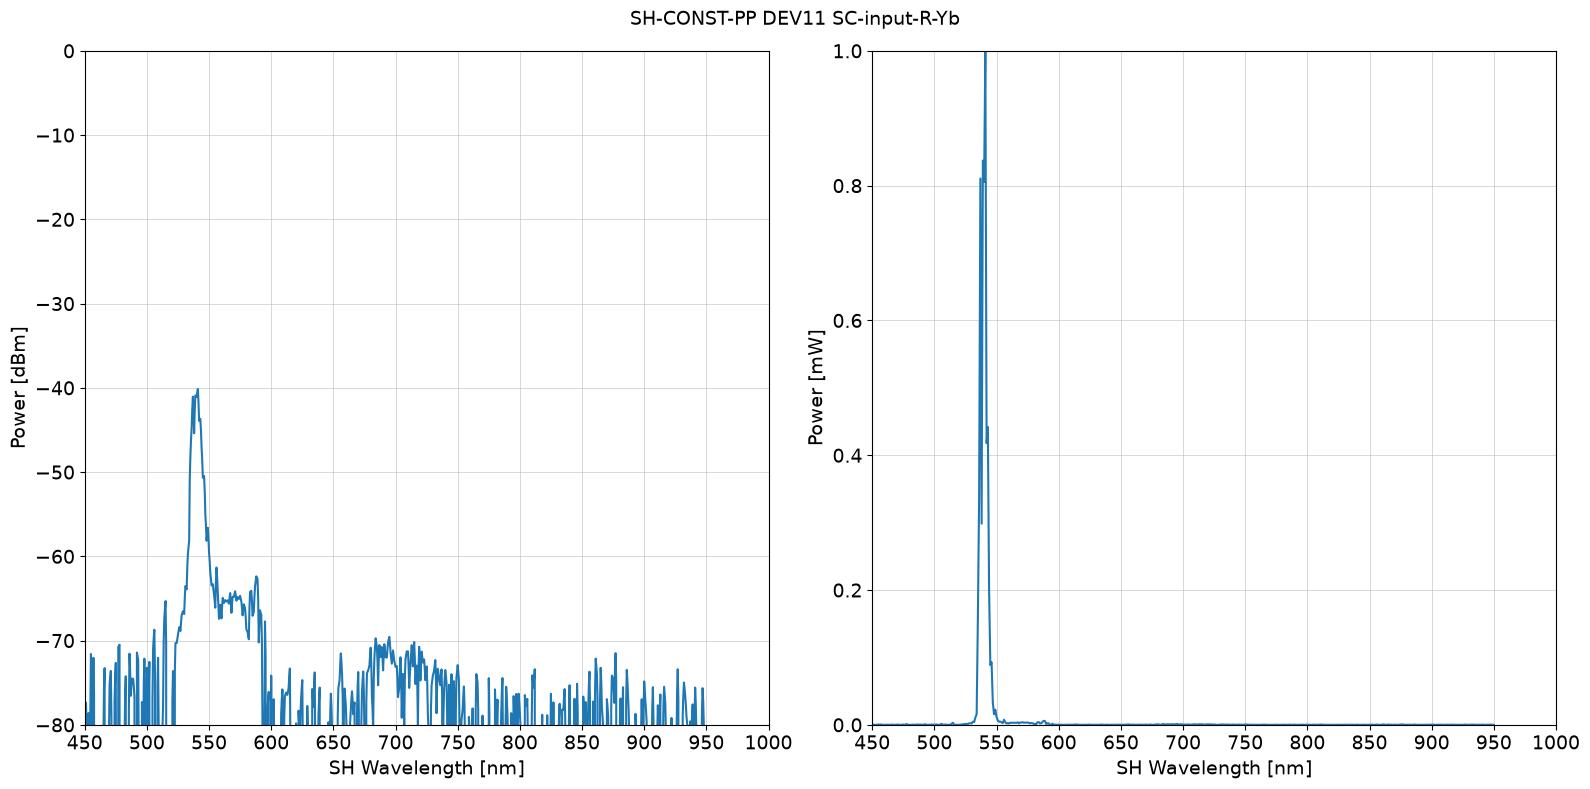

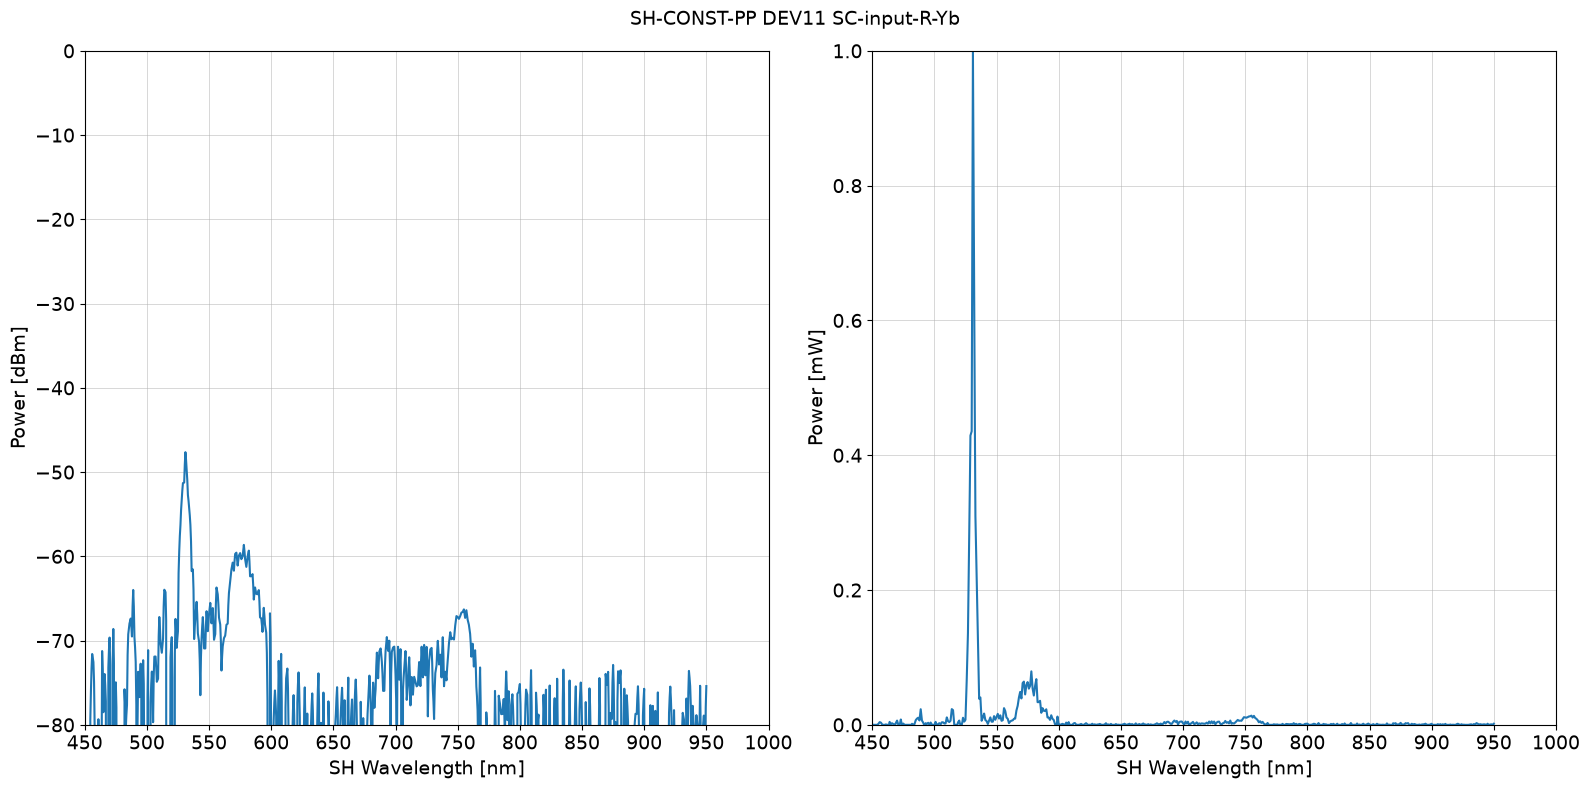

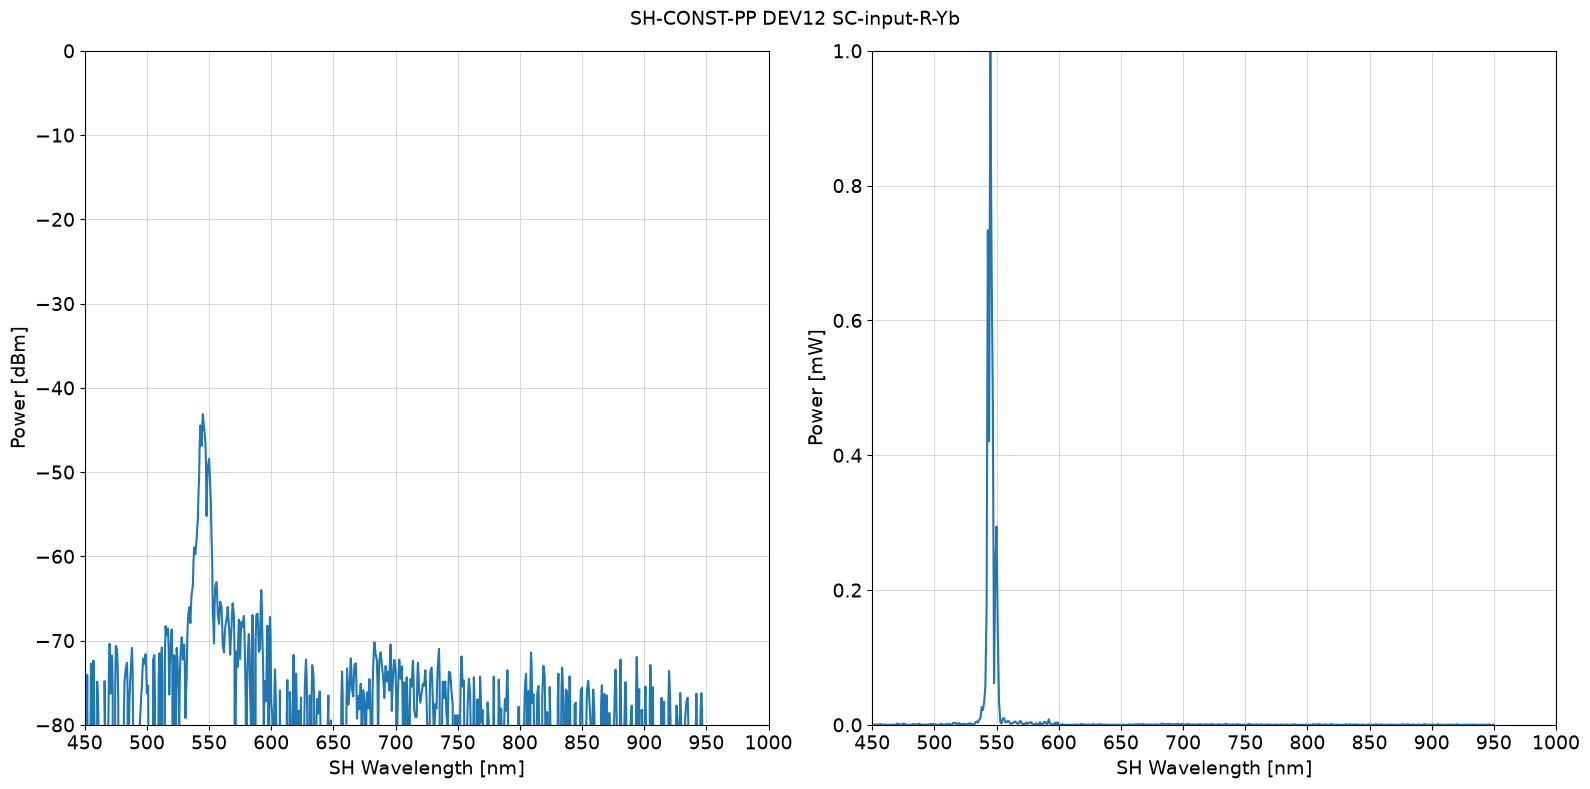

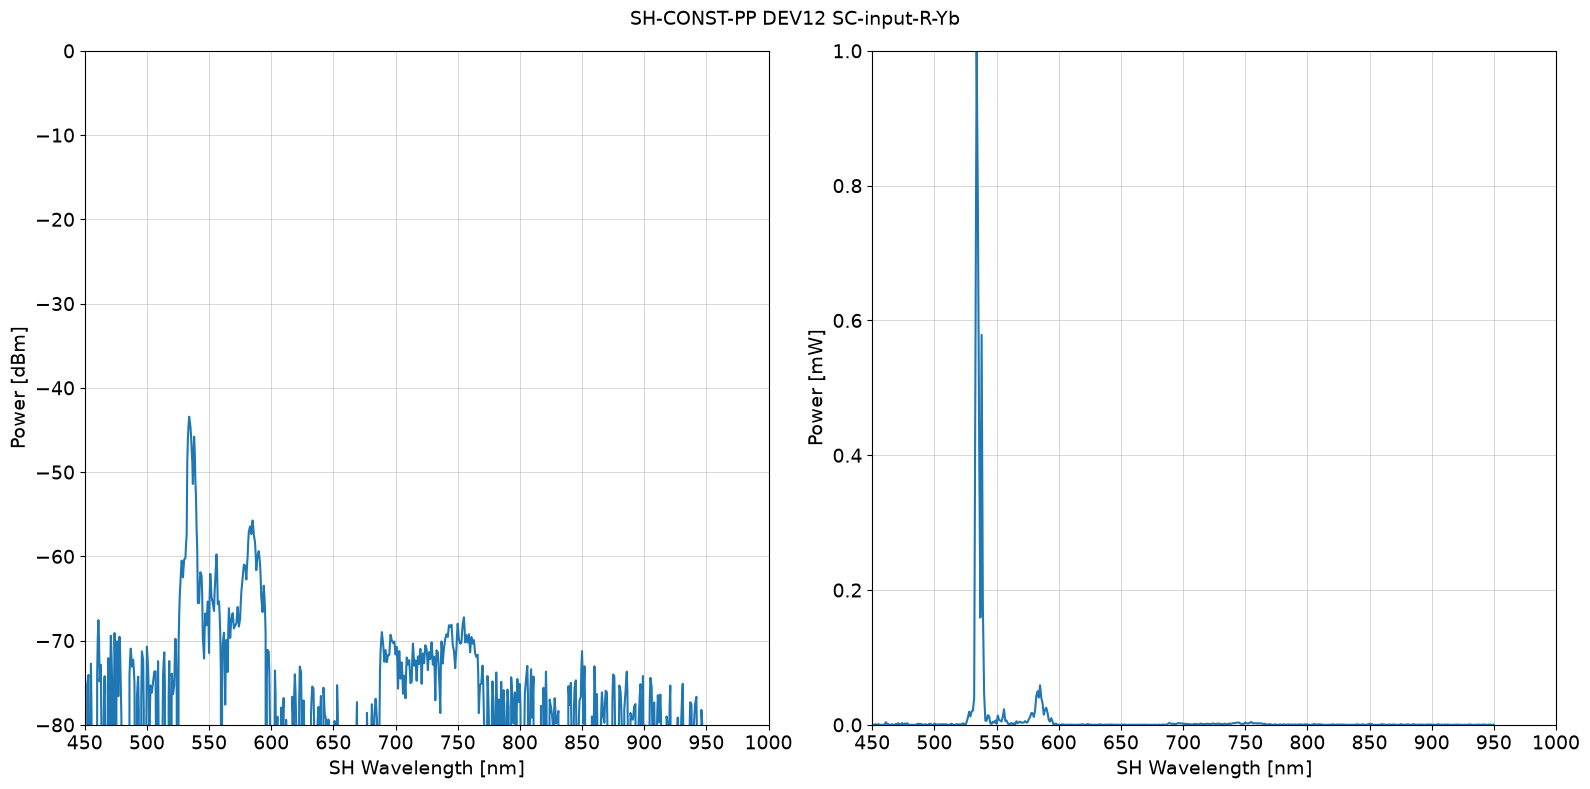

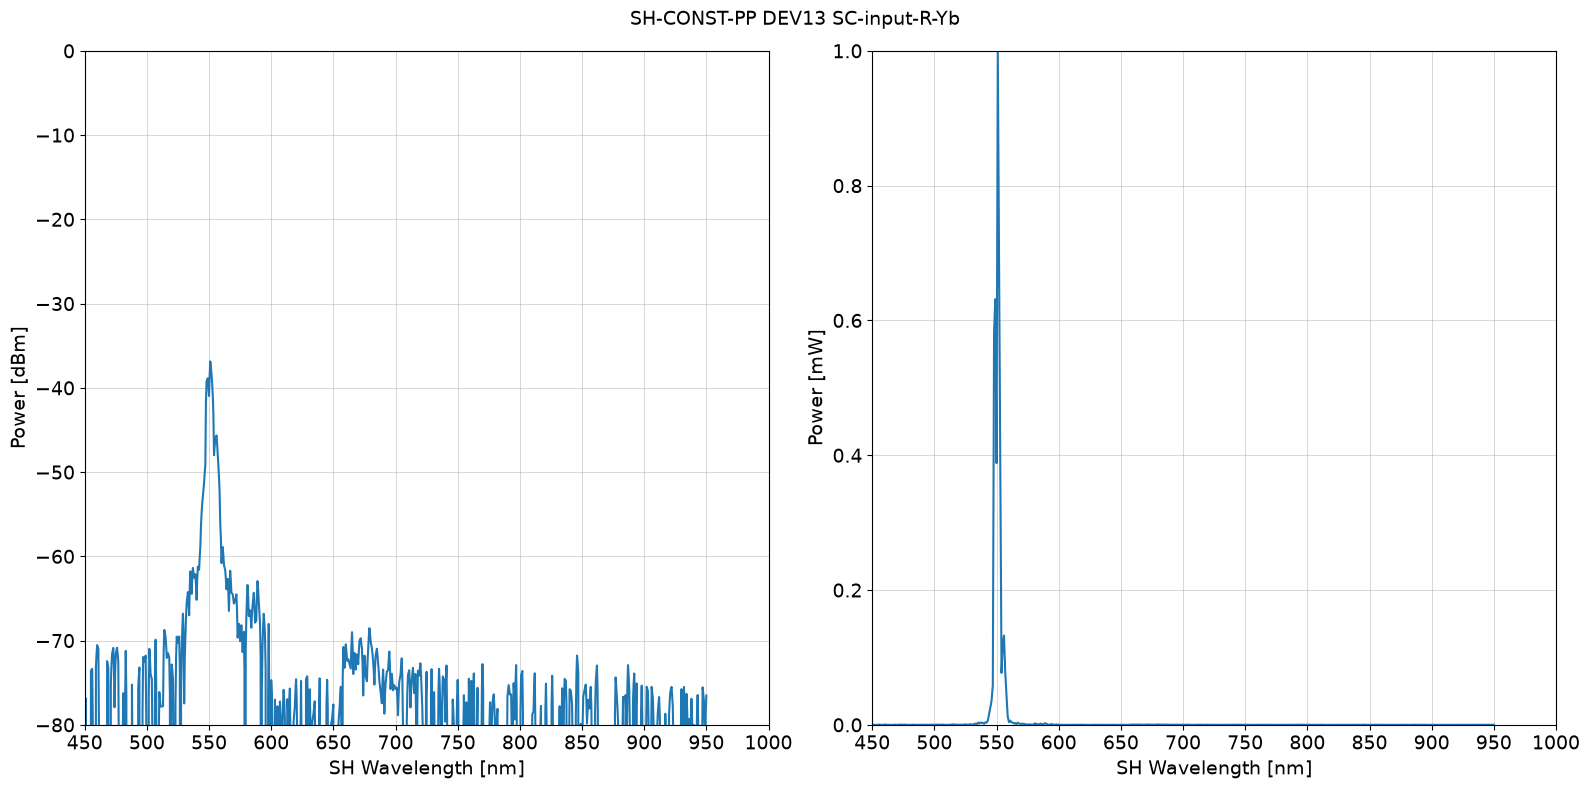

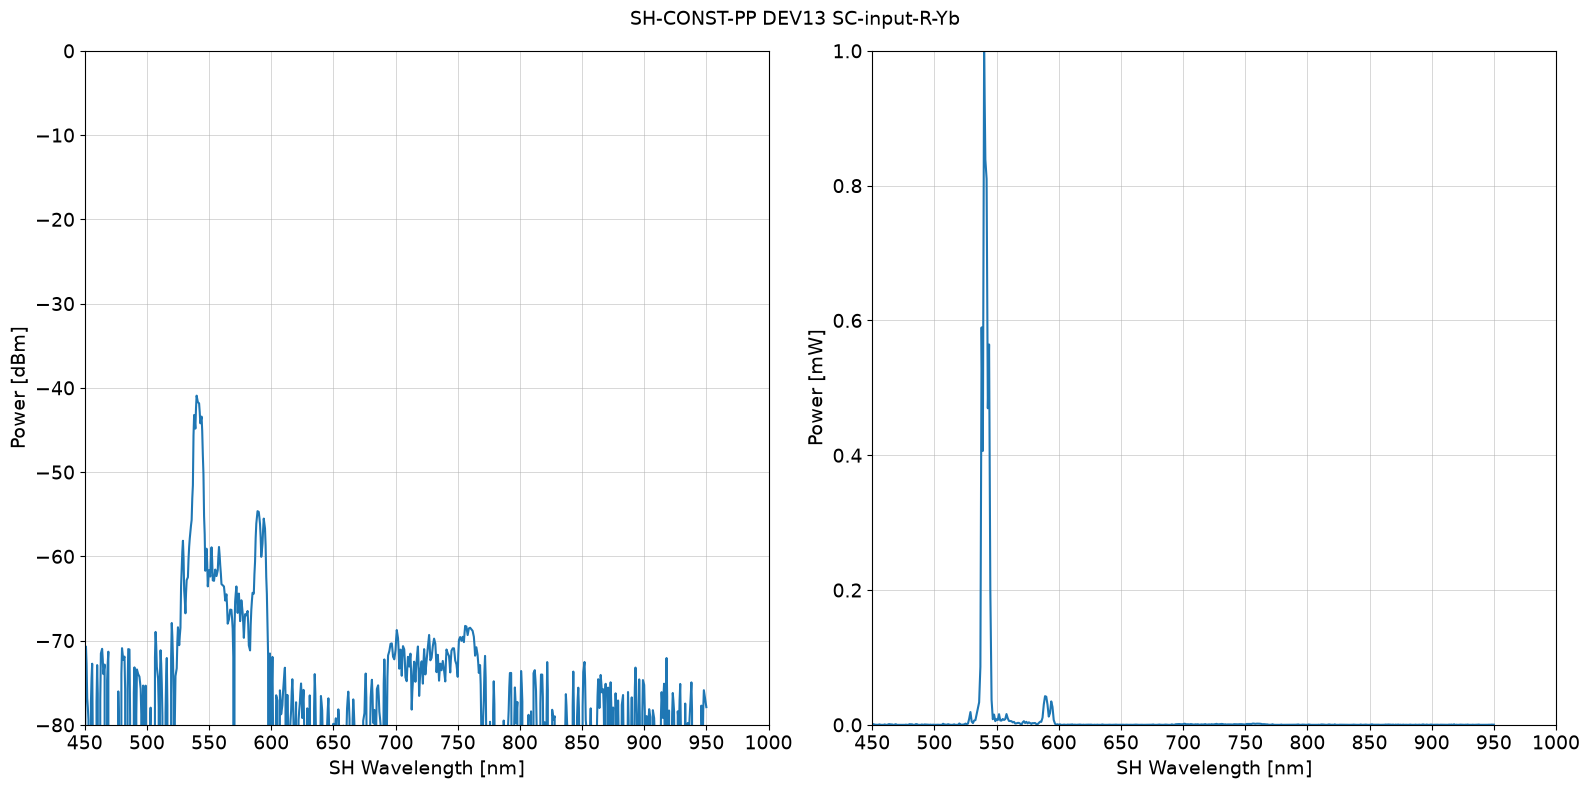

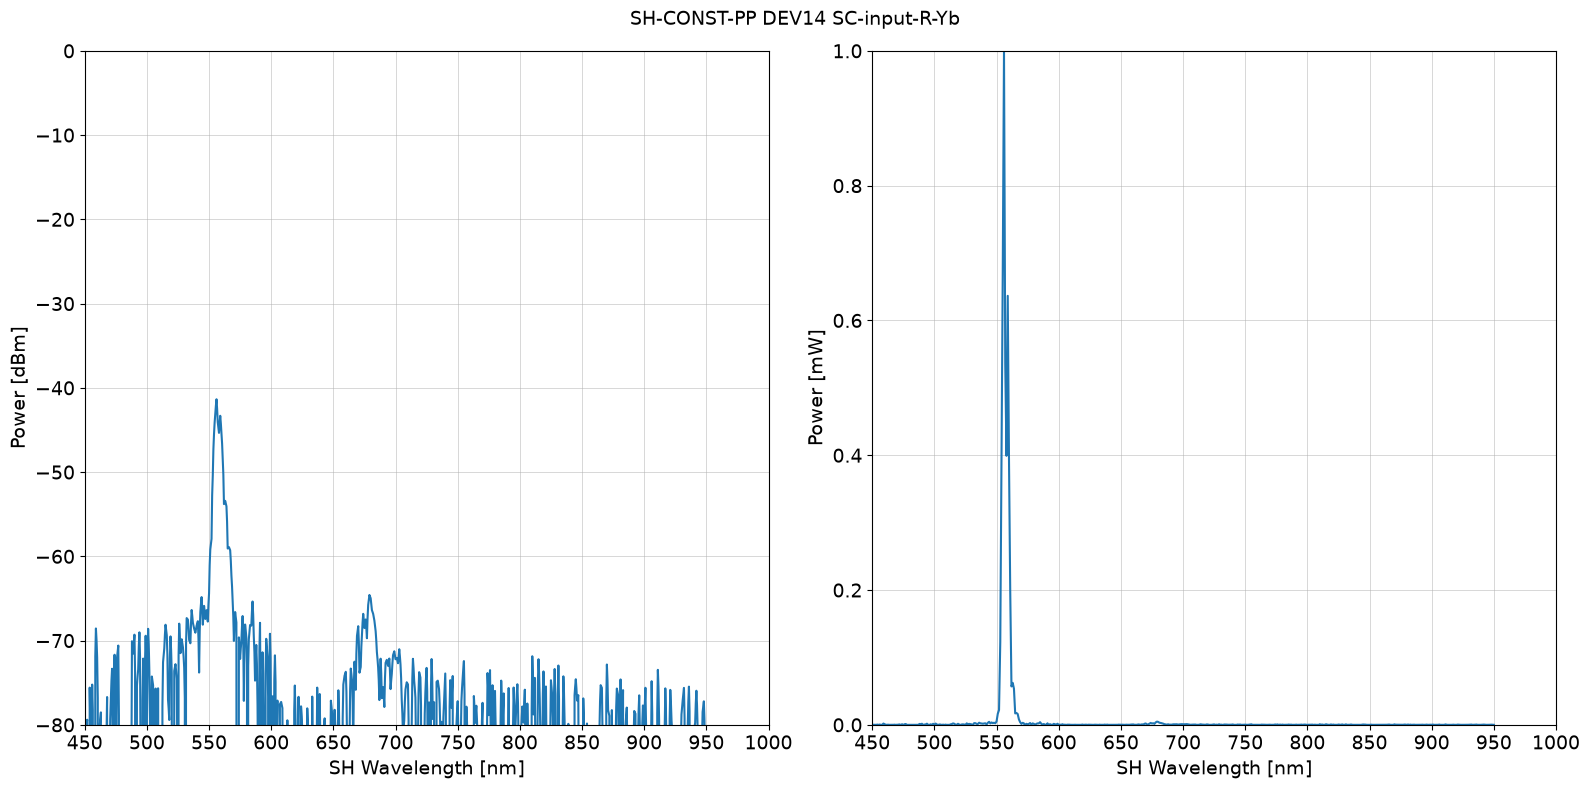

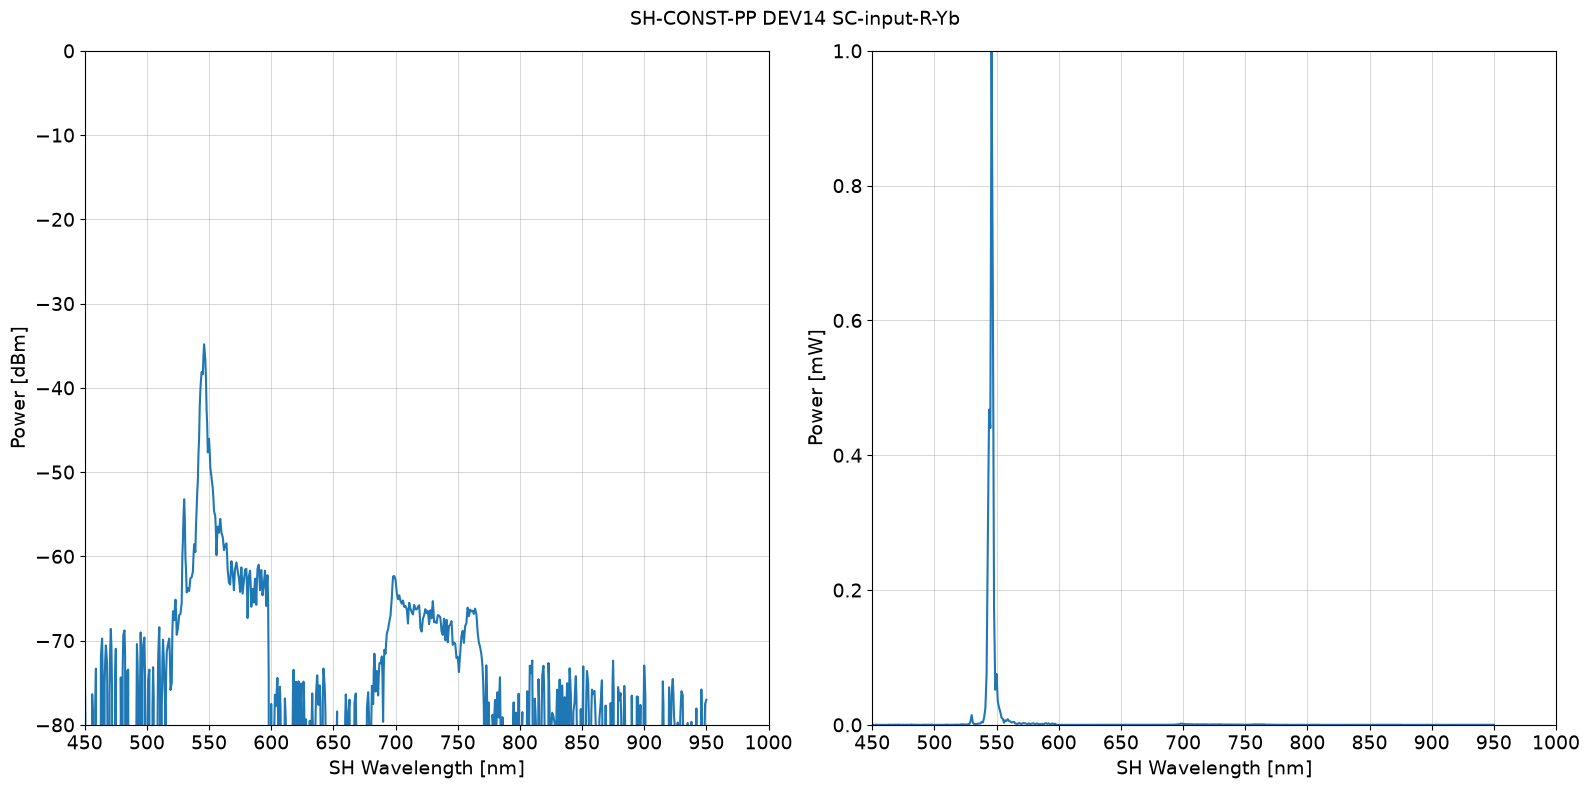

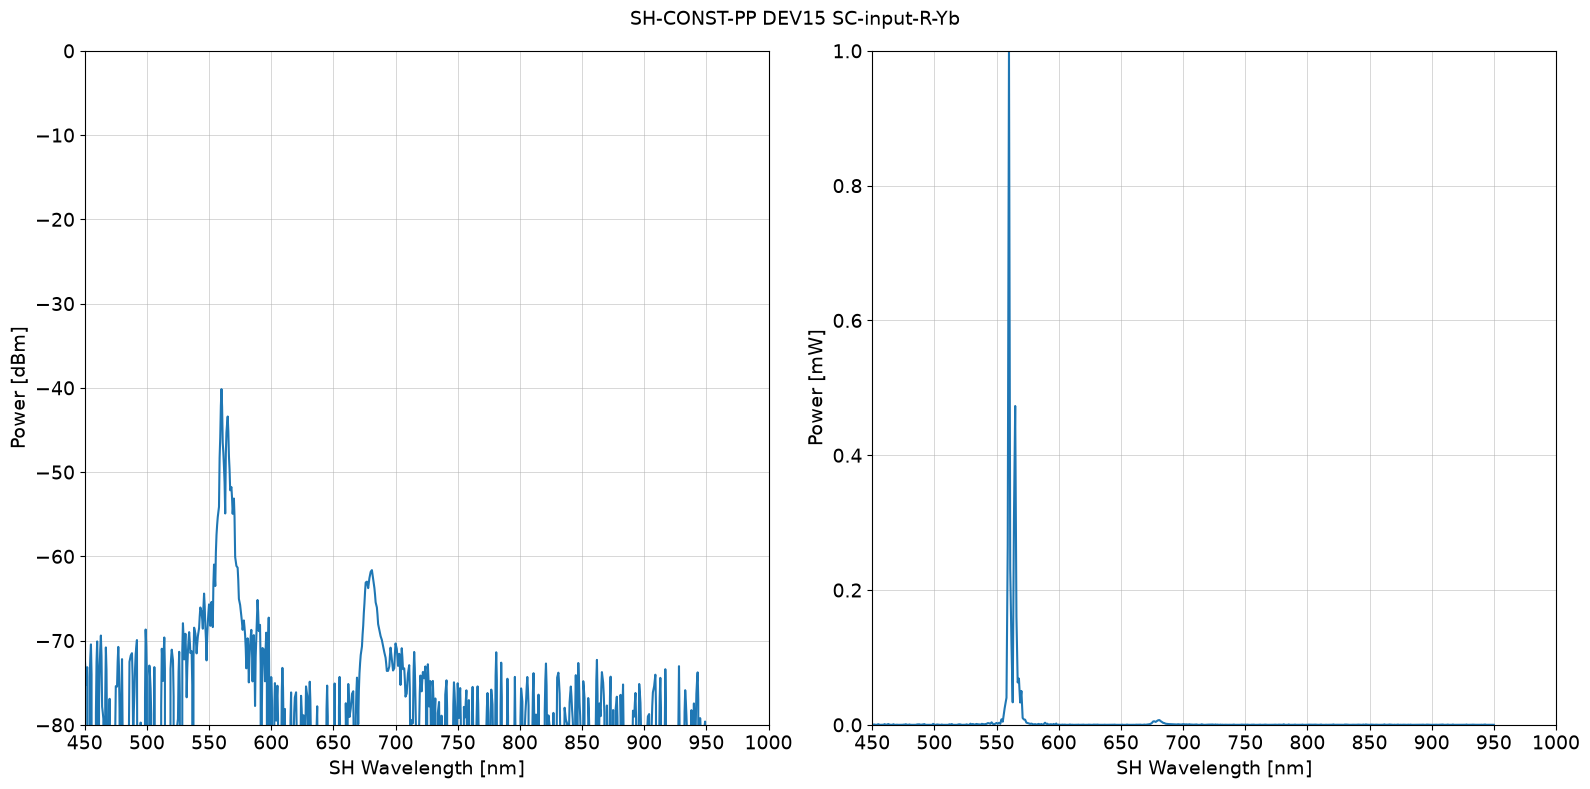

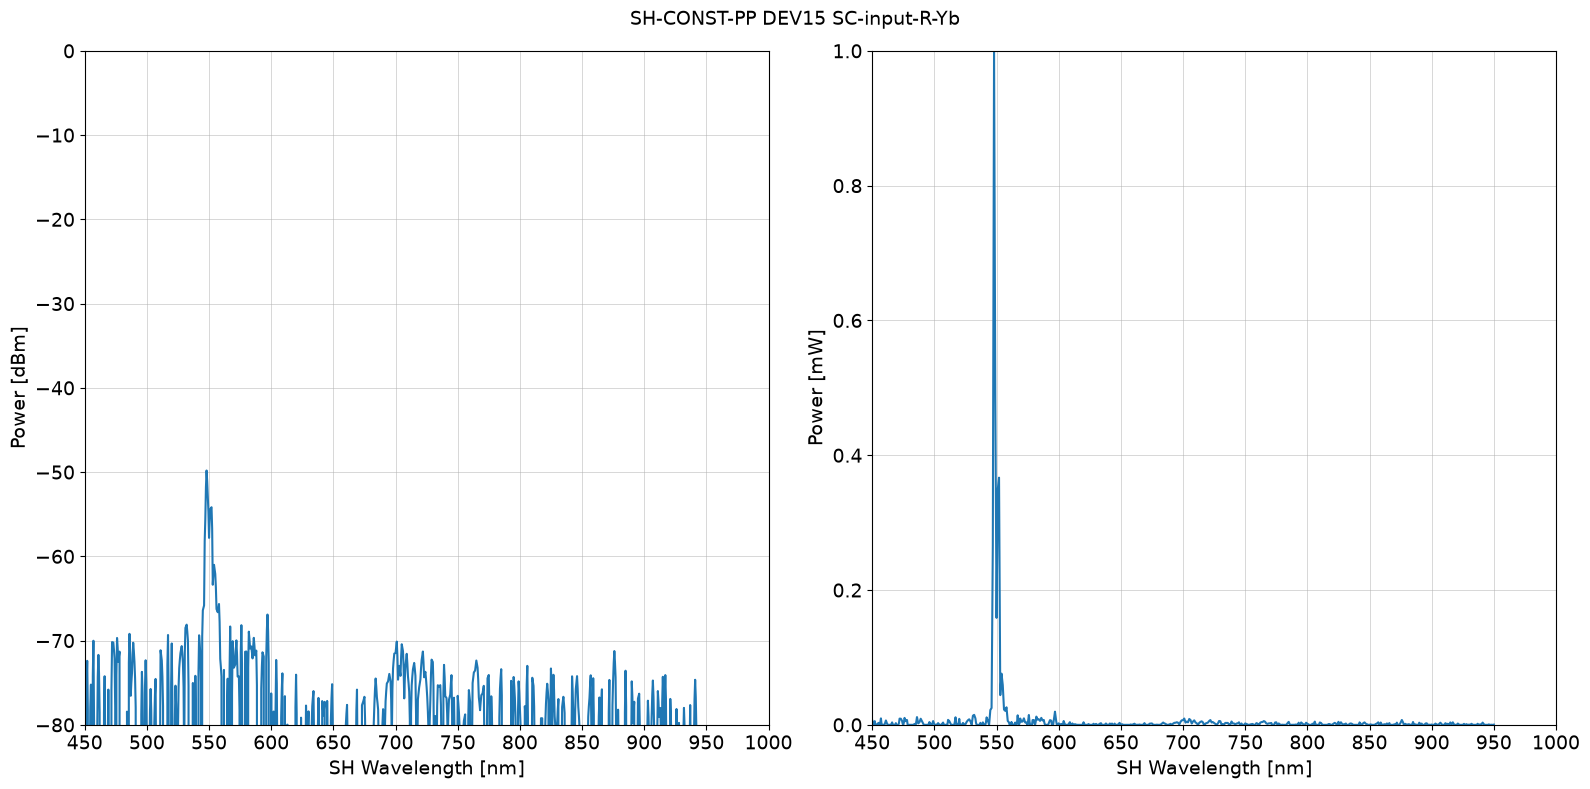

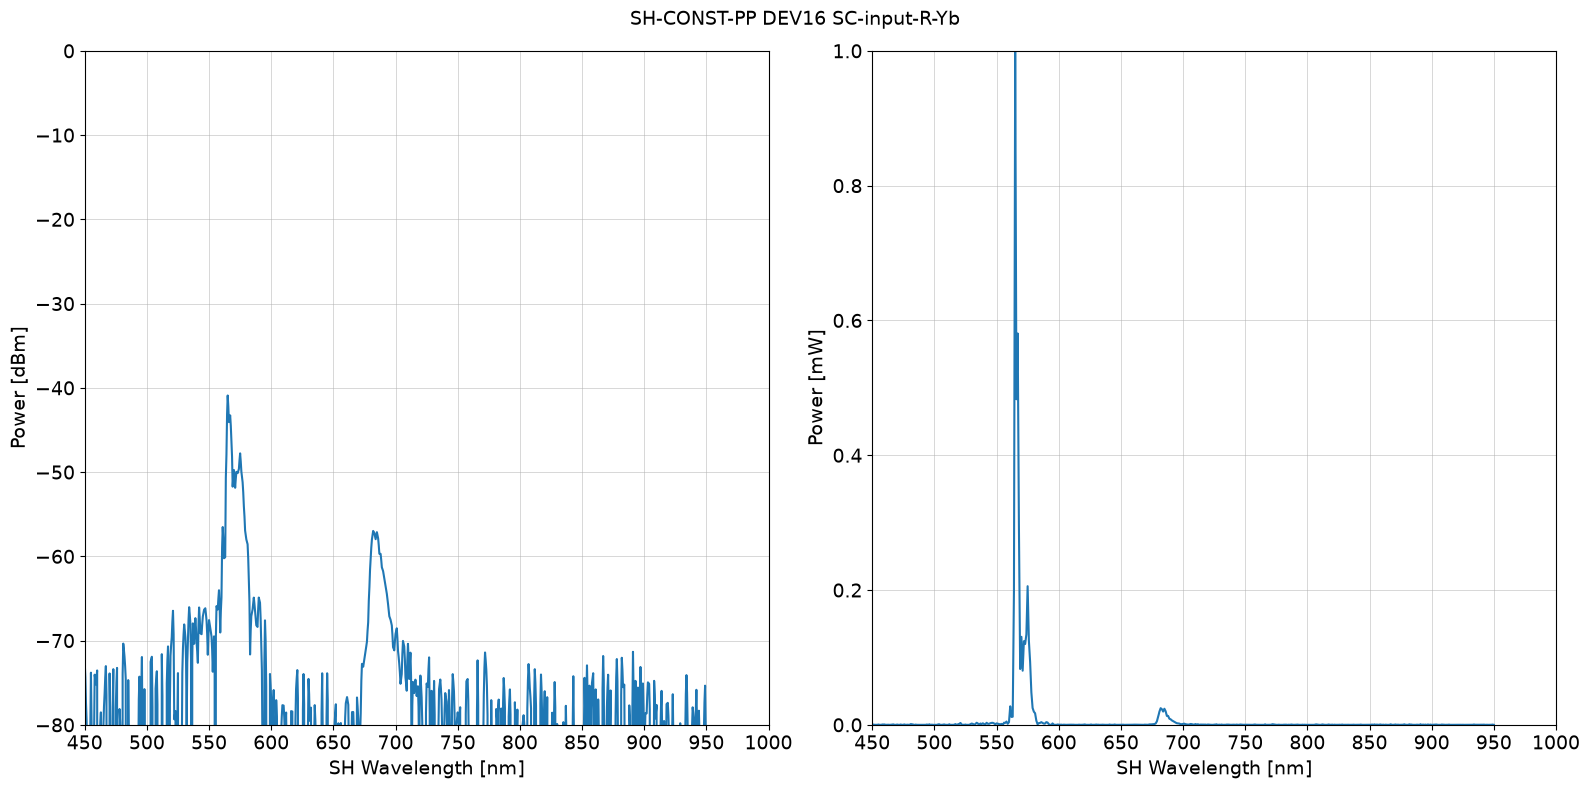

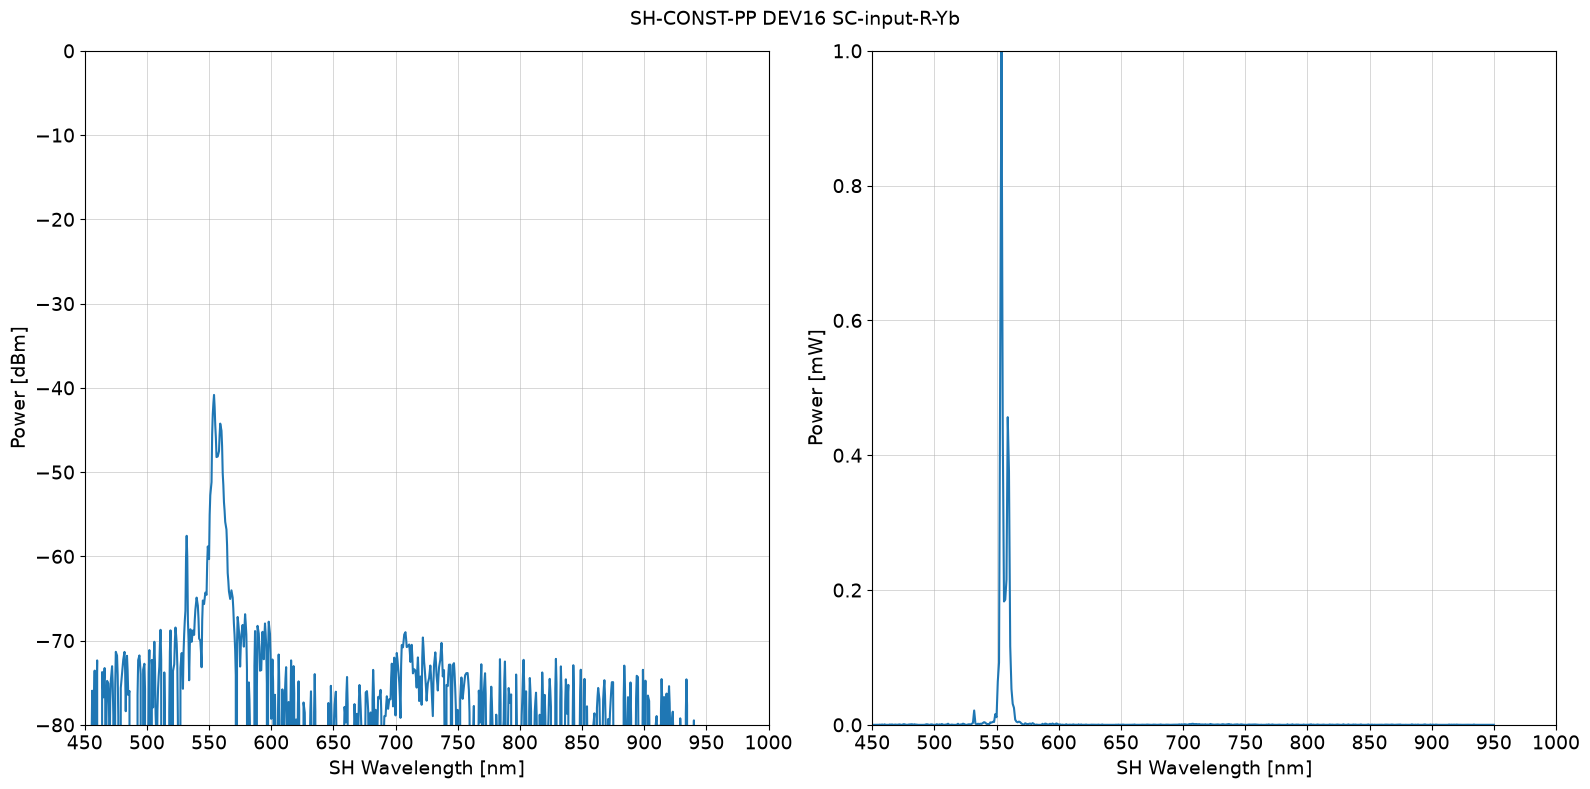

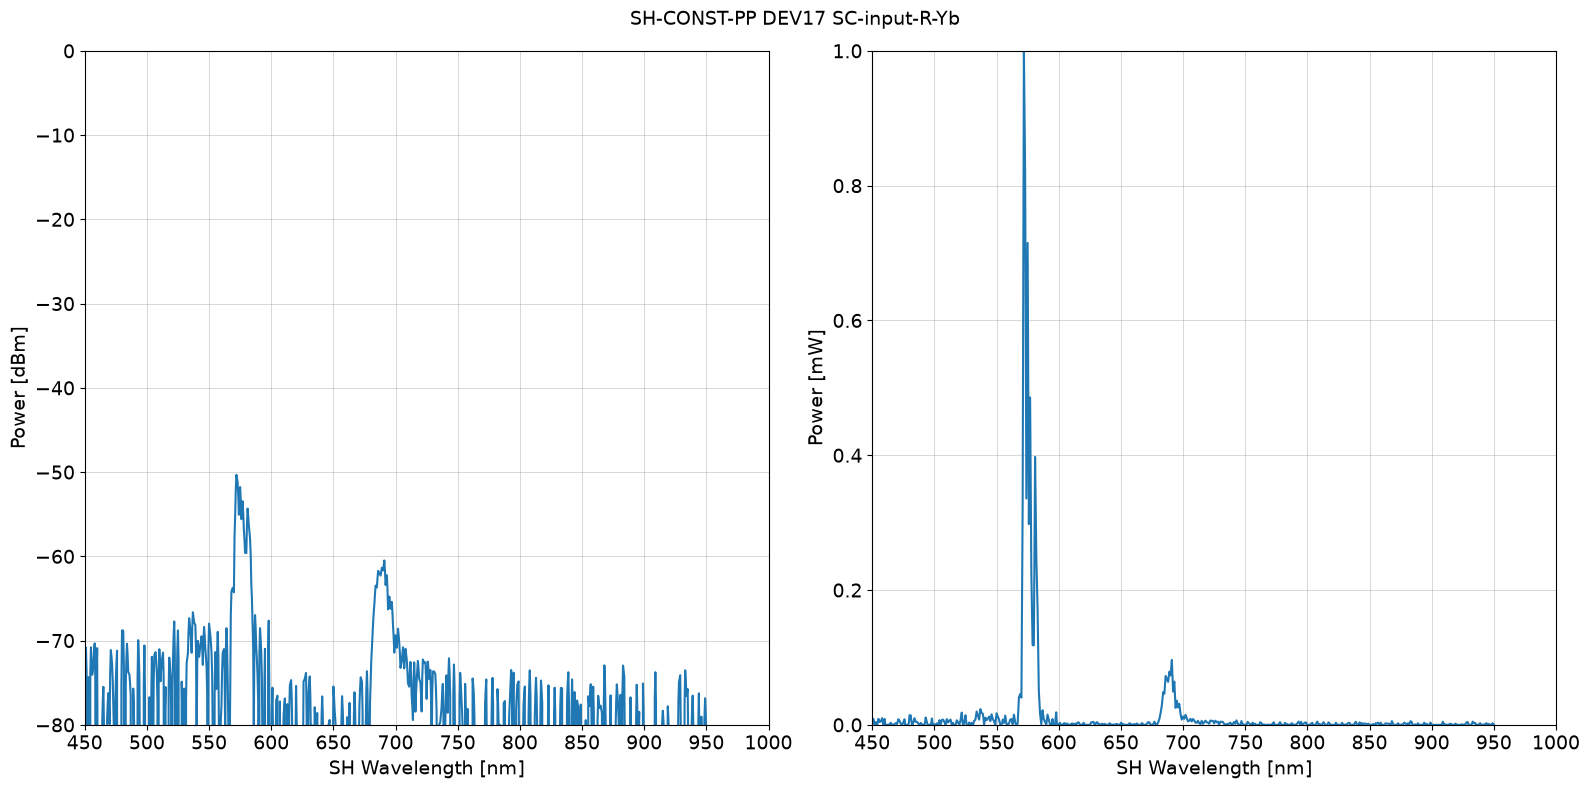

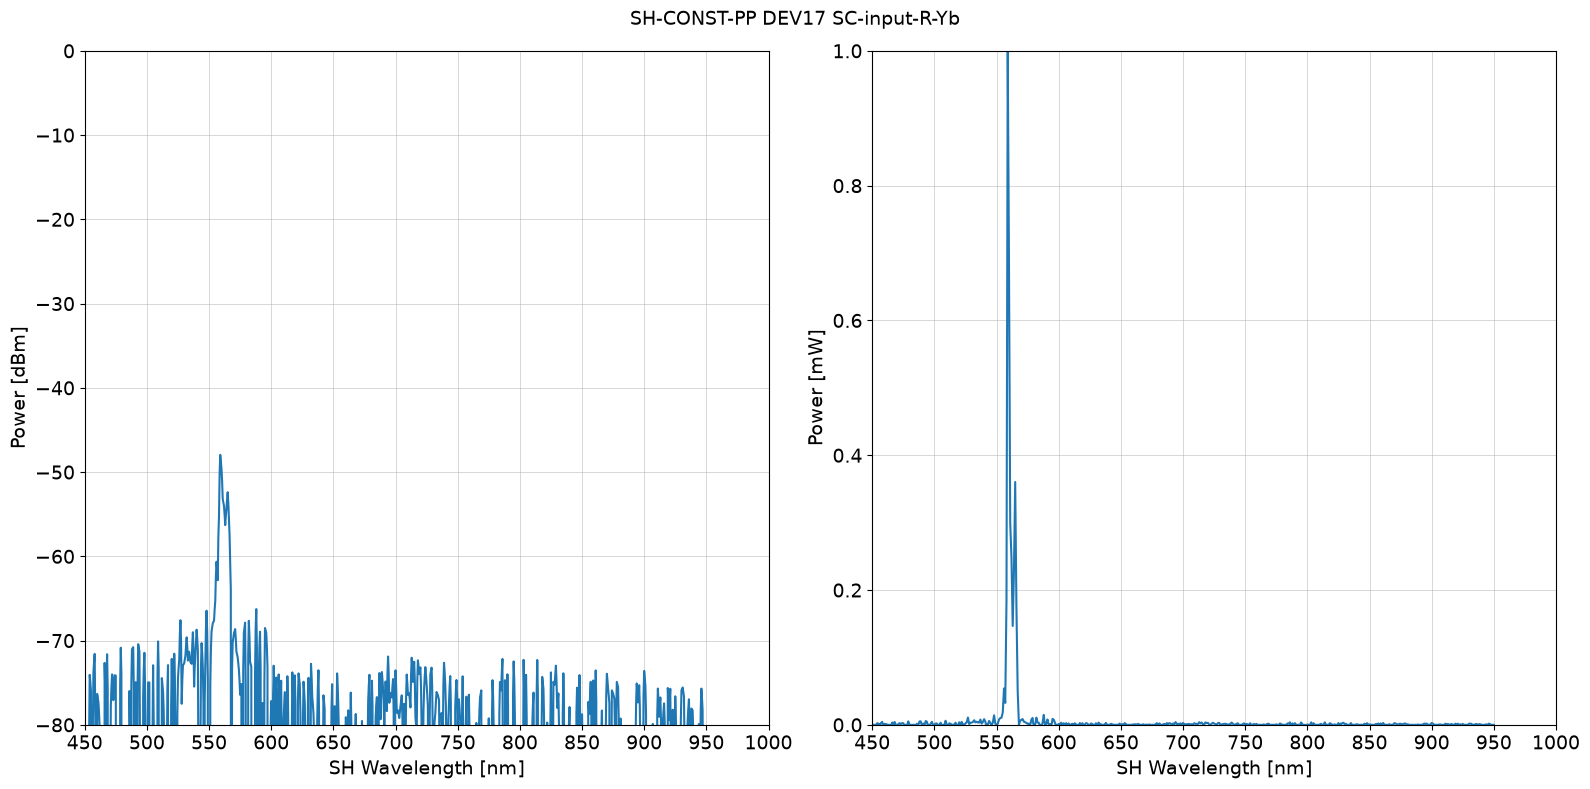

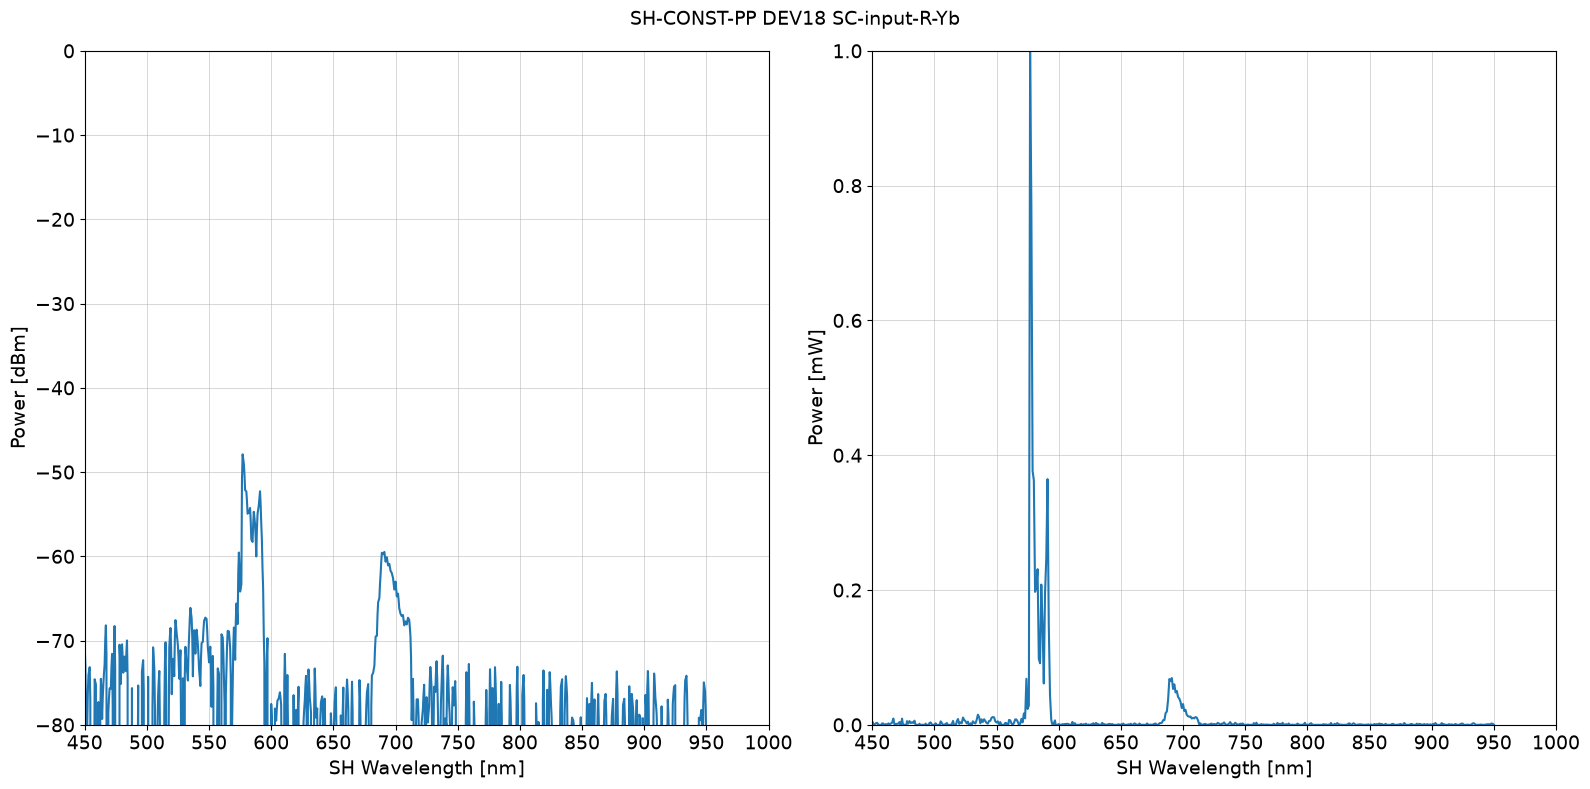

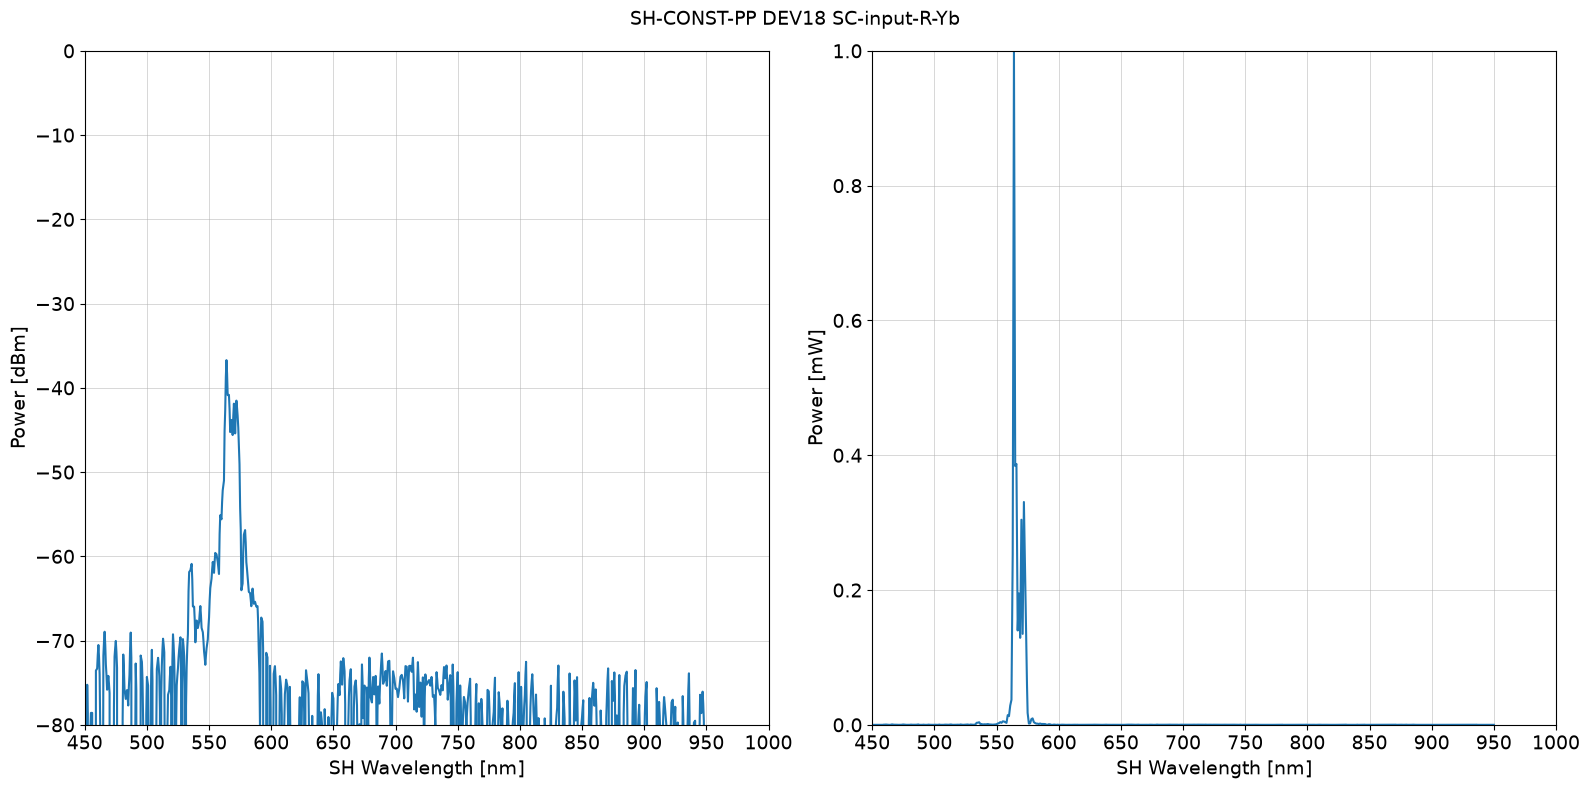

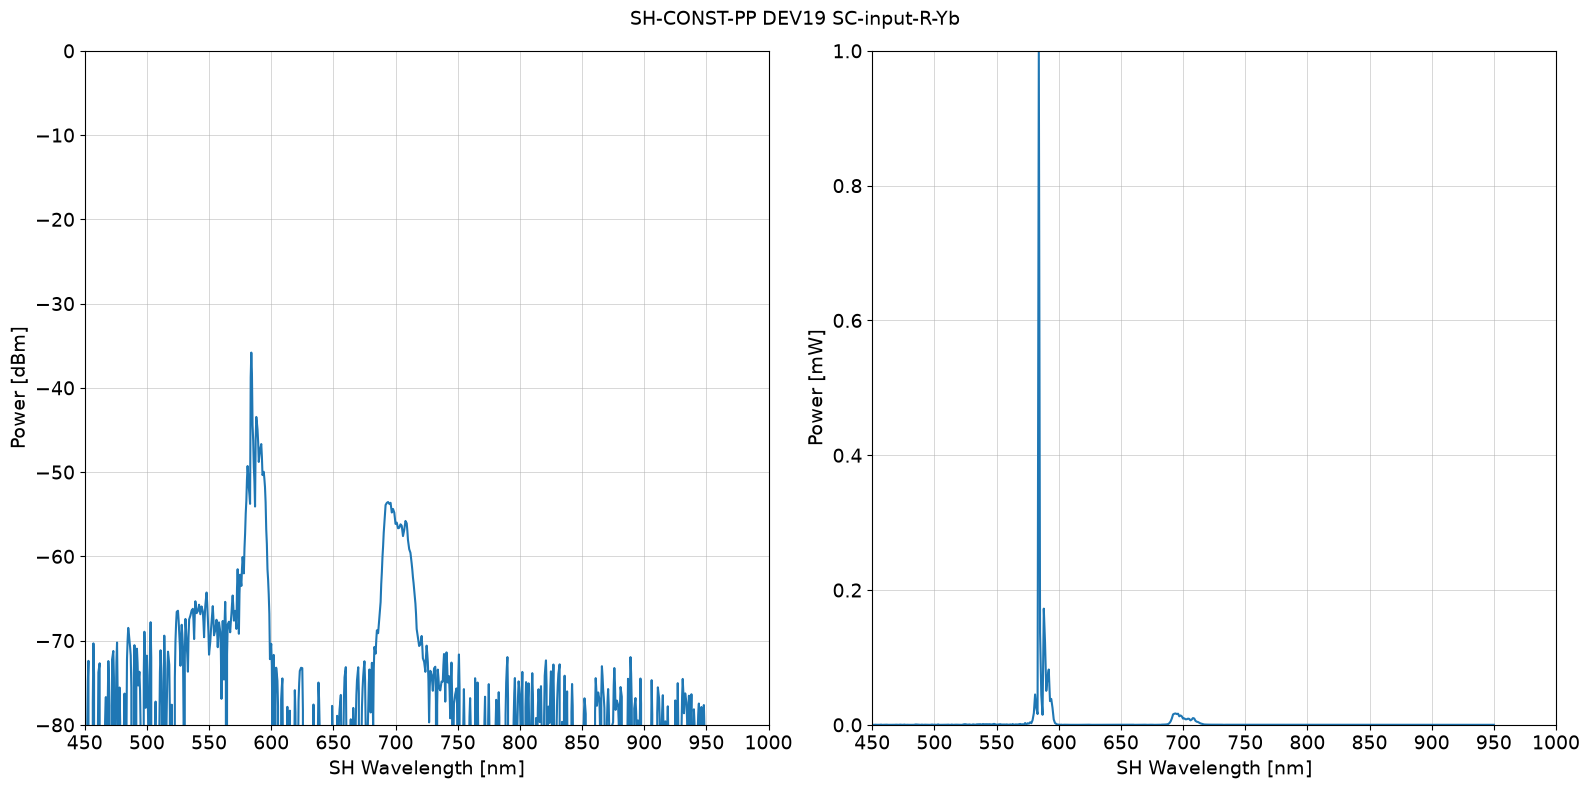

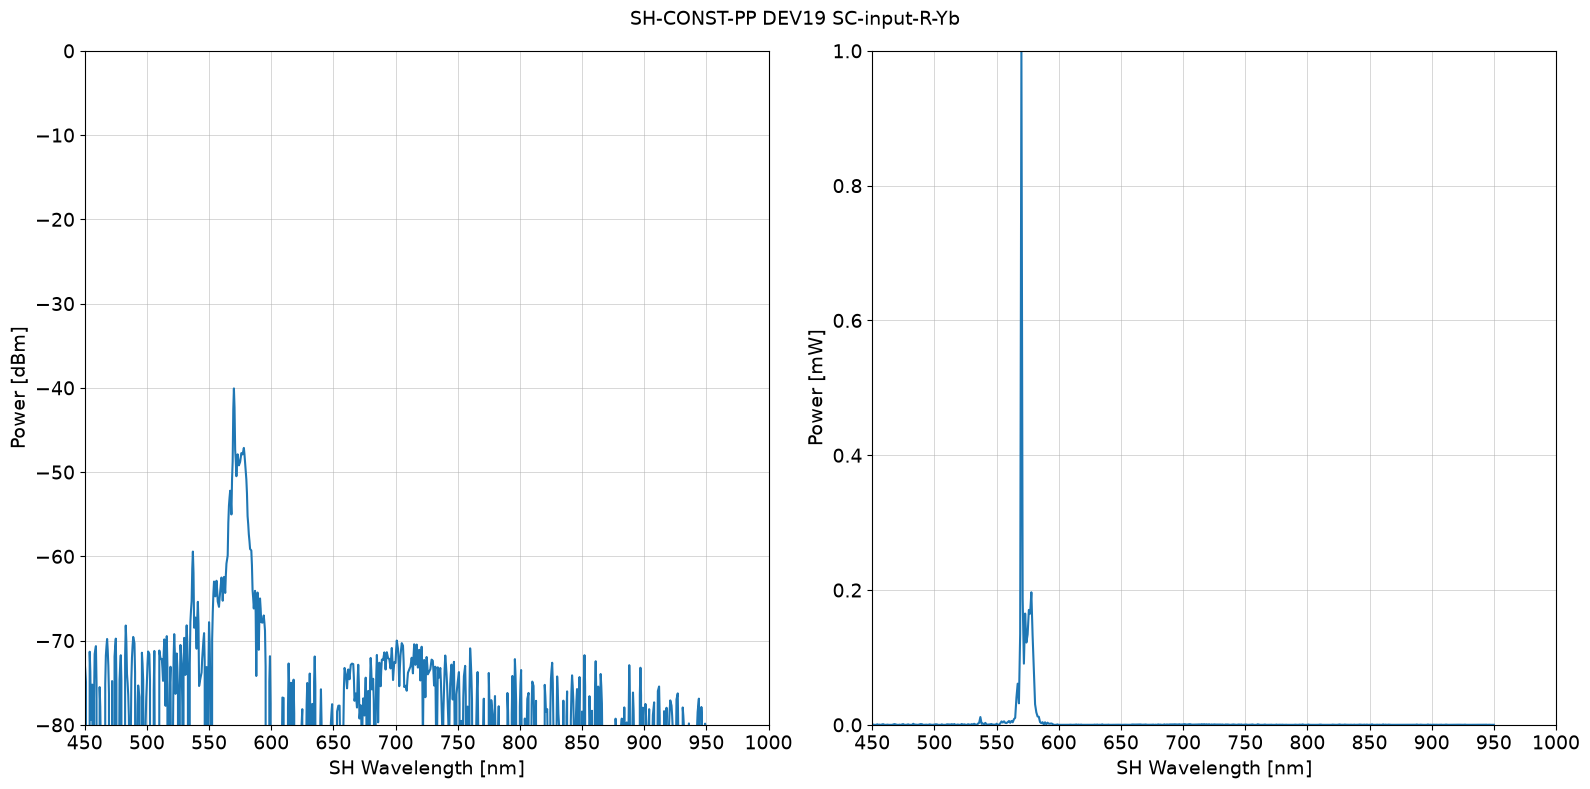

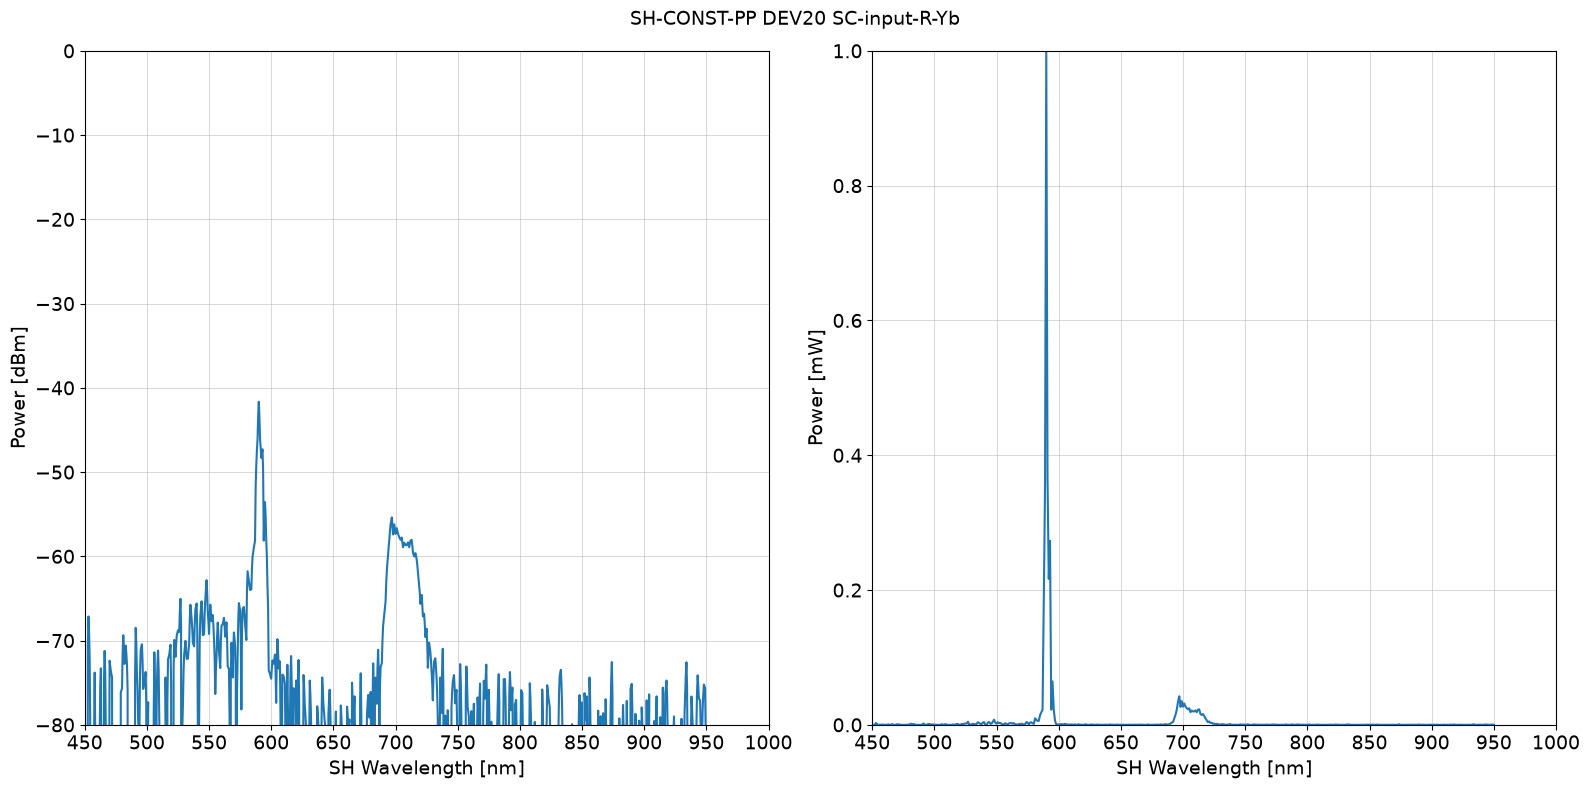

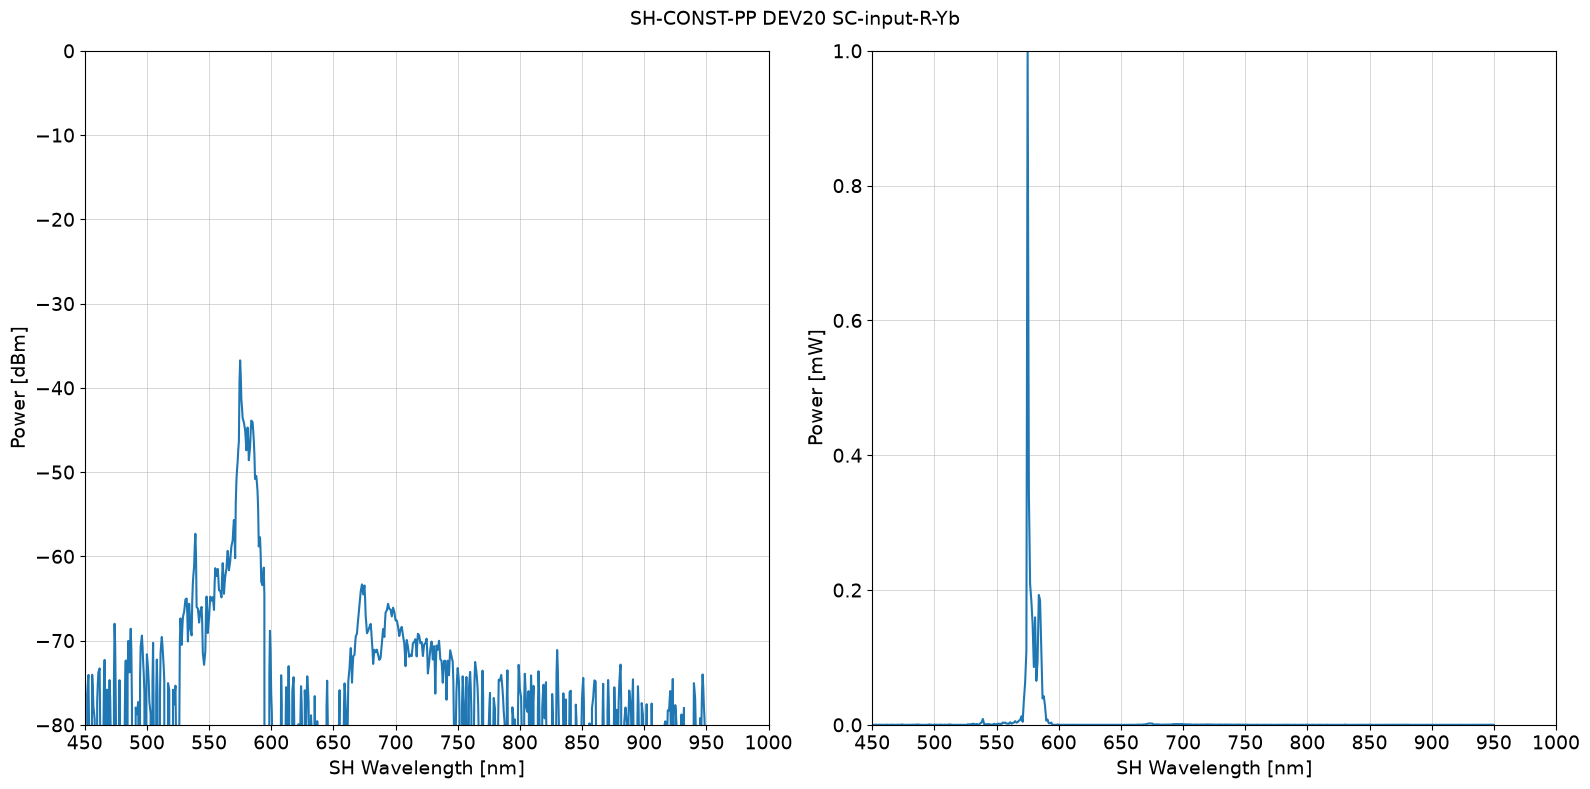

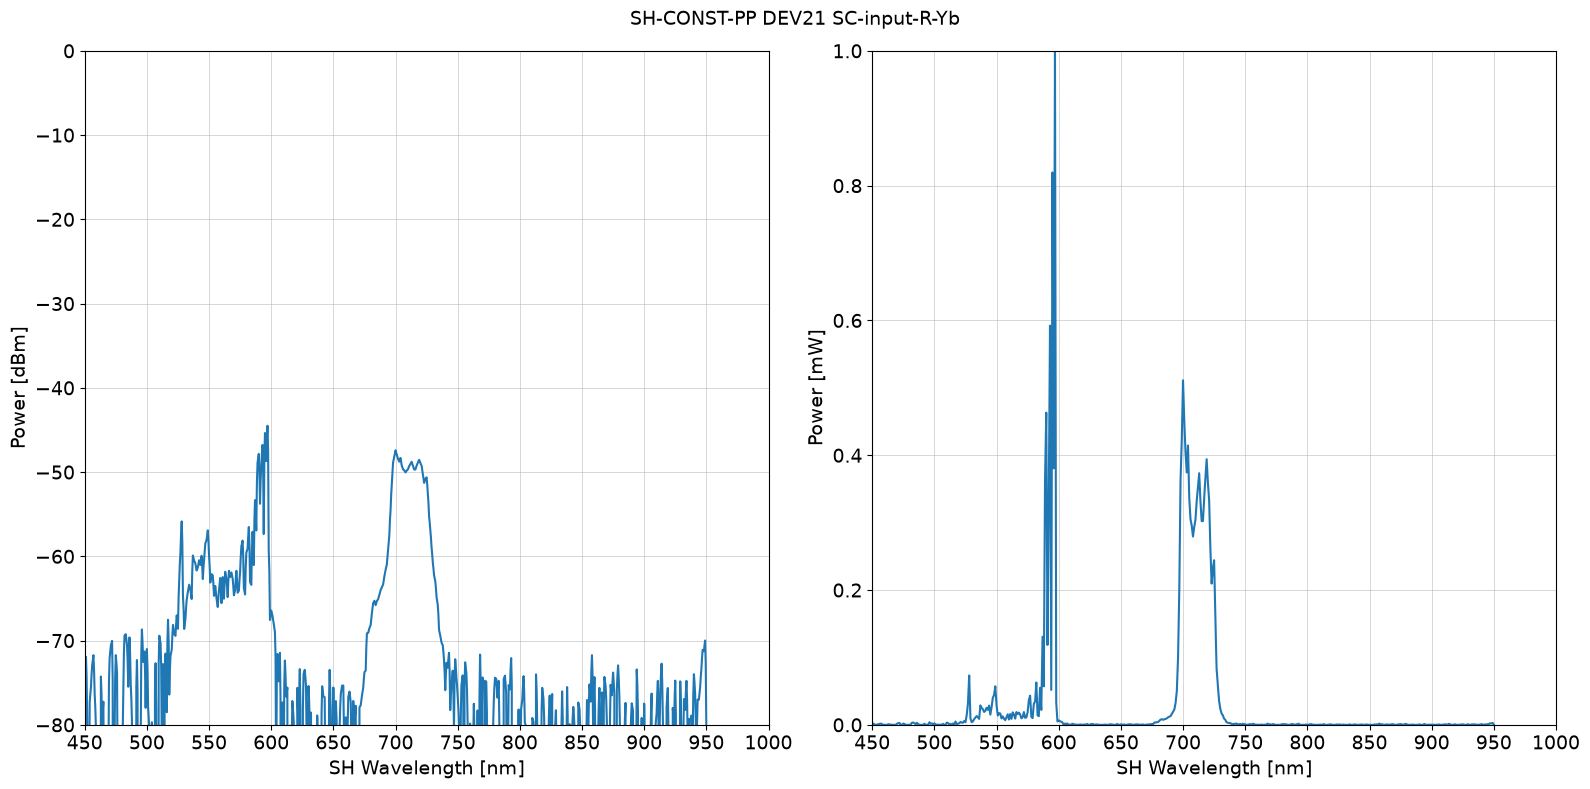

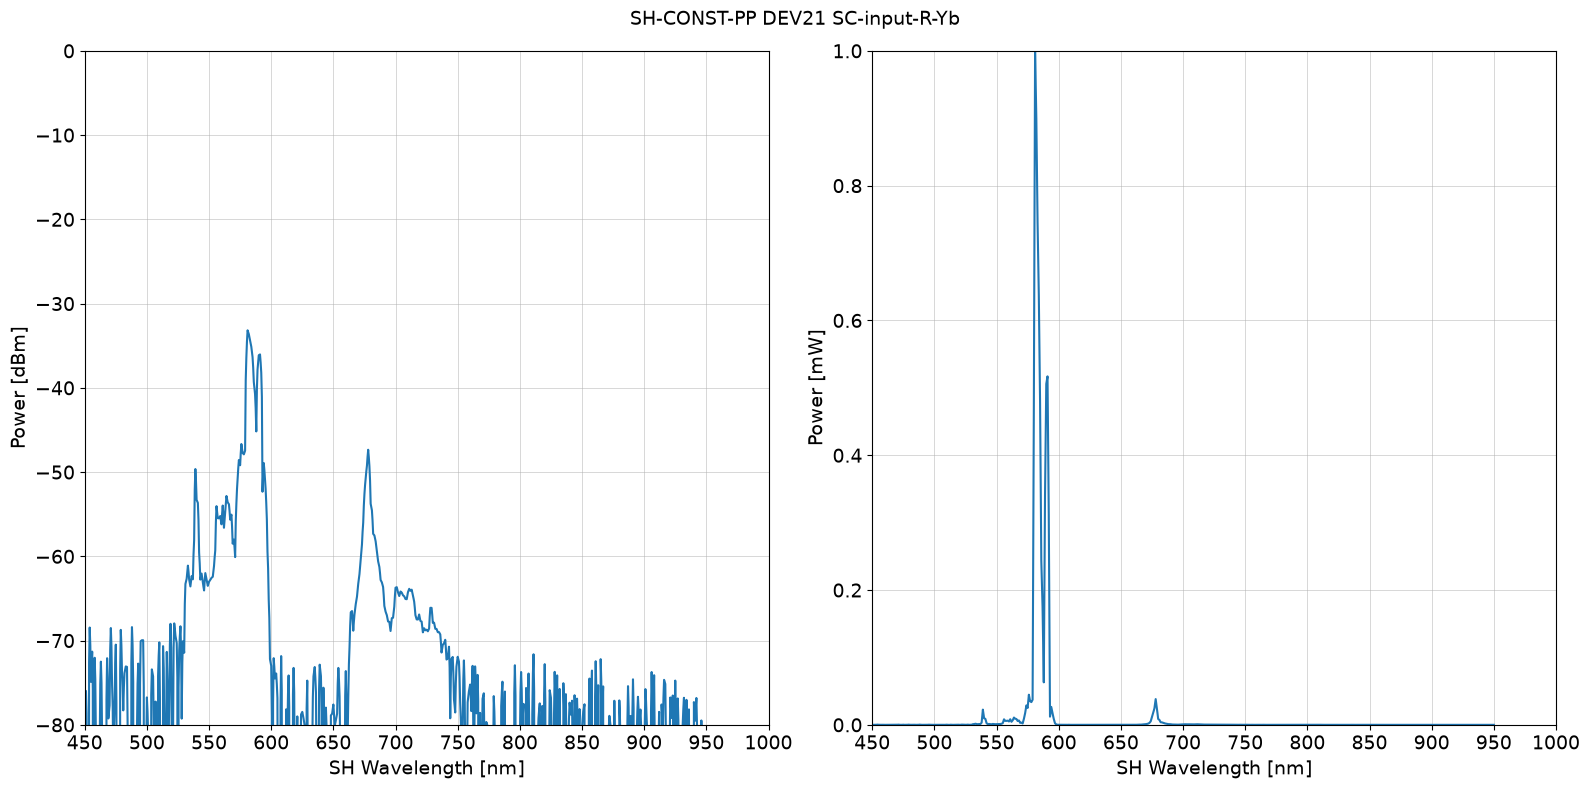

In [26]:
DevID_of_interest       = "SH-CONST-PP"
SCInputType_of_interest = "SC-input-R-Yb" # "SC-input-R-O", "SC-input-R-C"
df_filtered = df_sc_qpm_data[(df_sc_qpm_data['DevID'] == DevID_of_interest) & (df_sc_qpm_data['SCInputType'] == SCInputType_of_interest)]

for idx, row in df_filtered.iterrows():
    df_spectrum = pd.read_csv(row['fpath'])
    wavs, amps_dBm = df_spectrum['Wavelength (nm)'], df_spectrum['Power (dBm)'] # Raw OSA trace
    
    amps_linear = 10**(amps_dBm/10)
    amps_linear_norm_to_sc = amps_linear - np.min(amps_linear)
    amps_linear_norm_to_sc = amps_linear_norm_to_sc / np.max(amps_linear_norm_to_sc) # Normalize to max of 1
       
    fig, axs = plt.subplots(1, 2, figsize=(16, 8), tight_layout=True, sharex=True)

    fig.suptitle(f"{row['DevID']} DEV{row['DevNum']} {SCInputType_of_interest}", fontsize=label_fs)

    axs[0].plot(wavs, amps_dBm, linewidth=1.5, color='tab:blue')

    axs[0].set_xlabel("SH Wavelength [nm]", fontsize=label_fs)
    axs[0].set_ylabel("Power [dBm]", fontsize=label_fs)
    axs[0].tick_params(which='both', labelsize=tick_fs)

    axs[0].set_ylim(-80, 0)
    axs[0].set_xticks(np.arange(WL_MIN_SH, WL_MAX_SH+1, 50))
    axs[0].set_xlim(WL_MIN_SH, WL_MAX_SH)

    axs[0].grid(True, which='both', linestyle='-', linewidth=0.5, alpha=0.7)

    # Linear, normalized scale
    axs[1].plot(wavs, amps_linear_norm_to_sc, linewidth=1.5, color='tab:blue')

    axs[1].set_xlabel("SH Wavelength [nm]", fontsize=label_fs)
    axs[1].set_ylabel("Power [mW]", fontsize=label_fs)
    axs[1].tick_params(which='both', labelsize=tick_fs)

    ymin, ymax, ystep = 0.0, 1.0, 0.2
    axs[1].set_yticks(np.arange(ymin, ymax+ystep/2.0, ystep))
    axs[1].set_ylim(ymin, ymax)

    axs[1].grid(True, which='both', linestyle='-', linewidth=0.5, alpha=0.7)

    plt.show()

#### Plot the SH-CONST-PP SC QPM Spectra - normalized data (linear/log)

1. Checked that peak-finding works OK
2. Checked that the normalized spectra are reasonable (ex: C-band has the known supercontinuum power roll-off issue)

When you make the final error plots, use this to manually check points that look weird.

NOTE - the point of the "SC-input-R-NIR" devices was to test if I could simultaneously measure all 3 QPM peaks at once \
Intead, you got weird unintentional mixing, which muddied the data. So, it's an plotting option below for completeness, but not actually useful. 

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV03_WIDTH-1.8um_REFL-50.0dBm_SHI2_SC-input-R-Yb_04-30-2026-15-12-47.csv


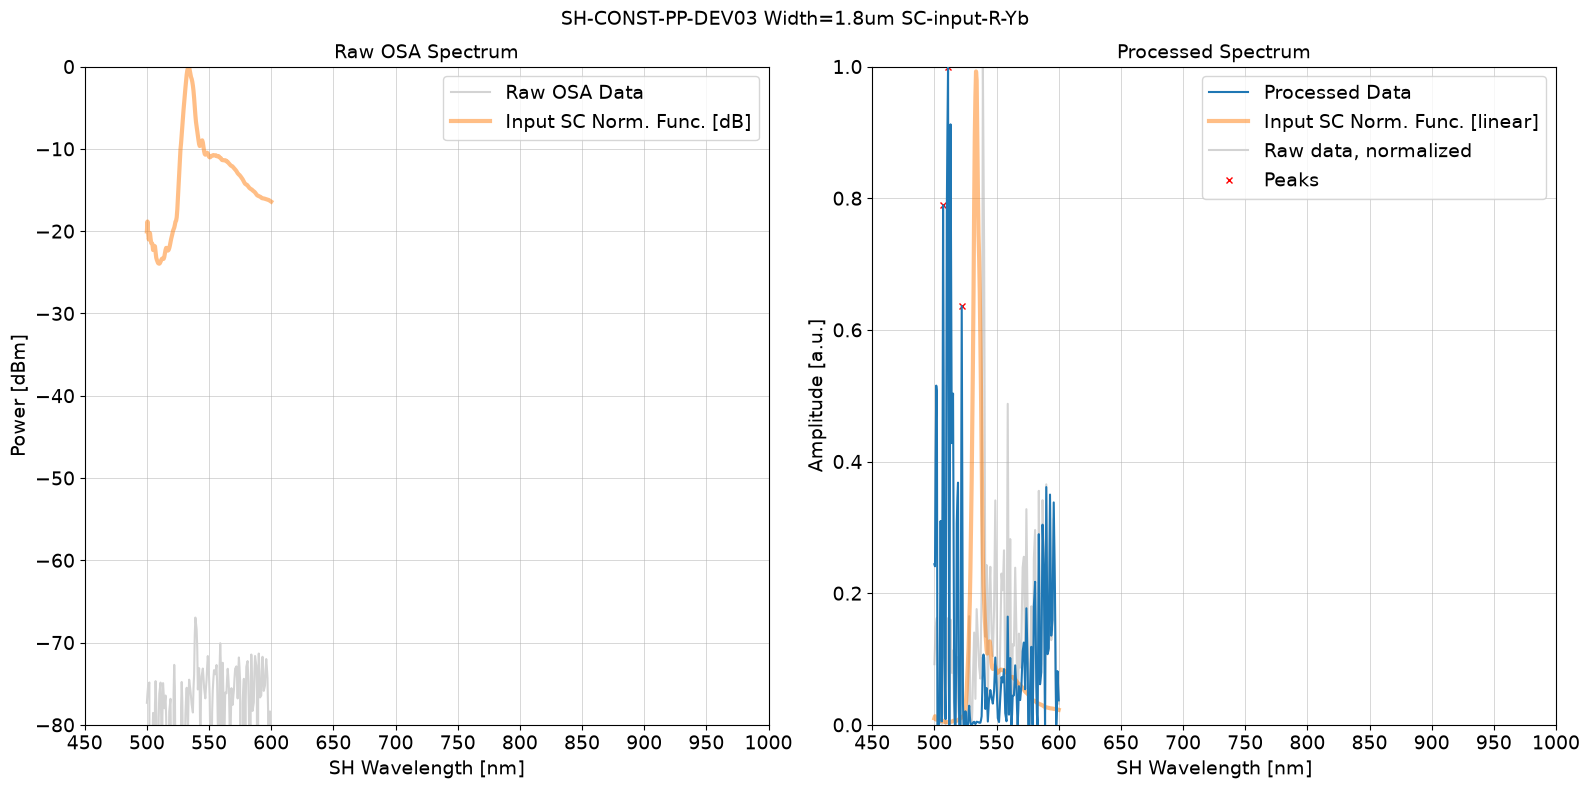

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV04_WIDTH-1.8um_REFL-50.0dBm_SHI2_SC-input-R-Yb_04-30-2026-14-18-36.csv


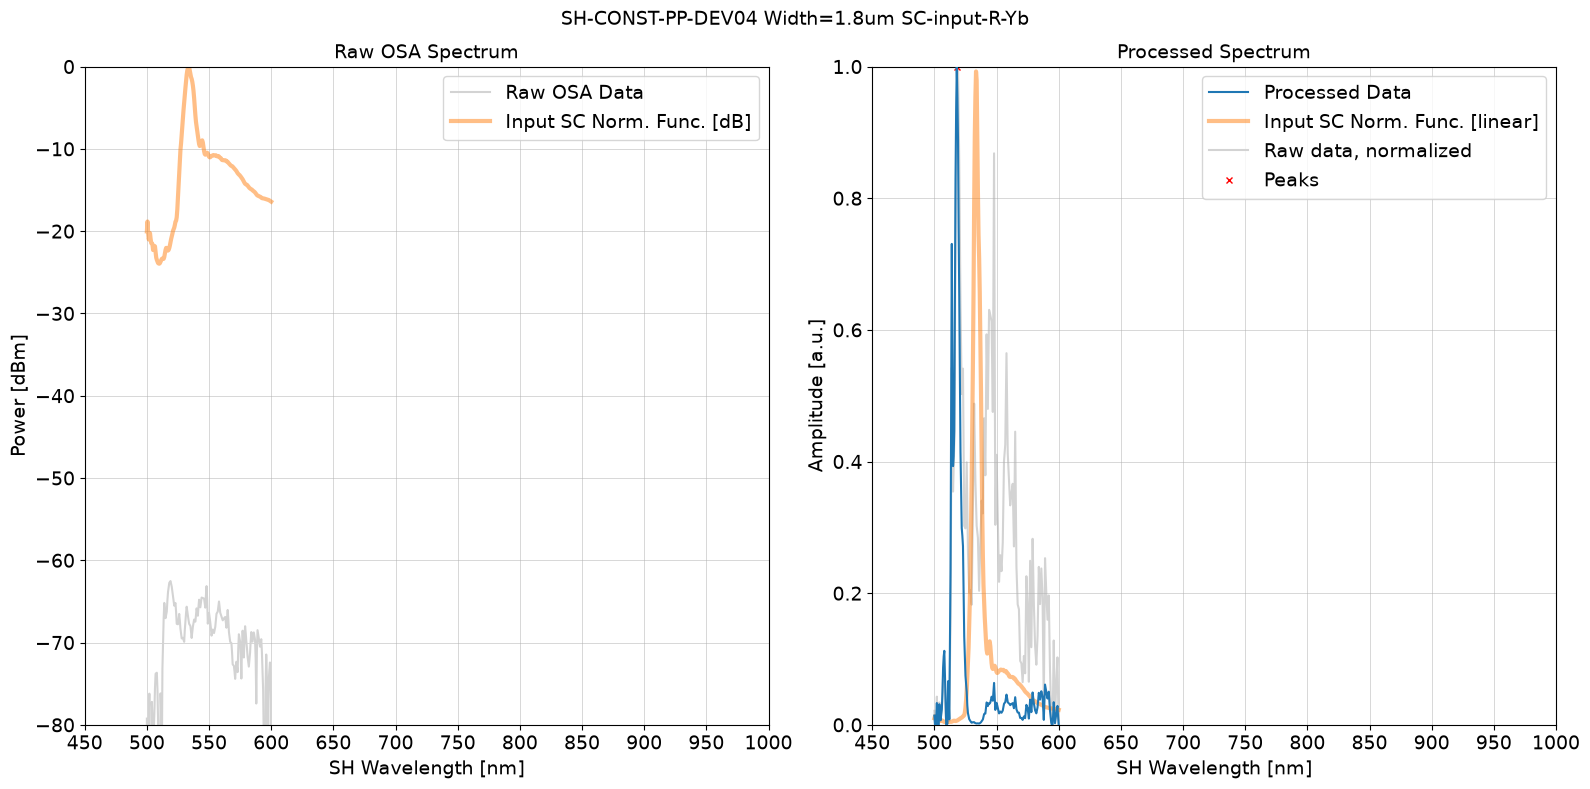

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV05_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-15-47-29.csv


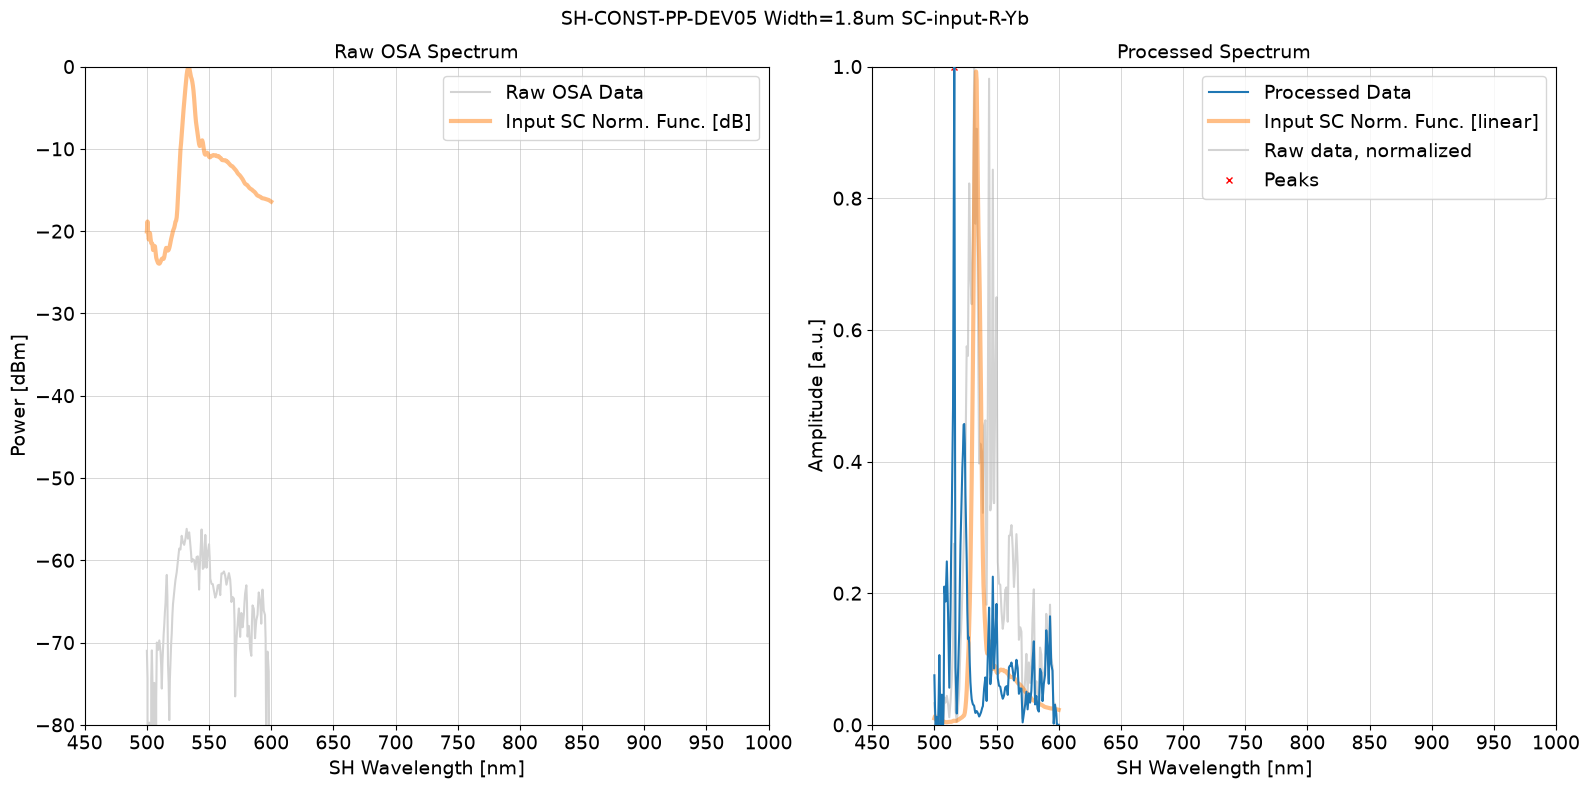

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV06_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-16-02-29.csv


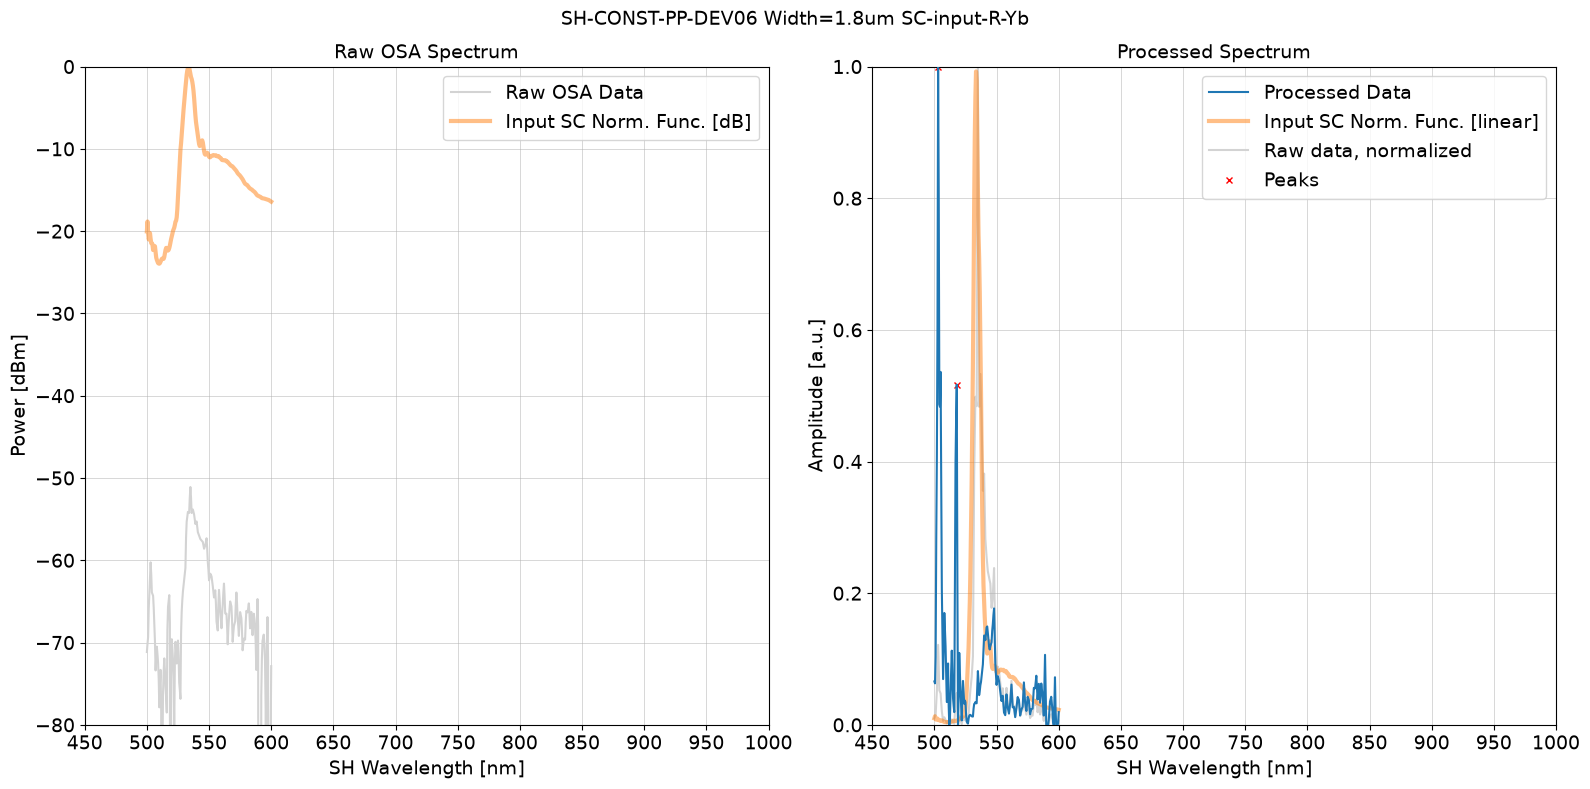

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV07_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-16-16-53.csv


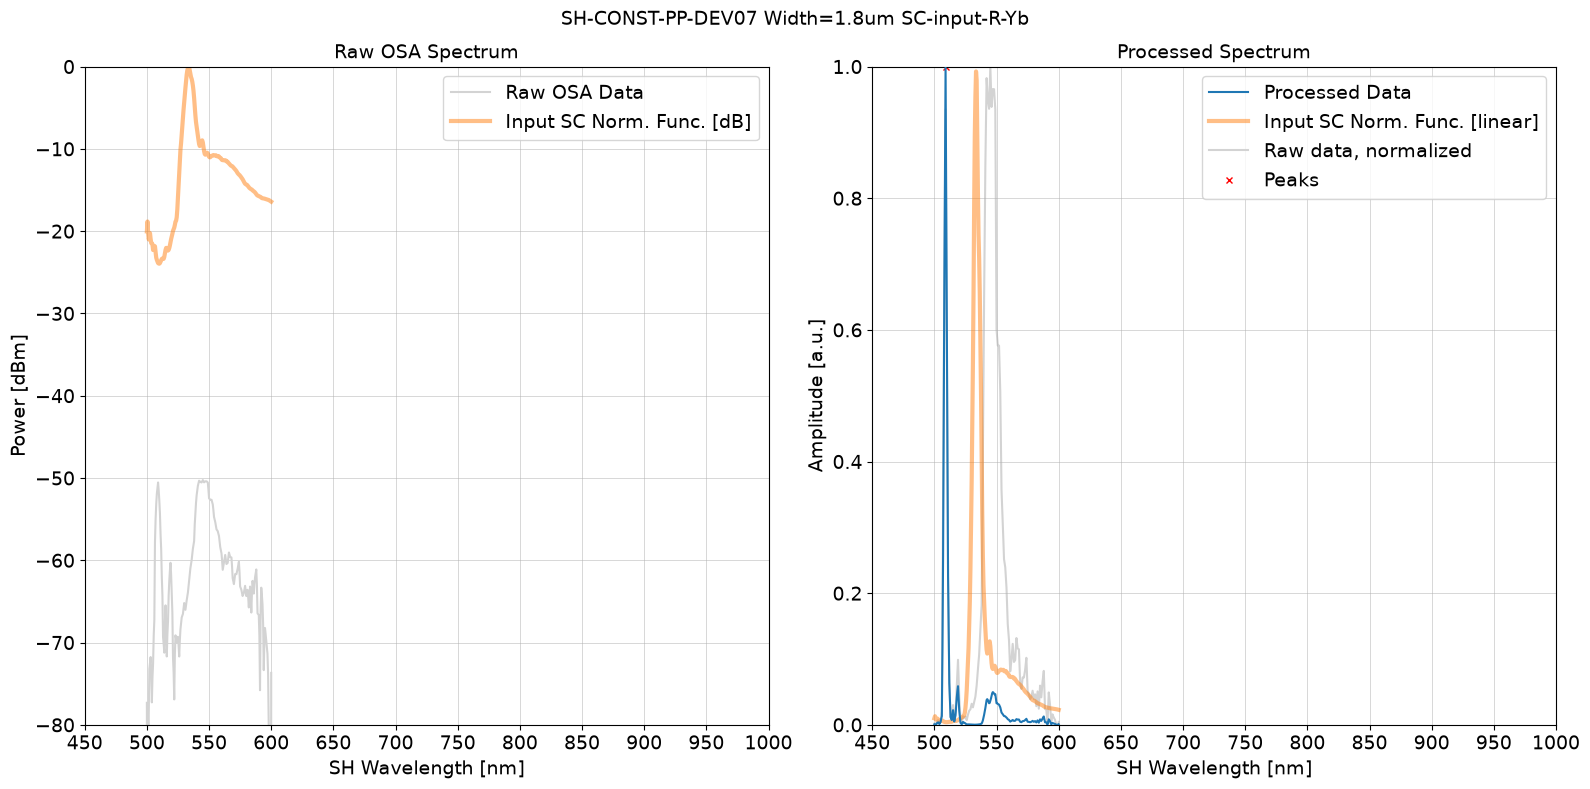

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV08_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-16-38-01.csv


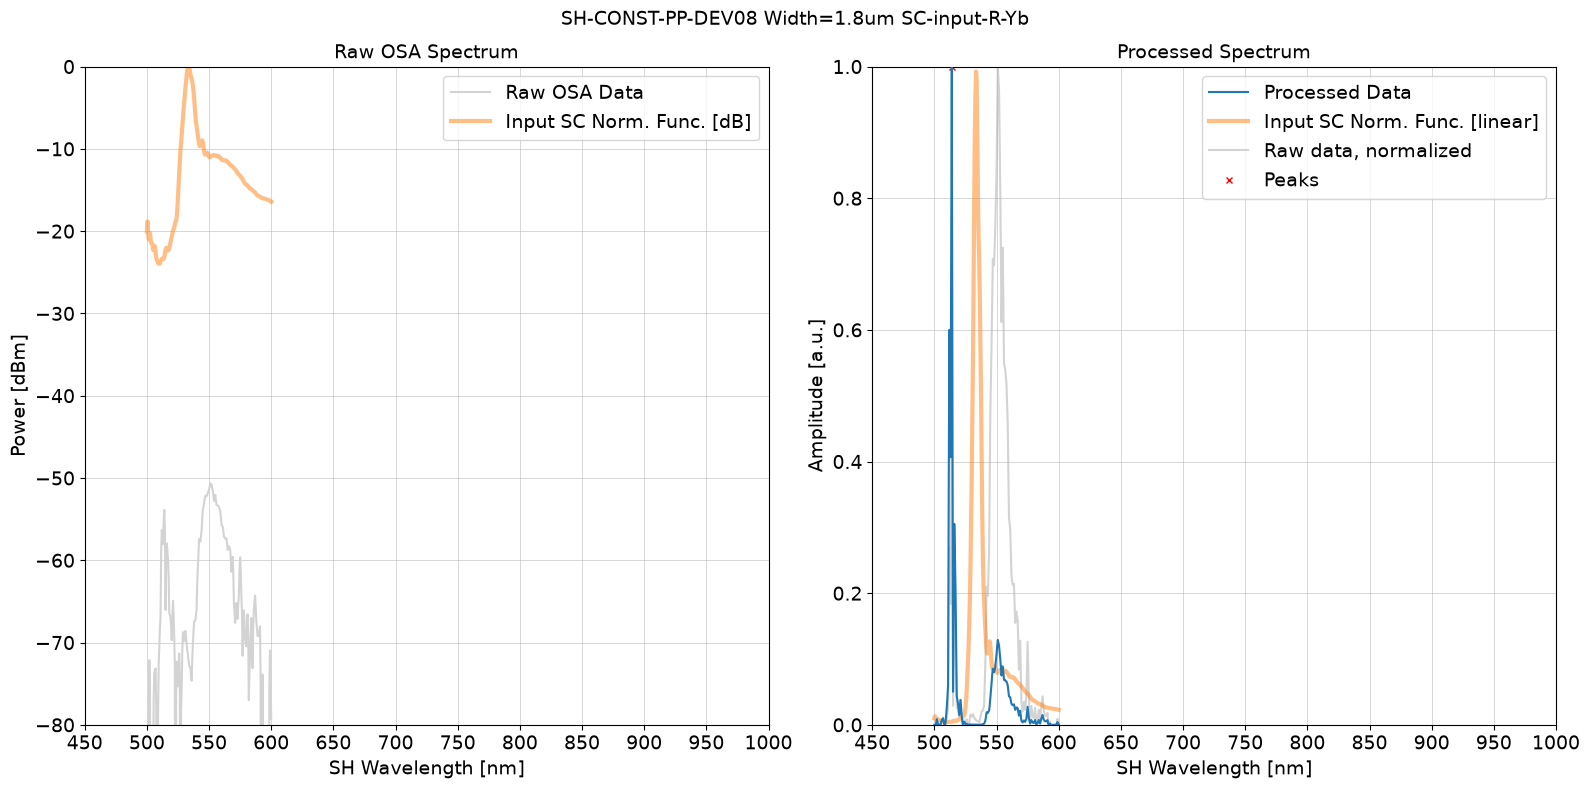

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV09_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-16-53-34.csv


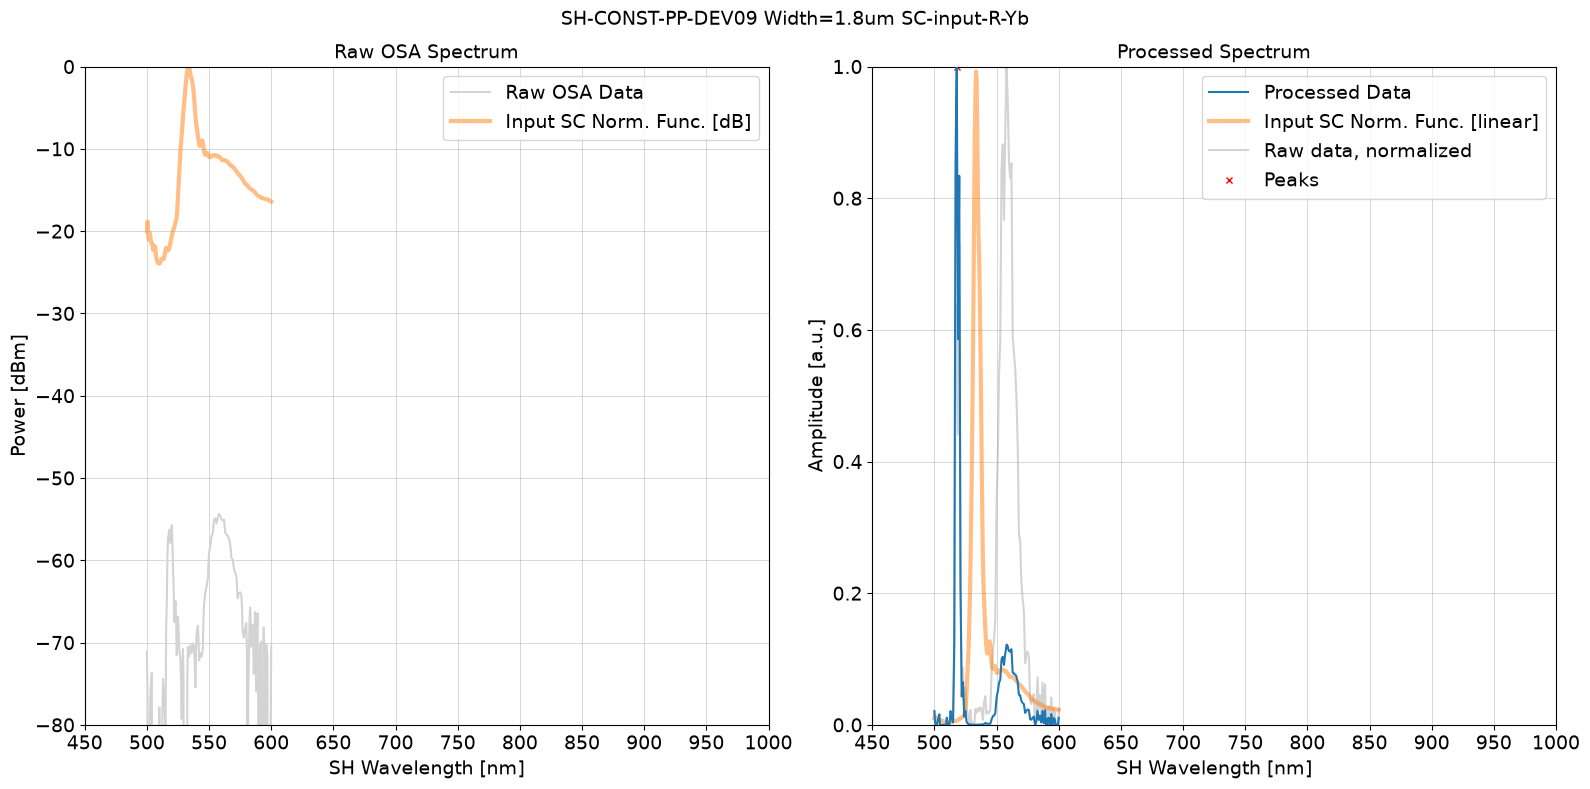

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV10_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-17-10-51.csv


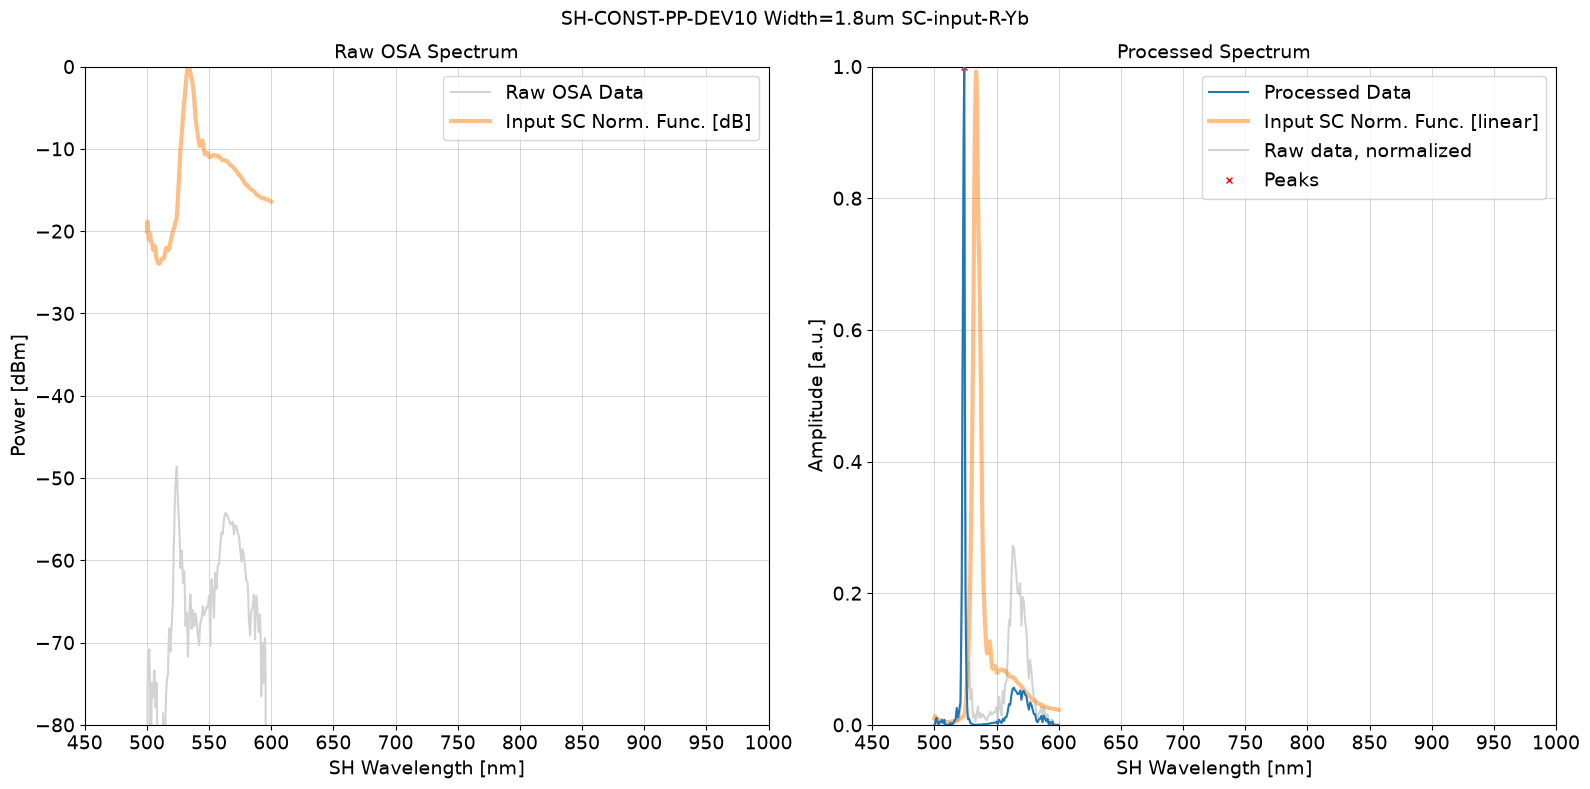

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV11_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-17-28-31.csv


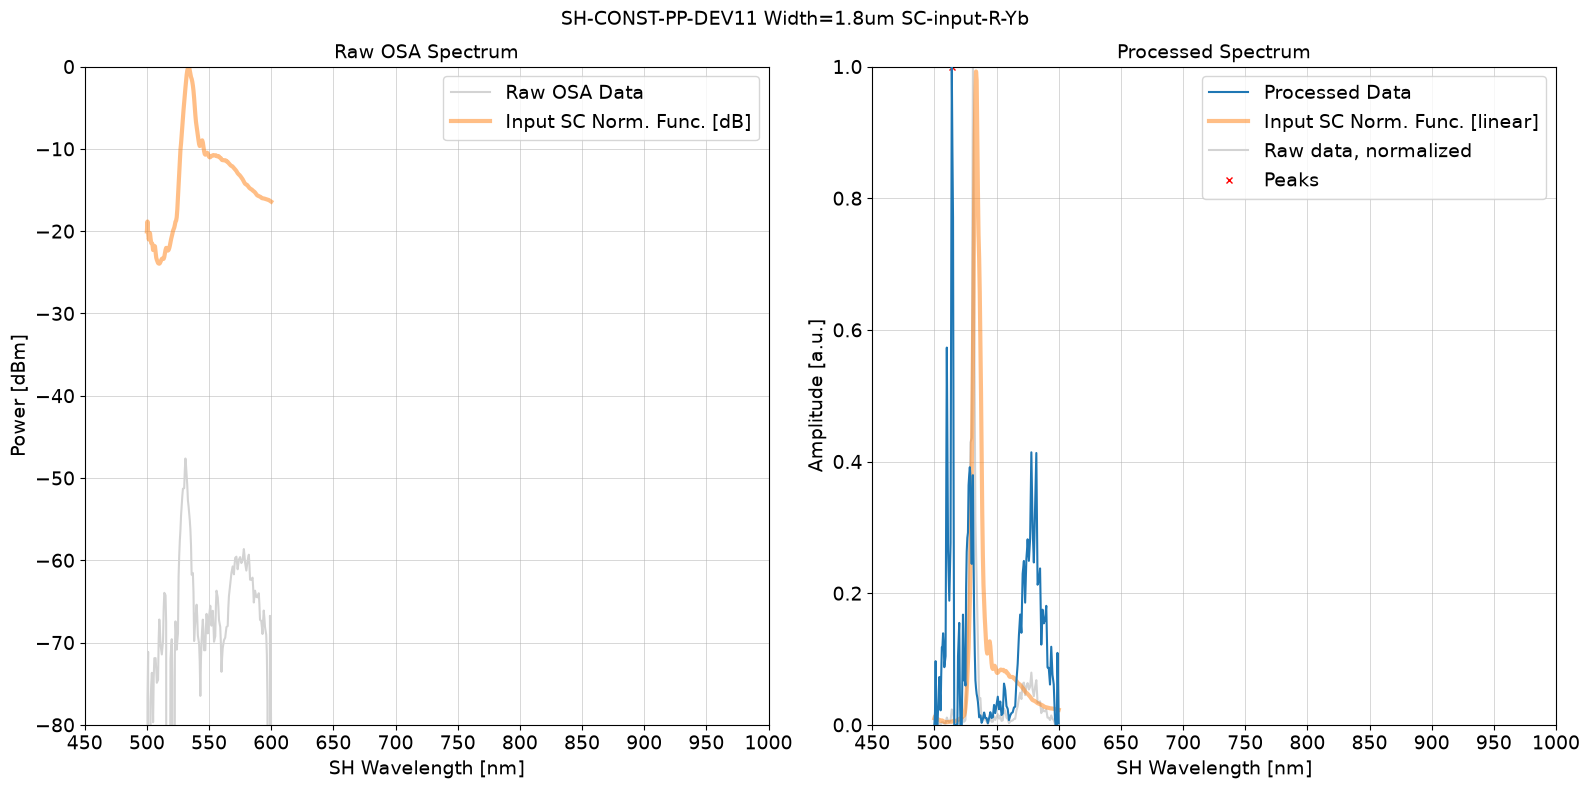

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV12_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-17-42-35.csv


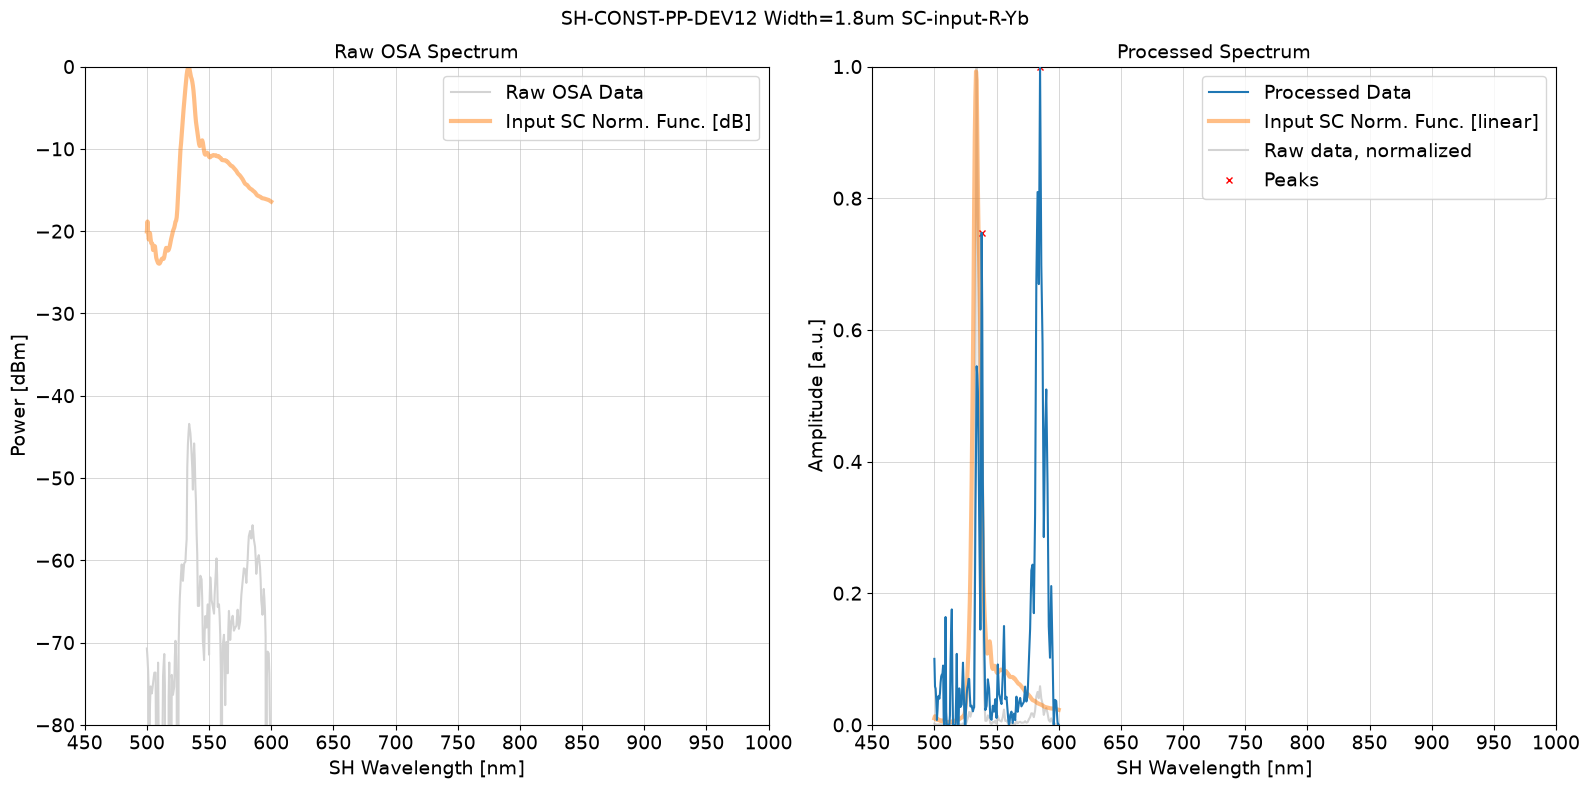

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV13_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-17-58-07.csv


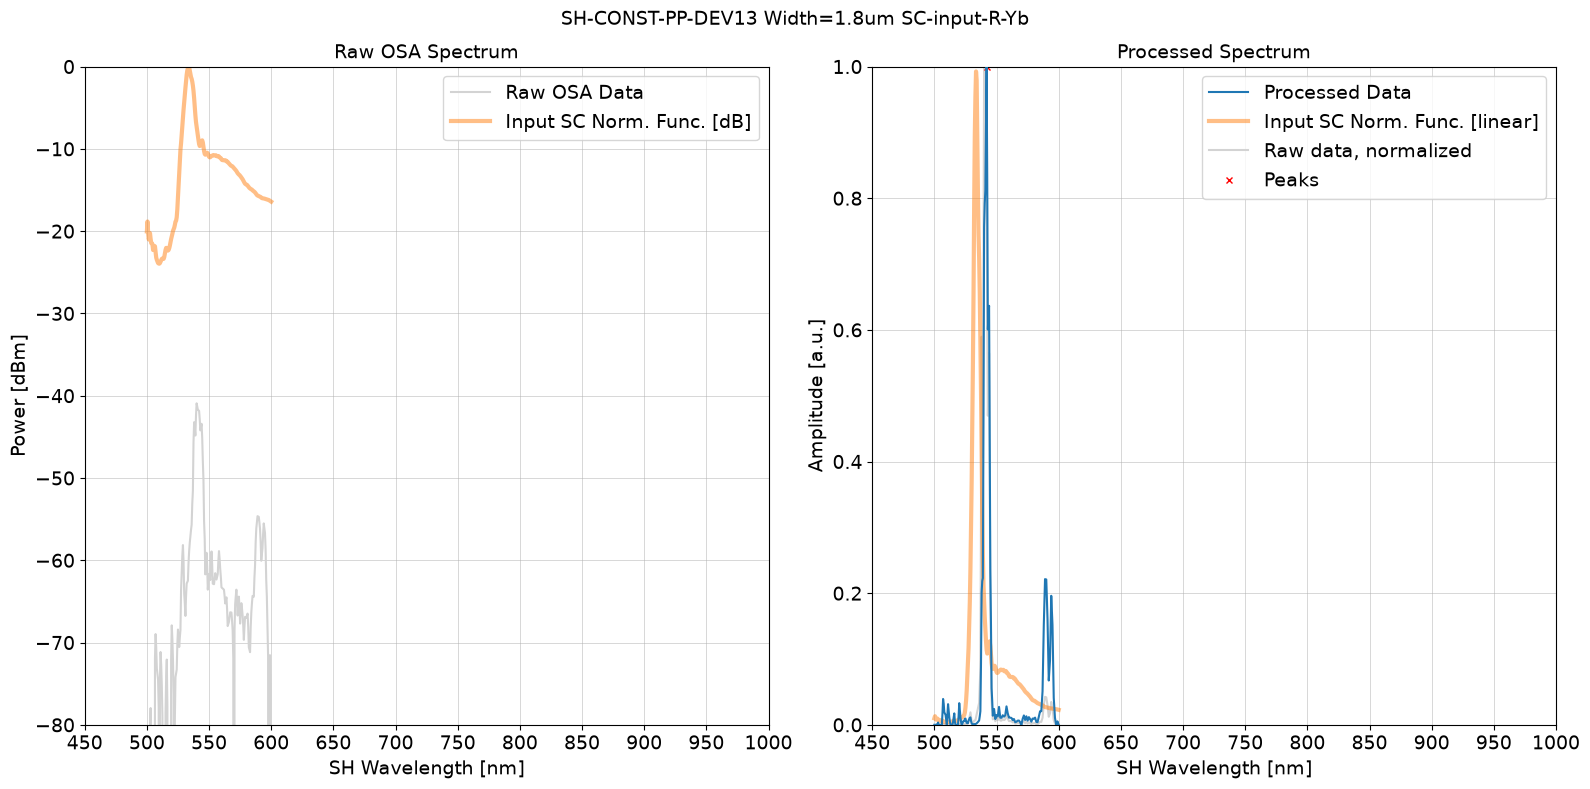

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV14_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-18-12-46.csv


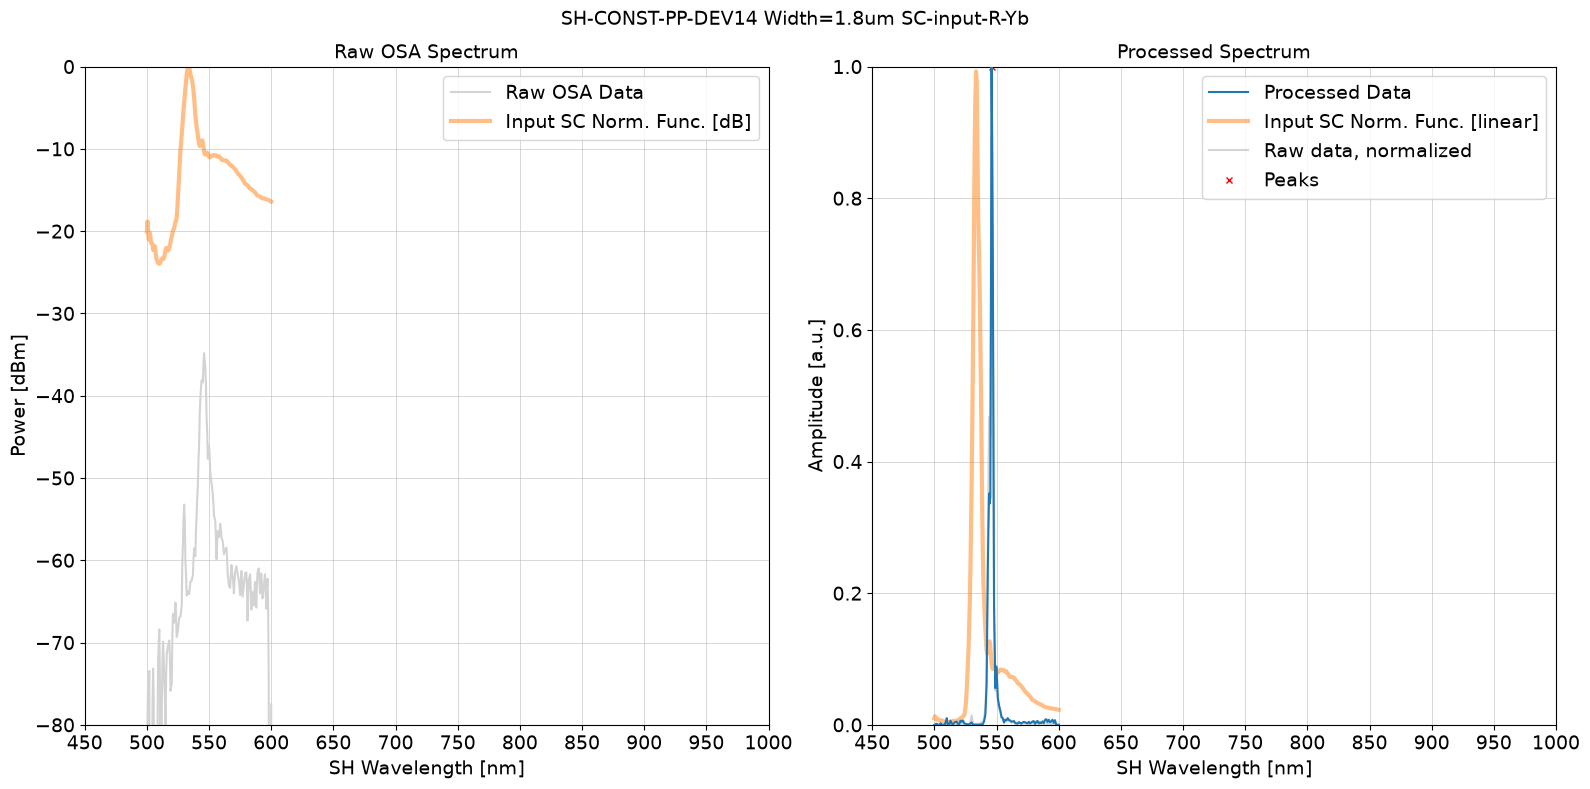

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV15_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-18-36-13.csv


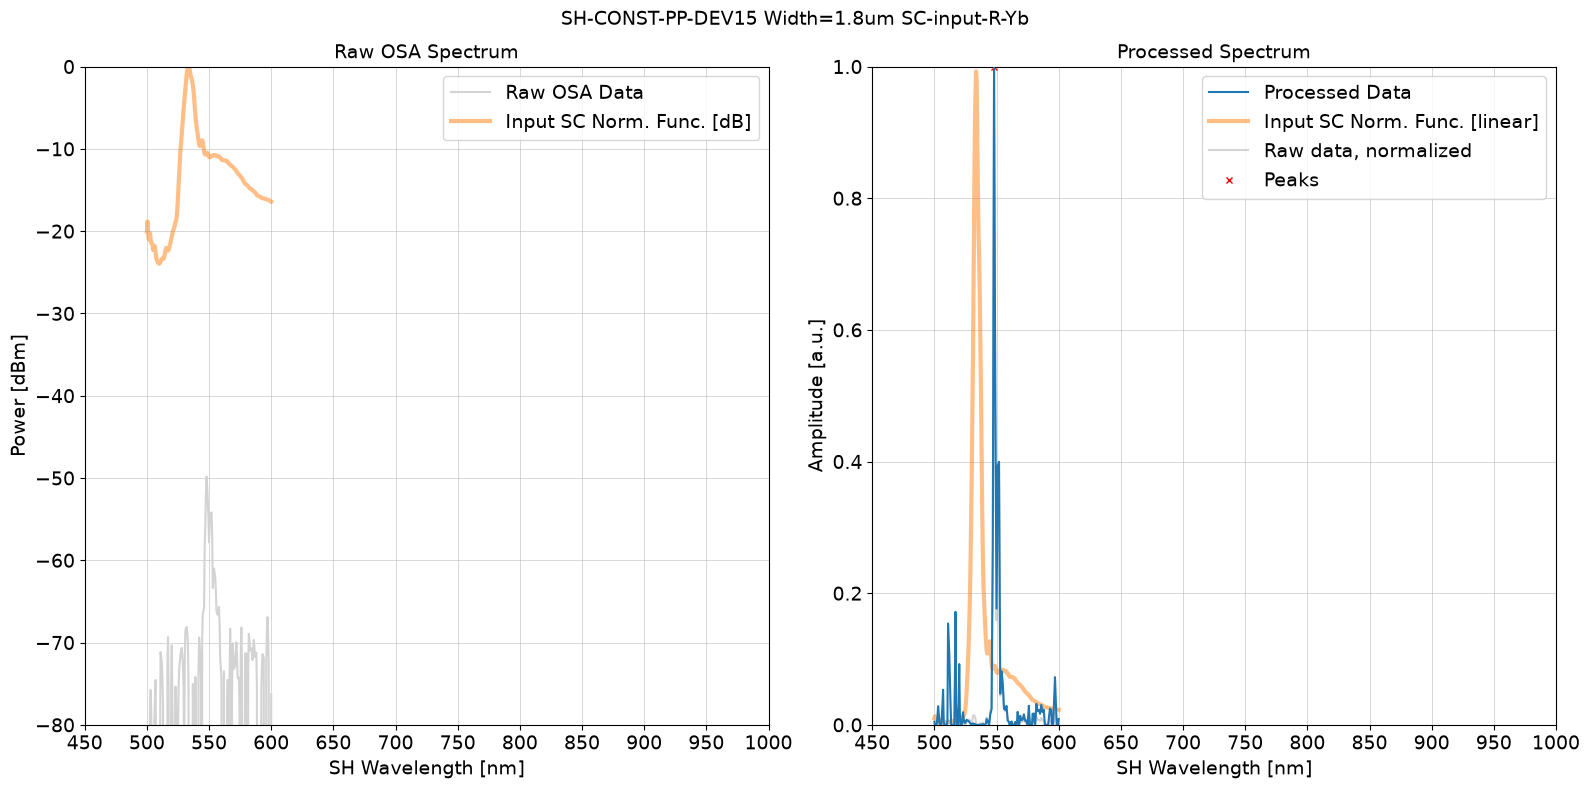

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV16_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-18-49-03.csv


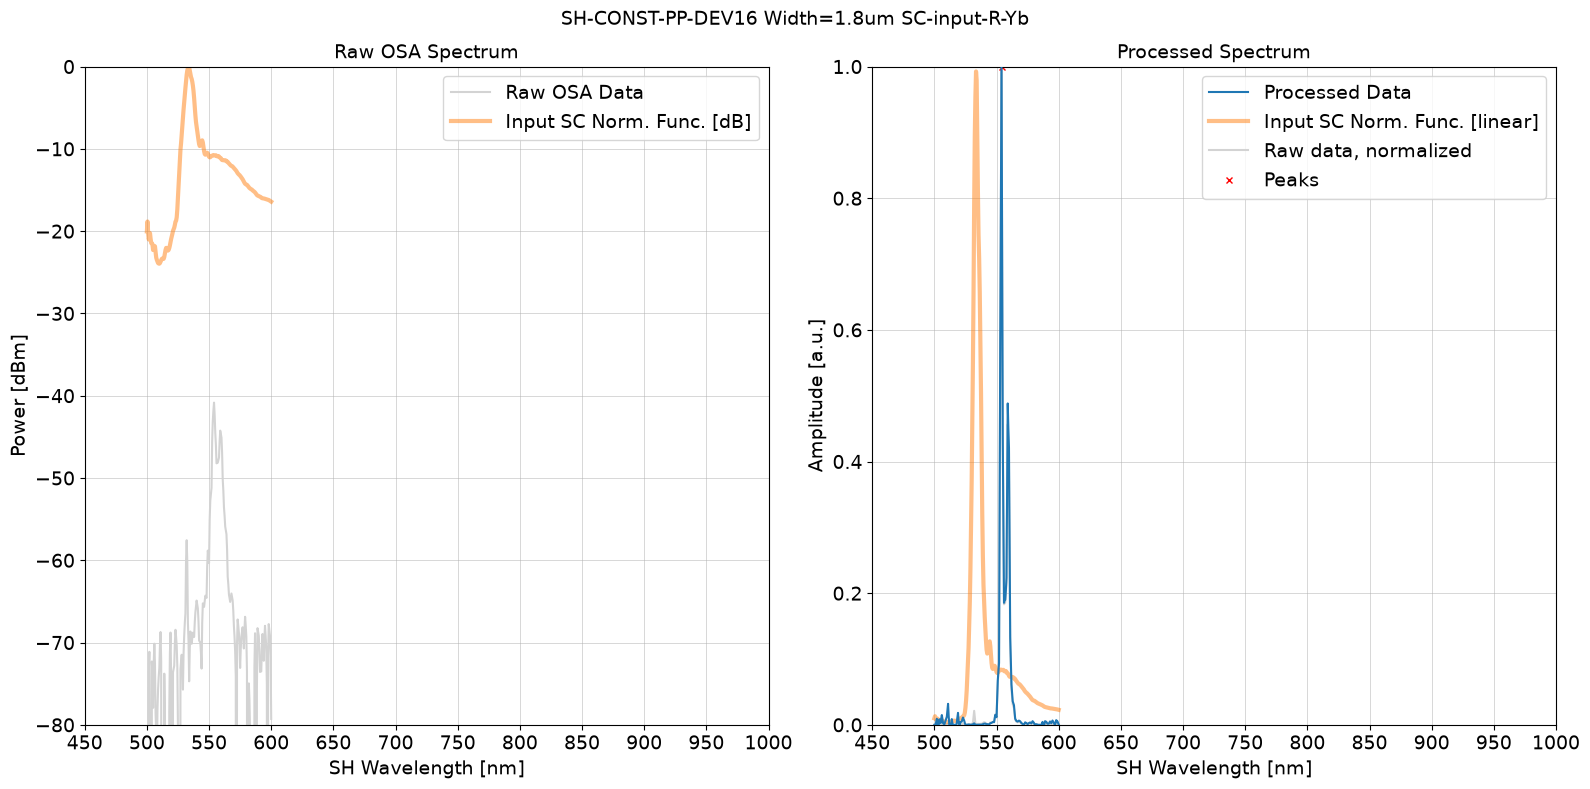

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV17_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-19-01-38.csv


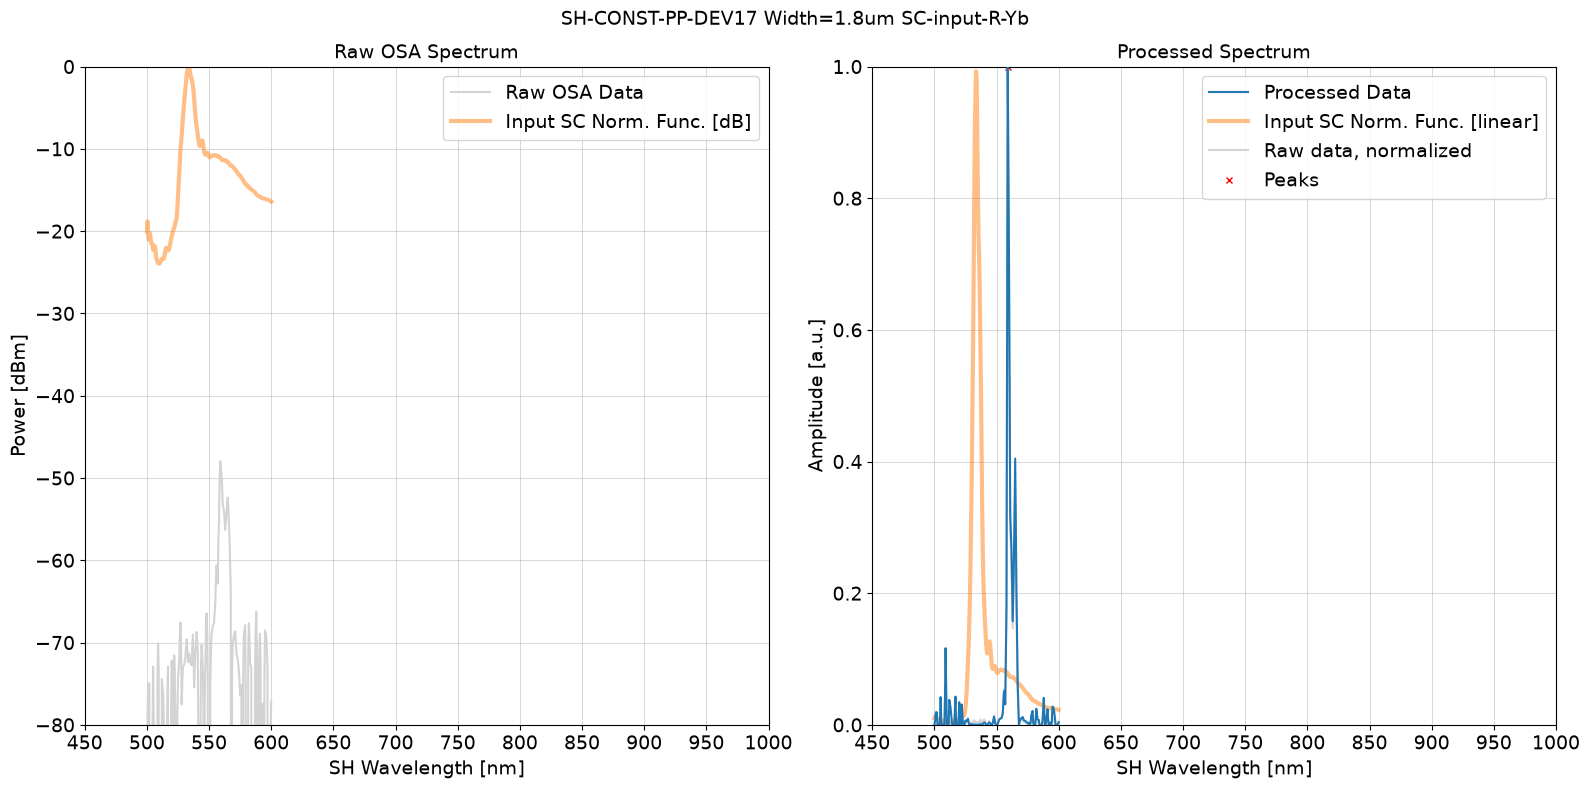

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV18_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-19-12-30.csv


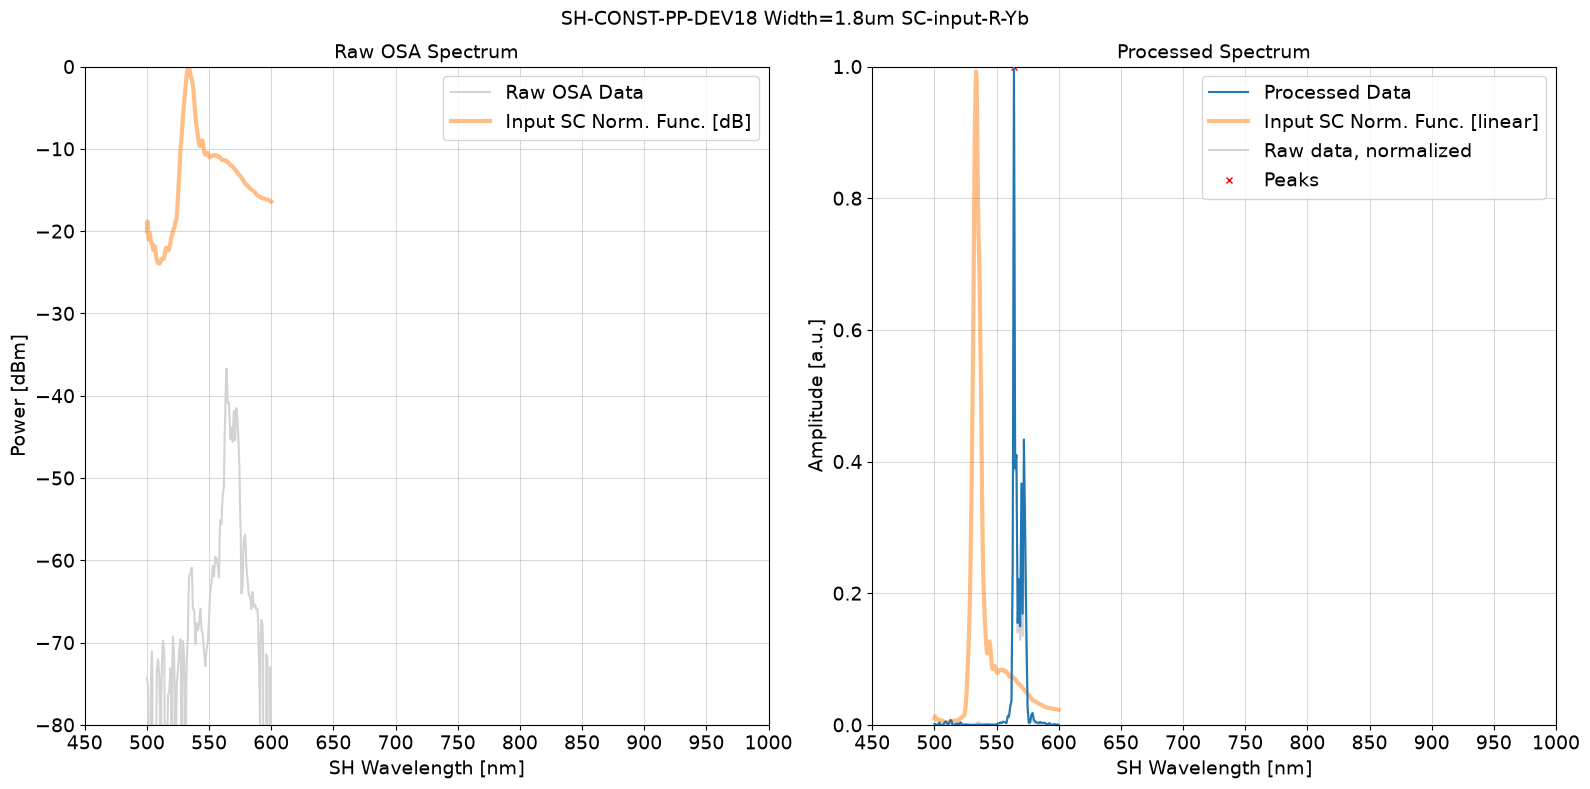

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV19_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-19-26-19.csv


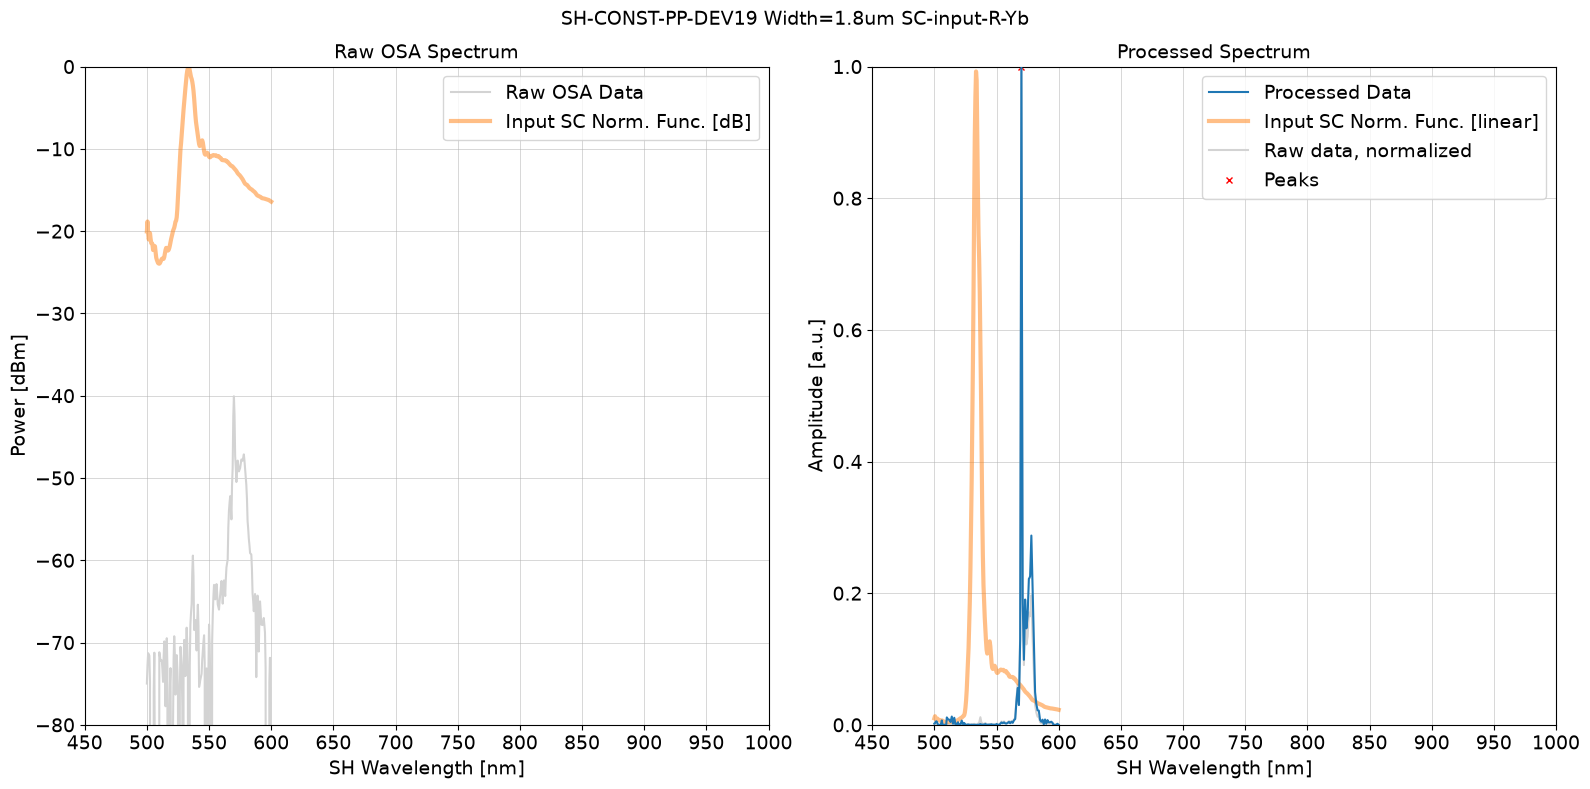

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV20_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-19-38-19.csv


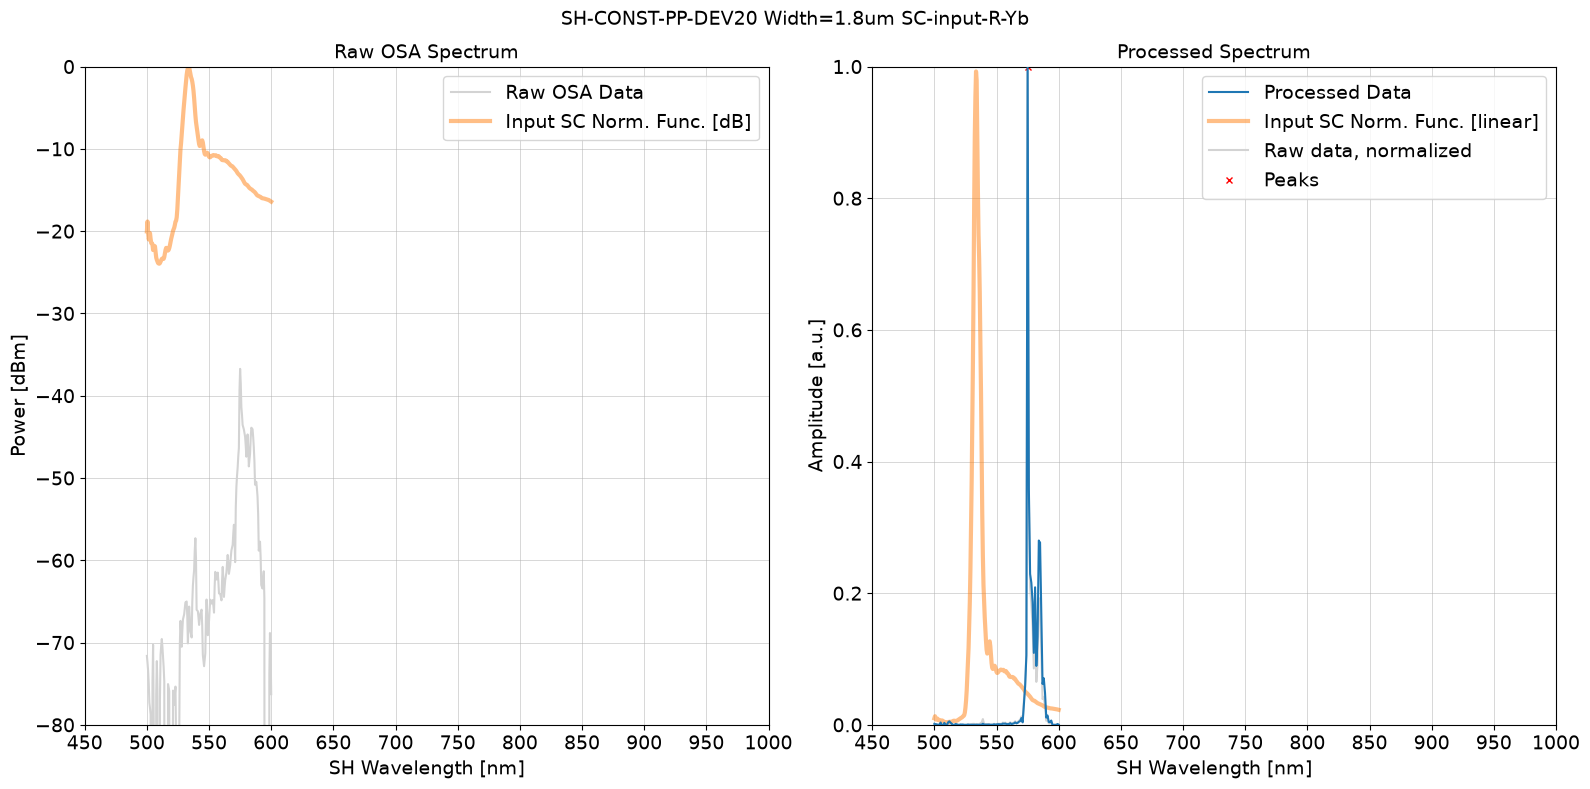

Plotting C:/Users/Sagar/MIT Dropbox/Sagar Doshi/LN-NLO/poling-waveguide-shg/Praevium_2799/SC_QPM_Spectra_Ando_OSA_TE_22C_InObj_NIR_OutObj_VIS_FESH0950_GIF50E_04-30-2026\SH-CONST-PP-DEV21_WIDTH-1.8um_REFL-50.0dBm_SHI1_SC-input-R-Yb_04-30-2026-19-52-35.csv


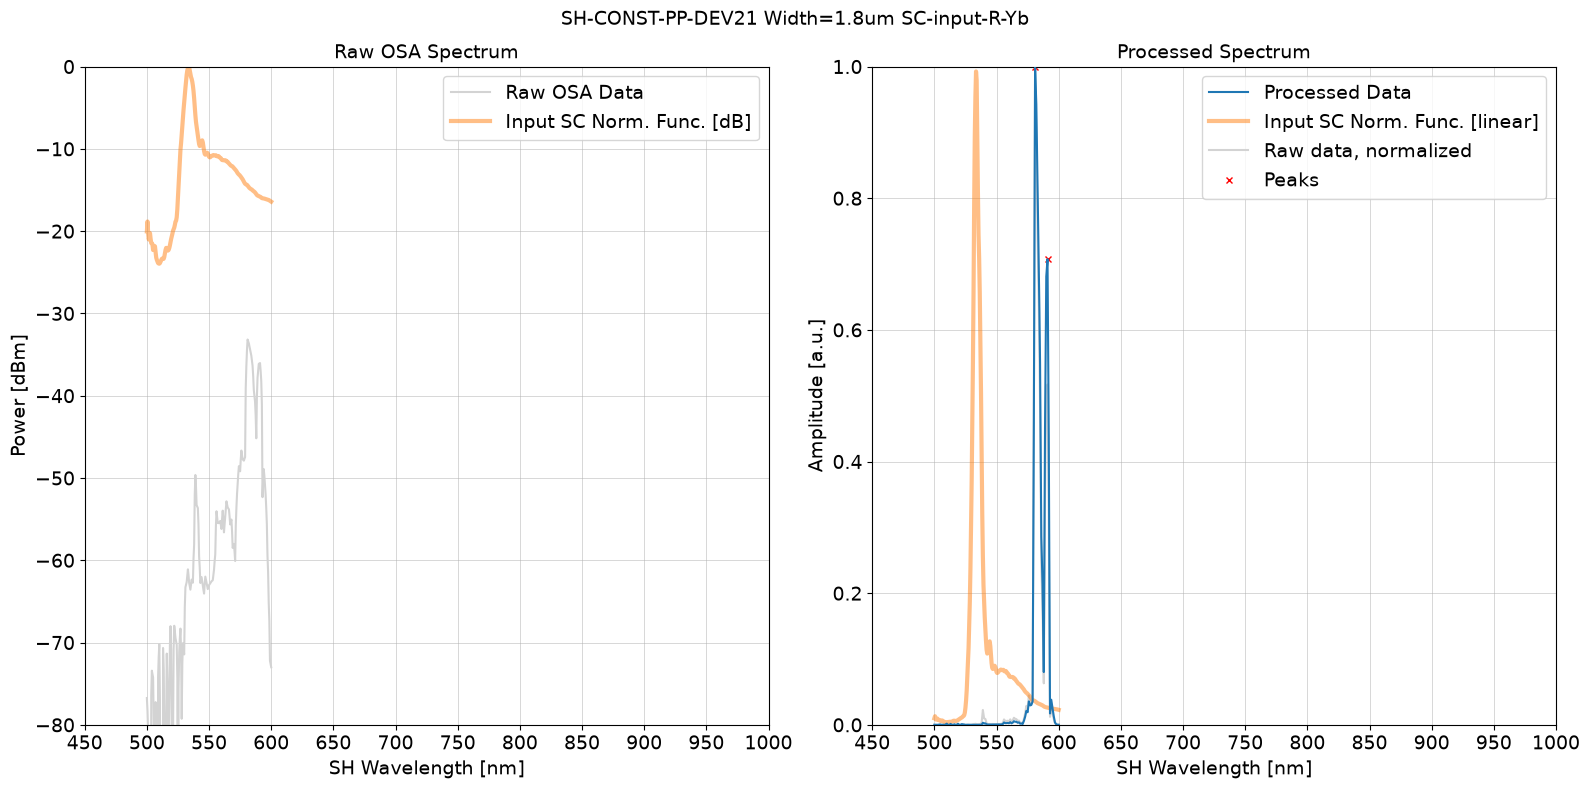

In [67]:
DevID_of_interest       = "SH-CONST-PP" # 3-constant-PP devices
SCInputType_of_interest = "SC-input-R-Yb" # "SC-input-R-Yb", "SC-input-R-O", "SC-input-R-C", "SC-input-R-NIR"
WIDTH_of_interest       = "1.8um" # "1.8um", "1.6um"
df_filtered = df_sc_qpm_data[(df_sc_qpm_data['DevID'] == DevID_of_interest) & (df_sc_qpm_data['SCInputType'] == SCInputType_of_interest) & (df_sc_qpm_data['TopWidth'] == WIDTH_of_interest)]

if SCInputType_of_interest == "SC-input-R-Yb": 
    trunc_range = TRUNC_RANGE_YB
    loc = "upper right"
    norm_to_sc = True
    # prominence = 0.2 # Tested these on Width=1.8um AND Width=1.6um, seems to work well for both
    prominence = 0.5 # Tested these on Width=1.8um AND Width=1.6um, seems to work well for both
    distance=5
elif SCInputType_of_interest == "SC-input-R-O":
    trunc_range = TRUNC_RANGE_O
    loc = "upper right"
    norm_to_sc = True
    prominence = 0.5 # Tested these on Width=1.8um AND Width=1.6um, seems to work well for both
    distance=5
elif SCInputType_of_interest == "SC-input-R-C":
    trunc_range = TRUNC_RANGE_C
    loc = "upper left"
    norm_to_sc = True # NOTE - for the C-band data set anything below -70dBm to -300dBm, to avoid amplifying noise. 
    prominence = 0.5 # Tested these on Width=1.8um AND Width=1.6um, seems to work well for both
    distance=5
elif SCInputType_of_interest == "SC-input-R-NIR":
    trunc_range = TRUNC_RANGE_NIR
    loc = "upper left"
    norm_to_sc = True # Don't normalize to SC for C-band devices since SC power is very low in this range and normalization just amplifies noise
    prominence = 0.5 # Tested these on Width=1.8um AND Width=1.6um, seems to work well for both
    distance=5

for idx, row in df_filtered.iterrows():
    print(f"Plotting {row['fpath']}")
    df_spectrum = pd.read_csv(row['fpath'])
    wavs, amps_dBm = df_spectrum['Wavelength (nm)'].values, df_spectrum['Power (dBm)'].values 
    if SCInputType_of_interest == "SC-input-R-C" or SCInputType_of_interest == "SC-input-R-NIR":
        amps_dBm = np.where(amps_dBm < -69, -300, amps_dBm) # For C-band devices, set anything below -70dBm to -300dBm to avoid amplifying noise in the normalization and peak finding steps. Adjust threshold as needed based on noise floor.
    amps_linear = 10**(amps_dBm/10)

    # Truncate to ROI
    idx1, idx2  = find_nearest(wavs, trunc_range[0]/2.0), find_nearest(wavs, trunc_range[1]/2.0)
    wavs        = wavs[idx1:idx2+1]
    amps_dBm    = amps_dBm[idx1:idx2+1]
    amps_linear = amps_linear[idx1:idx2+1]
    
    sc_input_norm_dB     = input_sc_func_stitched_dB(wavs)*2
    sc_input_norm_linear = input_sc_func_stitched_linear(wavs)**2

    amps_linear_norm = amps_linear - np.min(amps_linear)
    amps_linear_norm = amps_linear_norm / np.max(amps_linear_norm) # Normalize to max of 1

    if norm_to_sc:
        amps_linear_norm_to_sc = amps_linear / sc_input_norm_linear
    else:
        amps_linear_norm_to_sc = amps_linear

    amps_linear_norm_to_sc = amps_linear_norm_to_sc - np.min(amps_linear_norm_to_sc) 
    amps_linear_norm_to_sc = amps_linear_norm_to_sc / np.max(amps_linear_norm_to_sc) # Normalize to max of 1

    pks, properties = find_peaks(amps_linear_norm_to_sc, prominence=prominence, distance=distance) # Adjust height and distance thresholds as needed based on expected peak characteristics

    fig, axs = plt.subplots(1, 2, figsize=(16, 8), tight_layout=True, sharex=True)

    fig.suptitle(f"{row['DevID']}-DEV{row['DevNum']} Width={row['TopWidth']} {SCInputType_of_interest}", fontsize=label_fs)

    axs[0].plot(wavs, amps_dBm, linewidth=1.5, color='lightgray', label="Raw OSA Data")
    axs[0].plot(wavs, sc_input_norm_dB, linewidth=3.0, color='tab:orange', label='Input SC Norm. Func. [dB]', alpha=0.5, zorder=2)

    axs[0].set_title("Raw OSA Spectrum", fontsize=label_fs)
    axs[0].set_xlabel("SH Wavelength [nm]", fontsize=label_fs)
    axs[0].set_ylabel("Power [dBm]", fontsize=label_fs)
    axs[0].tick_params(which='both', labelsize=tick_fs)

    axs[0].set_xticks(np.arange(WL_MIN_SH, WL_MAX_SH+1, 50))
    axs[0].set_xlim(WL_MIN_SH, WL_MAX_SH)

    axs[0].grid(True, which='both', linestyle='-', linewidth=0.5, alpha=0.7)

    axs[0].set_ylim(-80, 0)

    axs[0].legend(fontsize=legend_fs, loc=loc)

    # Linear, normalized scale
    axs[1].plot(wavs, amps_linear_norm_to_sc, linewidth=1.5, color='tab:blue', zorder=10, label='Processed Data')
    axs[1].plot(wavs, sc_input_norm_linear, linewidth=3.0, color='tab:orange', label='Input SC Norm. Func. [linear]', alpha=0.5, zorder=2)
    axs[1].plot(wavs, amps_linear_norm, linewidth=1.5, color='lightgray', label='Raw data, normalized', zorder=1)

    axs[1].plot(wavs[pks], amps_linear_norm_to_sc[pks], 'x', color='red', label='Peaks', markersize=5)

    axs[1].set_title("Processed Spectrum", fontsize=label_fs)
    axs[1].set_xlabel("SH Wavelength [nm]", fontsize=label_fs)
    axs[1].set_ylabel("Amplitude [a.u.]", fontsize=label_fs)
    axs[1].tick_params(which='both', labelsize=tick_fs)

    ymin, ymax, ystep = 0.0, 1.0, 0.2
    axs[1].set_yticks(np.arange(ymin, ymax+ystep/2.0, ystep))
    axs[1].set_ylim(ymin, ymax)

    axs[1].grid(True, which='both', linestyle='-', linewidth=0.5, alpha=0.7)

    axs[1].legend(fontsize=legend_fs, loc=loc)

    plt.show()

#### Make the dispersion modeling error plots

In [ ]:
DevID_of_interest            = "SH-CONST-PP" # 3-constant-PP devices
SCInputType_of_interest_list = ["SC-input-R-Yb", "SC-input-R-O", "SC-input-R-C"]
WG_Width_of_interest_list    = ["1.8um", "1.6um"]

# Keys   = "DEV{DevNum}-{WG_Width}-{SCInputType}", ex: DEV01-1.6um-Yb - this uniquely identifies a constant-PP, 4mm-long device on 2799
# Values = (pk_wavs_SH_nm, pk_heights)
device_meas_pks_dict = dict()

for WG_Width in WG_Width_of_interest_list:
    df_filtered = df_sc_qpm_data[(df_sc_qpm_data['DevID'] == DevID_of_interest) & (df_sc_qpm_data['TopWidth'] == WG_Width)]

    for idx, row in df_filtered.iterrows():
        SCInputType_of_interest = row['SCInputType']

        if SCInputType_of_interest == "SC-input-R-Yb": 
            trunc_range = TRUNC_RANGE_YB
            loc = "upper right"
            norm_to_sc = True
            prominence = 0.5 # Tested these on Width=1.8um AND Width=1.6um, seems to work well for both
            distance=5
        elif SCInputType_of_interest == "SC-input-R-O":
            trunc_range = TRUNC_RANGE_O
            loc = "upper right"
            norm_to_sc = True
            prominence = 0.5 # Tested these on Width=1.8um AND Width=1.6um, seems to work well for both
            distance=5
        elif SCInputType_of_interest == "SC-input-R-C":
            trunc_range = TRUNC_RANGE_C
            loc = "upper left"
            norm_to_sc = True 
            prominence = 0.5 # Tested these on Width=1.8um AND Width=1.6um, seems to work well for both
            distance=5
        elif SCInputType_of_interest == "SC-input-R-NIR":
            continue # Skip this data (see note above, not useful)

        # print(f"Processing {row.fpath.split('/')[-1]}")
        df_spectrum = pd.read_csv(row['fpath'])
        wavs, amps_dBm = df_spectrum['Wavelength (nm)'].values, df_spectrum['Power (dBm)'].values 
        if SCInputType_of_interest == "SC-input-R-C" or SCInputType_of_interest == "SC-input-R-NIR":
            amps_dBm = np.where(amps_dBm < -69, -300, amps_dBm) # For C-band devices, set anything below -70dBm to -300dBm to avoid amplifying noise in the normalization and peak finding steps. Adjust threshold as needed based on noise floor.
        amps_linear = 10**(amps_dBm/10)

        # Truncate to ROI
        idx1, idx2  = find_nearest(wavs, trunc_range[0]/2.0), find_nearest(wavs, trunc_range[1]/2.0)
        wavs        = wavs[idx1:idx2+1]
        amps_dBm    = amps_dBm[idx1:idx2+1]
        amps_linear = amps_linear[idx1:idx2+1]
        
        sc_input_norm_dB     = input_sc_func_stitched_dB(wavs)*2
        sc_input_norm_linear = input_sc_func_stitched_linear(wavs)**2

        amps_linear_norm = amps_linear - np.min(amps_linear)
        amps_linear_norm = amps_linear_norm / np.max(amps_linear_norm) # Normalize to max of 1

        if norm_to_sc:
            amps_linear_norm_to_sc = amps_linear / sc_input_norm_linear
        else:
            amps_linear_norm_to_sc = amps_linear

        amps_linear_norm_to_sc = amps_linear_norm_to_sc - np.min(amps_linear_norm_to_sc) 
        amps_linear_norm_to_sc = amps_linear_norm_to_sc / np.max(amps_linear_norm_to_sc) # Normalize to max of 1

        pks, properties = find_peaks(amps_linear_norm_to_sc, prominence=prominence, distance=distance) # Adjust height and distance thresholds as needed based on expected peak characteristics

        pk_wavs    = wavs[pks]
        pk_heights = amps_linear_norm_to_sc[pks]

        k = f"DEV{row['DevNum']}-{row['TopWidth']}-{SCInputType_of_interest.split('-')[-1]}" # Key format: DEV{DevNum}-{WG_Width}-{SCInputType}, ex: DEV01-1.6um-Yb - this uniquely identifies a constant-PP, 4mm-long device on 2799
        device_meas_pks_dict[k] = (pk_wavs, pk_heights)

In [73]:
# ---- Config ----
T_LN_NM        = 400                                          # Assume every device has the nominal LN film thickness (for now)
FH_RANGE_NM    = (800, 2000)                                  # FH window for Delta_k
SH_RANGE_NM    = (FH_RANGE_NM[0]/2.0, FH_RANGE_NM[1]/2.0)     # SH window follows from the FH window
DLAM_FINE_NM   = 0.1                                          # Fine FH grid that the 10nm-spaced solver data is splined onto

PLOT_DESIGN_QPM_V_WAV = False                                 # Plot the design QPM wavelength for every measured device

# ---- Edge case: C-input peaks that are really the O-band poling section's TE00->TE00 peak ----
# For W = 1.6um DEV15-21, the O section's peak (~705-752nm SH) sits past the O-input window (SH 600-710nm) and inside the
# C-input window (SH 700-1000nm), where it outshines the weak C-section peak. So for those devices:
#   - the C-input peak is compared against the O-band poling period (PP_CHUNK_2) instead of PP_CHUNK_3
#   - the O-input data is left out (the real O peak is outside the O window, so its peaks are some other feature)
PP_CHUNK_OVERRIDE = {f"DEV{d}-1.6um-C": "PP_CHUNK_2" for d in range(15, 22)} # Key -> PP column used instead of CHUNK_BAND_MAP[band]
# OMIT_KEYS         = {f"DEV{d}-1.6um-O" for d in range(15, 22)}               # Measured data left out of device_design_pks_dict and the plots
OMIT_KEYS         = OMIT_KEYS = ({f"DEV{d}-1.6um-O" for d in range(15, 22)} | {"DEV14-1.6um-O", "DEV20-1.8um-O", "DEV21-1.8um-O" } | {f"DEV{d:02d}-{w}-Yb" for d in (3, 4, 5) for w in ("1.6um", "1.8um")} | {"DEV11-1.8um-Yb", "DEV12-1.8um-Yb"})

def get_modes_fpath(t_ln_nm, w_top_nm):
    '''Return the _modes.csv path in MODE_DATA_SWEEP_FPATHS for a given LN thickness and top width (both in nm).'''
    matches = [f for f in MODE_DATA_SWEEP_FPATHS if re.search(rf"tLN{t_ln_nm}_etch\d+_w{w_top_nm}_", os.path.basename(f))]
    if len(matches) != 1:
        raise ValueError(f"Expected 1 modes file for tLN={t_ln_nm}nm, w={w_top_nm}nm, found {len(matches)}: {matches}")
    return matches[0]

def get_neff_TE00(df_modes, lam_range_nm):
    '''
    Guided TE00 n_eff vs. wavelength [nm] within lam_range_nm (inclusive).
    guided==1 drops the spurious, unguided window-edge "TE00" rows the labeller produces at ~1930-2000nm.
    '''
    df_te00 = df_modes[(df_modes['label'] == 'TE00') & (df_modes['guided'] == 1)].copy()
    df_te00['lam_nm'] = np.round(df_te00['lam_um'] * 1000, 6)
    df_te00 = df_te00[(df_te00['lam_nm'] >= lam_range_nm[0]) & (df_te00['lam_nm'] <= lam_range_nm[1])]
    # If a wavelength still has >1 guided TE00 candidate, keep the highest-index one (the fundamental)
    df_te00 = df_te00.sort_values('neff', ascending=False).drop_duplicates('lam_nm').sort_values('lam_nm')
    return df_te00['lam_nm'].values, df_te00['neff'].values

# ---- Delta_k(lambda_FH) per WG width (same for every device of a given width, so compute once) ----
# k in rad/um, wavelengths in nm
lam_FH_fine_nm = np.round(np.arange(FH_RANGE_NM[0], FH_RANGE_NM[1] + DLAM_FINE_NM/2, DLAM_FINE_NM), 6) # round off arange float drift
lam_SH_fine_nm = lam_FH_fine_nm / 2.0

delta_k_by_width = dict() # Keys = WG_Width (ex: "1.8um"), Values = Delta_k on lam_FH_fine_nm [rad/um]
for WG_Width in WG_Width_of_interest_list:
    w_top_nm    = int(round(float(WG_Width.replace("um", "")) * 1000))
    modes_fpath = get_modes_fpath(T_LN_NM, w_top_nm)
    df_modes    = pd.read_csv(modes_fpath)

    lam_FH_nm, neff_FH = get_neff_TE00(df_modes, FH_RANGE_NM)
    lam_SH_nm, neff_SH = get_neff_TE00(df_modes, SH_RANGE_NM)

    k_FH = 2*np.pi*CubicSpline(lam_FH_nm, neff_FH)(lam_FH_fine_nm) / (lam_FH_fine_nm/1000) # [rad/um]
    k_SH = 2*np.pi*CubicSpline(lam_SH_nm, neff_SH)(lam_SH_fine_nm) / (lam_SH_fine_nm/1000) # [rad/um]
    delta_k_by_width[WG_Width] = k_SH - 2*k_FH

    print(f"{WG_Width}: {os.path.basename(modes_fpath)}  ({len(lam_FH_nm)} FH pts, {len(lam_SH_nm)} SH pts)")

# ---- Design QPM wavelength for every measured device ----
# Keys   = same as device_meas_pks_dict minus OMIT_KEYS, ex: DEV03-1.8um-C
# Values = design QPM SH wavelength [nm] (same units as pk_wavs in device_meas_pks_dict).
#          np.nan if 2pi/PP falls outside the Delta_k window.
device_design_pks_dict = dict()
print(f"Omitting {sorted(OMIT_KEYS & device_meas_pks_dict.keys())}")

for k in device_meas_pks_dict.keys():
    if k in OMIT_KEYS:
        continue
    dev_str, WG_Width, band = k.split("-")
    dev_idx = int(dev_str.replace("DEV", ""))

    PP_col       = PP_CHUNK_OVERRIDE.get(k, CHUNK_BAND_MAP[band]) # O-band PP for the edge-case devices
    PP_design_um = df_2799_design.loc[dev_idx, PP_col]
    K_QPM        = 2*np.pi / PP_design_um # [rad/um]

    delta_k = delta_k_by_width[WG_Width]
    i_qpm   = np.argmin(np.abs(delta_k - K_QPM))

    if i_qpm in (0, len(lam_FH_fine_nm) - 1): # Nearest point is the window edge -> no real crossing in the window
        print(f"WARNING {k}: 2pi/PP = {K_QPM:.4f} rad/um is outside the Delta_k range "
              f"[{delta_k.min():.4f}, {delta_k.max():.4f}] for FH {FH_RANGE_NM}nm. Storing NaN.")
        lam_FH_qpm_nm, lam_SH_qpm_nm = np.nan, np.nan
    else:
        lam_FH_qpm_nm = lam_FH_fine_nm[i_qpm]
        lam_SH_qpm_nm = lam_FH_qpm_nm / 2.0

    device_design_pks_dict[k] = lam_SH_qpm_nm

    # ---- Plot ----
    if PLOT_DESIGN_QPM_V_WAV and WG_Width == "1.6um" and band == "C":

        fig, ax = plt.subplots(figsize=(10, 6), tight_layout=True)

        pp_note = f", {PP_col} (edge case)" if k in PP_CHUNK_OVERRIDE else ""
        ax.plot(lam_FH_fine_nm, delta_k, linewidth=2, color='tab:blue', label=r"$\Delta k = k_{SH} - 2k_{FH}$ (TE00$\rightarrow$TE00)")
        ax.axhline(K_QPM, linestyle='--', linewidth=1.5, color='gray', label=rf"$2\pi/\Lambda$, $\Lambda$ = {PP_design_um:.3f} $\mu$m{pp_note}")
        if not np.isnan(lam_FH_qpm_nm):
            ax.axvline(lam_FH_qpm_nm, linestyle='-', linewidth=1.5, color='tab:red',
                    label=rf"Design QPM: $\lambda_{{FH}}$ = {lam_FH_qpm_nm:.1f}nm, $\lambda_{{SH}}$ = {lam_SH_qpm_nm:.1f}nm")

        ax.set_xlabel("FH Wavelength [nm]", fontsize=label_fs)
        ax.set_ylabel(r"$\Delta k$ [rad/$\mu$m]", fontsize=label_fs)
        ax.tick_params(which='both', labelsize=tick_fs)
        ax.set_xlim(FH_RANGE_NM)
        ax.grid(True, which='both', linestyle='-', linewidth=0.5, alpha=0.7)

        ax_top = ax.secondary_xaxis('top', functions=(lambda x: x/2.0, lambda x: x*2.0))
        ax_top.set_xlabel("SH Wavelength [nm]", fontsize=label_fs)
        ax_top.tick_params(which='both', labelsize=tick_fs)

        fig.suptitle(f"{k}  (t_LN = {T_LN_NM}nm, W = {WG_Width})", fontsize=title_fs)
        ax.legend(fontsize=legend_fs, loc='best')

        plt.show()

1.8um: tLN400_etch400_w1800_sw70_clad1350nmSiO2_modes.csv  (121 FH pts, 61 SH pts)
1.6um: tLN400_etch400_w1600_sw70_clad1350nmSiO2_modes.csv  (121 FH pts, 61 SH pts)
Omitting ['DEV03-1.6um-Yb', 'DEV03-1.8um-Yb', 'DEV04-1.6um-Yb', 'DEV04-1.8um-Yb', 'DEV05-1.6um-Yb', 'DEV05-1.8um-Yb', 'DEV11-1.8um-Yb', 'DEV12-1.8um-Yb', 'DEV14-1.6um-O', 'DEV15-1.6um-O', 'DEV16-1.6um-O', 'DEV17-1.6um-O', 'DEV18-1.6um-O', 'DEV19-1.6um-O', 'DEV20-1.6um-O', 'DEV20-1.8um-O', 'DEV21-1.6um-O', 'DEV21-1.8um-O']


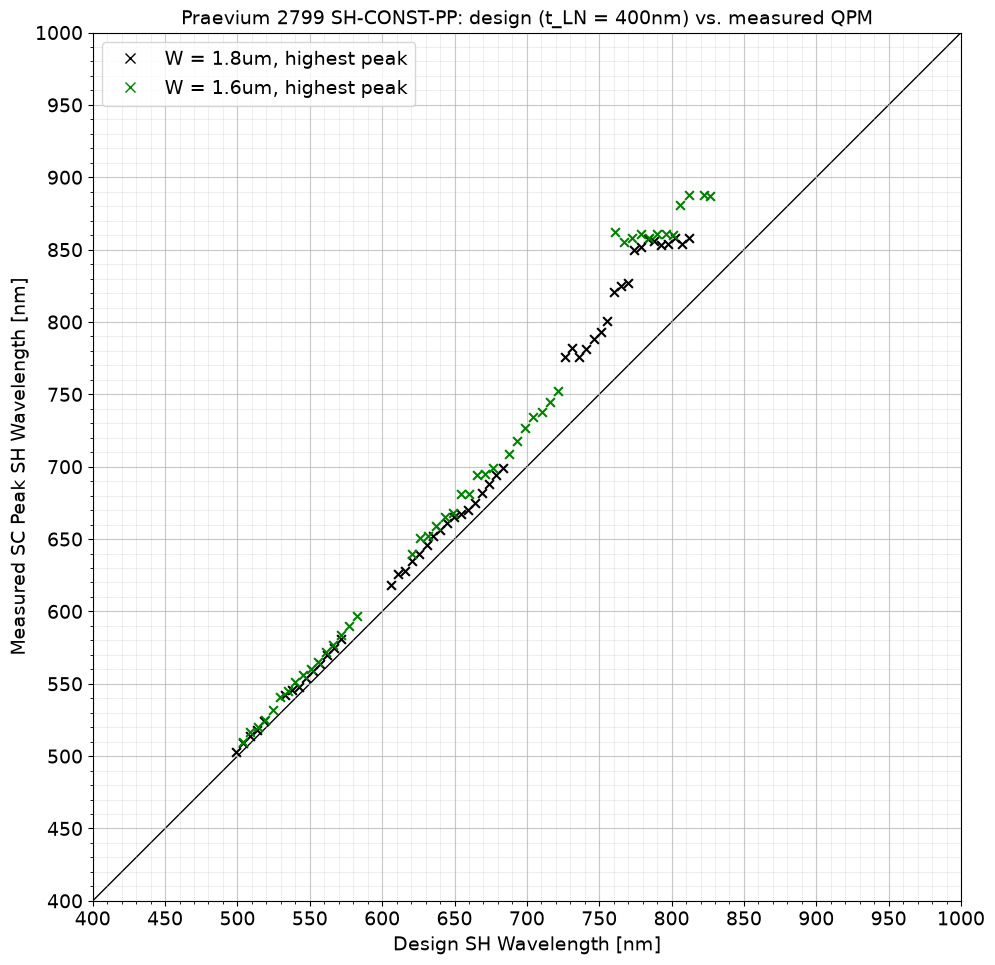

In [74]:
WL_PLOT_MIN_NM, WL_PLOT_MAX_NM = 400, 1000 # SH wavelength range for both axes
WIDTH_COLOR_MAP = {
    "1.8um" : "black",
    "1.6um" : "green",
}

fig, ax = plt.subplots(figsize=(10, 10), tight_layout=True)

for k, (pk_wavs, pk_heights) in device_meas_pks_dict.items():
    if k in OMIT_KEYS:
        continue
    lam_design_SH_nm = device_design_pks_dict[k]
    if np.isnan(lam_design_SH_nm) or len(pk_wavs) == 0:
        print(f"Skipping {k}: design = {lam_design_SH_nm}, {len(pk_wavs)} measured peaks")
        continue
    WG_Width = k.split("-")[1]

    i_main   = np.argmax(pk_heights)                         # Highest peak
    i_others = np.delete(np.arange(len(pk_wavs)), i_main)    # Any lower peaks

    ax.scatter(lam_design_SH_nm, pk_wavs[i_main], marker='x', s=40, color=WIDTH_COLOR_MAP[WG_Width], zorder=3)
    # ax.scatter(np.full(len(i_others), lam_design_SH_nm), pk_wavs[i_others], marker='.', s=15, color='red', zorder=2)

# y = x (perfect agreement)
ax.plot([WL_PLOT_MIN_NM, WL_PLOT_MAX_NM], [WL_PLOT_MIN_NM, WL_PLOT_MAX_NM], linewidth=1, color='black', zorder=1)

# Legend handles (one entry per category instead of one per scatter call)
legend_handles = [plt.Line2D([], [], linestyle='', marker='x', markersize=7, color=c, label=f"W = {w}, highest peak") for w, c in WIDTH_COLOR_MAP.items()]
# legend_handles += [plt.Line2D([], [], linestyle='', marker='.', markersize=7, color='red', label="Lower peaks"),
                #    plt.Line2D([], [], linewidth=1, color='black', label="y = x")]
ax.legend(handles=legend_handles, fontsize=legend_fs, loc='upper left')

# Identical square axes: 50nm major ticks, 10nm minor ticks, major + minor gridlines
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(MultipleLocator(50))
    axis.set_minor_locator(MultipleLocator(10))
ax.set_xlim(WL_PLOT_MIN_NM, WL_PLOT_MAX_NM)
ax.set_ylim(WL_PLOT_MIN_NM, WL_PLOT_MAX_NM)
ax.set_aspect('equal')

ax.grid(True, which='major', linestyle='-', linewidth=0.8, alpha=0.7)
ax.grid(True, which='minor', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_xlabel("Design SH Wavelength [nm]", fontsize=label_fs)
ax.set_ylabel("Measured SC Peak SH Wavelength [nm]", fontsize=label_fs)
ax.tick_params(which='both', labelsize=tick_fs)
ax.set_title(f"Praevium 2799 SH-CONST-PP: design (t_LN = {T_LN_NM}nm) vs. measured QPM", fontsize=title_fs)

plt.show()

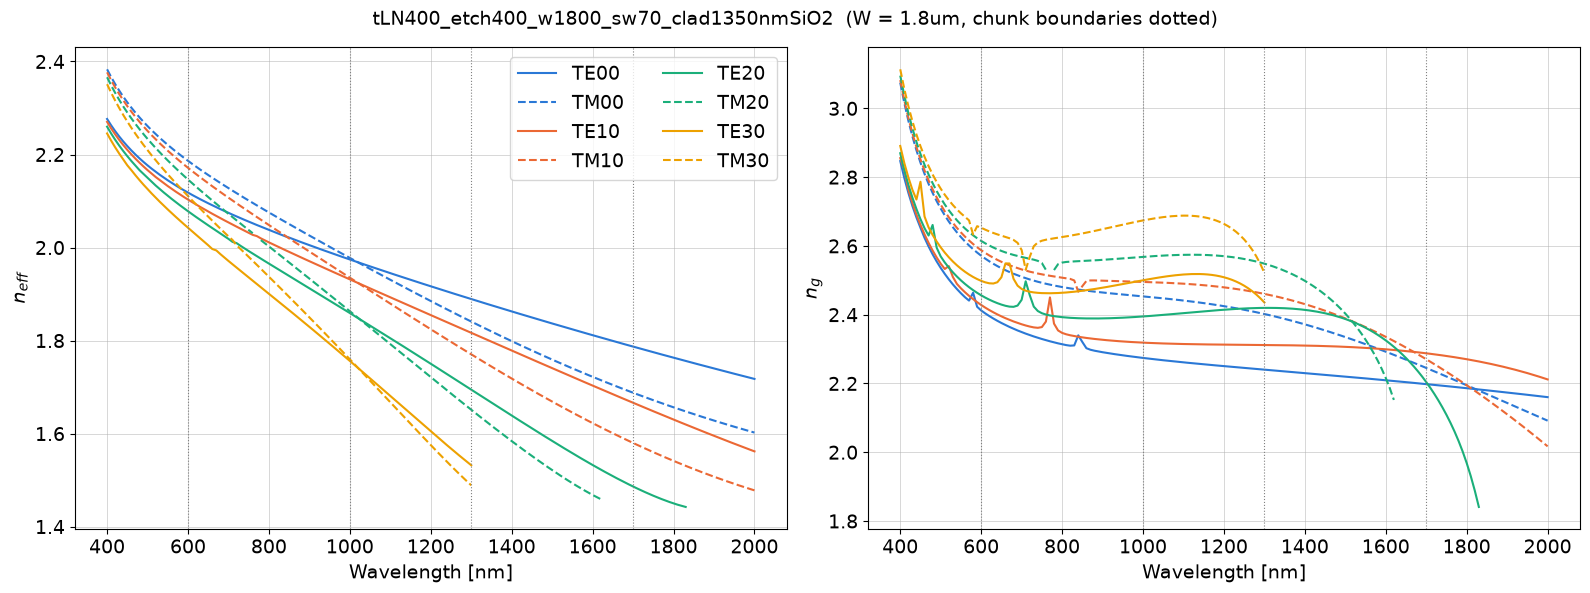

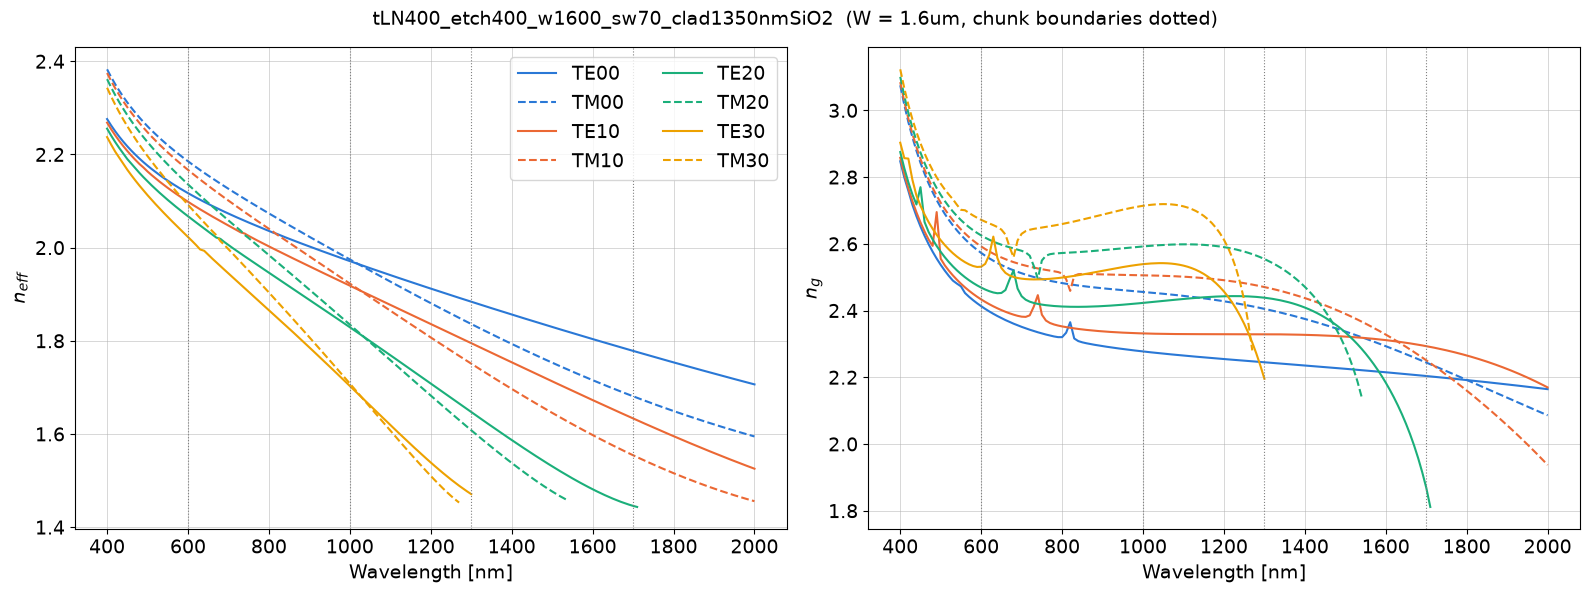

In [75]:
# Mode dispersion (n_eff and n_g vs. wavelength) for each WG width, same layout as the sweep's own *_dispersion.png.
# Uses the solver's per-target mode tracks (*_tracks.csv, next to *_modes.csv): one row per (target mode, wavelength).
MODE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"] # Indexed by the mode's m (TEm0/TMm0)

for WG_Width in WG_Width_of_interest_list:
    w_top_nm    = int(round(float(WG_Width.replace("um", "")) * 1000))
    modes_fpath = get_modes_fpath(T_LN_NM, w_top_nm)
    df_modes    = pd.read_csv(modes_fpath)
    df_tracks   = pd.read_csv(modes_fpath.replace("_modes.csv", "_tracks.csv"))

    lam_all_nm      = np.round(np.sort(df_modes['lam_um'].unique()) * 1000, 6)                                         # Full solved wavelength grid
    chunk_starts_nm = sorted(int(re.search(r"_(\d+)-\d+nm", c).group(1)) for c in df_modes['chunk'].unique())[1:] # From chunk names like "B_0600-1000nm" (skip the first chunk's start)

    fig, axs = plt.subplots(1, 2, figsize=(16, 6), tight_layout=True, sharex=True)

    for target in df_tracks['target'].unique():
        df_t = df_tracks[df_tracks['target'] == target].copy()
        df_t['lam_nm'] = np.round(df_t['lam_um'] * 1000, 6)
        df_t = df_t.set_index('lam_nm').reindex(lam_all_nm) # Wavelengths where the mode wasn't found -> NaN, which breaks the line

        style = dict(color=MODE_COLORS[int(target[2]) % len(MODE_COLORS)], linestyle='-' if target.startswith("TE") else '--', linewidth=1.5, label=target)
        # style = dict(color=MODE_COLORS[int(target[2]) % len(MODE_COLORS)], linestyle='-' if target.startswith("TE") else '--', linewidth=1.5,
        #         marker='o', markersize=0.5, label=target) # Marker at each solved wavelength
        axs[0].plot(lam_all_nm, df_t['neff'].values, **style)
        axs[1].plot(lam_all_nm, df_t['ng'].values, **style)

    for ax in axs:
        for lam_nm in chunk_starts_nm:
            ax.axvline(lam_nm, color='gray', linewidth=0.8, linestyle=':')
        ax.set_xlabel("Wavelength [nm]", fontsize=label_fs)
        ax.tick_params(which='both', labelsize=tick_fs)
        ax.grid(True, which='both', linestyle='-', linewidth=0.5, alpha=0.7)

    axs[0].set_ylabel(r"$n_{eff}$", fontsize=label_fs)
    axs[1].set_ylabel(r"$n_g$", fontsize=label_fs)
    axs[0].legend(ncol=2, fontsize=legend_fs, loc='upper right')

    fig.suptitle(f"{os.path.basename(modes_fpath).replace('_modes.csv', '')}  (W = {WG_Width}, chunk boundaries dotted)", fontsize=title_fs)

    plt.show()